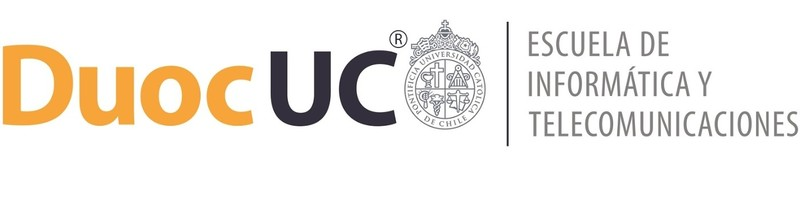

# Spotify Tracks · Evaluación 3  - CRISP-DM

**Integrantes:**
- Cristbal Salcedo
- Diego Ortiz
- Esteban Zenteno  
**Actualización del proyecto:** 6/11/26

En este proyecto buscamos estimar la popularidad de las canciones y encontrar grupos con
características musicales parecidas. Primero revisamos los datos y comparamos modelos base.
Después intentamos mejorar los resultados con validación cruzada, ajuste de parámetros y ensambles.

| Fase | Qué hacemos |
|---|---|
| 1 | Definimos el problema, los objetivos y cómo los vamos a medir. |
| 2 | Revisamos calidad, distribución y relaciones entre variables. |
| 3 | Limpiamos, transformamos y separamos las canciones. |
| 4 | Entrenamos cuatro regresores, cuatro clasificadores y dos modelos de agrupación. |
| 5 | Comparamos los resultados base y explicamos sus límites. |
| 6 | Ajustes, búsquedas con CV, ensambles, sesgos y conclusiones. |

## Fase 1: Business Understanding

---

### Contexto, problema de negocio y alcance

> [NEGOCIO] [OBJETIVOS] [KPIS]



Revisar un catálogo grande canción por canción toma tiempo. Con los datos disponibles queremos
ordenar mejor esa búsqueda: estimar `popularity`, identificar `is_popular = popularity >= 50`
y mostrar perfiles musicales. El valor 50 es una regla del proyecto, no una definición oficial.

| Objetivo | Indicador y criterio |
|---|---|
| Estimar popularidad | MAE menor que la mediana de entrenamiento, revisar también RMSE y R². |
| Detectar canciones populares | F1 a umbral 0,5 como criterio principal. precision, recall, ROC-AUC y AP como complemento. |
| Priorizar una lista de 500 canciones | Precision, Recall y lift frente a la proporción popular de la muestra. |
| Entender el catálogo | Cobertura, tamaños y separación de los grupos, diez atributos para explicar sus diferencias. |
| Comprobar mejoras | Comparar base, parámetros ajustados y ensambles con las mismas canciones, folds y métricas. |

Popularidad no equivale a calidad musical.


## Fase 2 · Conocer los datos

> [DATOS] [CALIDAD] [EDA]


Fuente: [Spotify Tracks Dataset](https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset).
Revisamos faltantes, duplicados y canciones que aparecen con popularidades distintas. Una canción repetida en varios géneros sigue siendo una canción.

El EDA queda en una figura: distribución de popularidad, proporción de clases y asociación con audio.


In [47]:
# [CONFIGURACION PARAMETROS]
# Entorno y configuración general
from pathlib import Path
from time import perf_counter
import hashlib, json, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, Markdown
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.naive_bayes import GaussianNB
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, confusion_matrix,
    precision_recall_curve, roc_curve, silhouette_score, silhouette_samples,
    davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score, pairwise_distances)
from threadpoolctl import threadpool_limits

RANDOM_STATE = 42
POPULARITY_THRESHOLD = 50
MAX_TRAIN_SONGS = 16_000
PROJECT_ROOT = Path.cwd()
ROOT_OUTPUT = PROJECT_ROOT / 'outputs'
OUTPUT_DIR = ROOT_OUTPUT / 'base'
REV_SUP_DIR = ROOT_OUTPUT / 'supervisado'
RC_DIR = ROOT_OUTPUT / 'clustering'
PCA_OUTPUT_DIR = ROOT_OUTPUT / 'pca'
for folder in [OUTPUT_DIR, REV_SUP_DIR, RC_DIR, PCA_OUTPUT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
threadpool_limits(limits=4)
pd.set_option('display.max_columns', 18)
sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')

In [48]:
# [CALIDAD] [DATOS]
# Carga y auditoría mínima
# Colocar dataset.csv junto al notebook para ejecutarlo sin descarga.
df_raw = pd.read_csv(
    "Spotify_Dataset\Spotify_Dataset\Spotify_Tracks_Dataset.csv"
)

text_missing_mask = df_raw[
    ["artists", "album_name", "track_name"]
].isna().any(axis=1)

quality_audit = pd.DataFrame(
    [
        ("Filas con texto faltante", int(text_missing_mask.sum()), "Revisar fila"),
        ("Duplicados exactos excedentes", int(df_raw.drop(columns=["Unnamed: 0"], errors="ignore").duplicated().sum()), "Eliminar excedentes"),
        (
            "Filas pertenecientes a track_id repetido",
            int(df_raw["track_id"].duplicated(keep=False).sum()),
            "Conservar y agrupar después",
        ),
        ("tempo no disponible (nulo o <= 0)", int((df_raw["tempo"].isna() | df_raw["tempo"].le(0)).sum()), "Marcar e imputar dentro del pipeline de entrenamiento"),
        (
            "compás no disponible (nulo o <= 0)",
            int((df_raw["time_signature"].isna() | df_raw["time_signature"].le(0)).sum()),
            "Marcar e imputar categoría dentro del pipeline de entrenamiento",
        ),
        ("duration_ms <= 0", int(df_raw["duration_ms"].le(0).sum()), "Eliminar fila incompleta"),
        (
            "key fuera de 0-11",
            int((~df_raw["key"].between(0, 11)).sum()),
            "Validar dominio, detener si aparecen códigos no contemplados",
        ),
    ],
    columns=["problema", "cantidad", "acción_propuesta"],
)
quality_audit["porcentaje_filas"] = (
    quality_audit["cantidad"].div(len(df_raw)).mul(100).round(3)
)

target_conflicts = df_raw.groupby('track_id').popularity.nunique().gt(1)
display(quality_audit[['problema', 'cantidad', 'porcentaje_filas']])
print(f'Identidades con popularidad contradictoria: {target_conflicts.sum():,}.')

<>:5: SyntaxWarning: "\S" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\S"? A raw string is also an option.
<>:5: SyntaxWarning: "\S" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\S"? A raw string is also an option.
C:\Users\Telet\AppData\Local\Temp\ipykernel_22636\1382655162.py:5: SyntaxWarning: "\S" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\S"? A raw string is also an option.
  "Spotify_Dataset\Spotify_Dataset\Spotify_Tracks_Dataset.csv"


,problema,cantidad,porcentaje_filas
0,Filas con texto faltante,1,0.001
1,Duplicados exactos excedentes,450,0.395
2,Filas pertenecientes a track_id repetido,40900,35.877
3,tempo no disponible (nulo o <= 0),157,0.138
4,compás no disponible (nulo o <= 0),163,0.143
5,duration_ms <= 0,1,0.001
6,key fuera de 0-11,0,0.000


Identidades con popularidad contradictoria: 720.


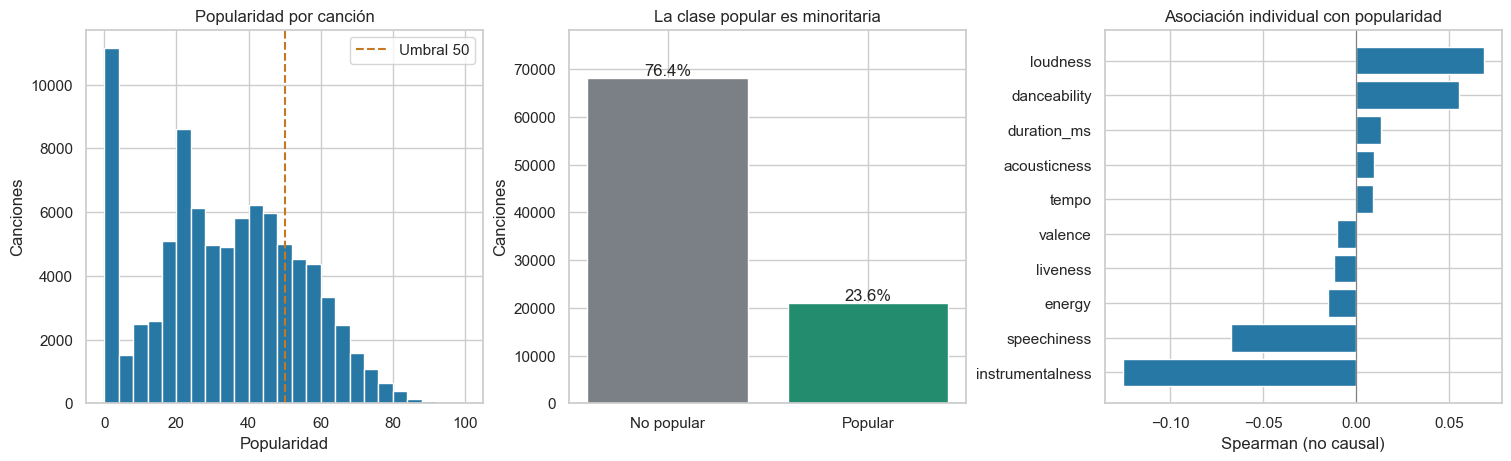

Usamos **89,020 canciones** con objetivo consistente en este resumen. La proporción popular es **23.6%**. Por eso accuracy sola puede resultar engañosa. Las asociaciones individuales no bastan para explicar popularidad, comparamos modelos que también captan relaciones combinadas.

In [49]:
# [EDA GRAFICOS]
# Popularidad, clases y atributos musicales
eda_data = df_raw.drop(columns=['Unnamed: 0'], errors='ignore').drop_duplicates().copy()
eda_data = eda_data.dropna(subset=['track_id', 'artists', 'album_name', 'track_name', 'track_genre'])
eda_data = eda_data.loc[eda_data.duration_ms.gt(0)]
eda_ok = eda_data.groupby('track_id').popularity.nunique().eq(1)
eda_data = eda_data[eda_data.track_id.isin(eda_ok.index[eda_ok])].drop_duplicates('track_id')
eda_audio = ['danceability','energy','loudness','speechiness','acousticness',
             'instrumentalness','liveness','valence','tempo','duration_ms']
eda_corr = eda_data[eda_audio].corrwith(eda_data.popularity, method='spearman').sort_values()
eda_balance = eda_data.popularity.ge(POPULARITY_THRESHOLD).value_counts().sort_index()
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5), layout='constrained')
ax[0].hist(eda_data.popularity, bins=25, color='#2878A5')
ax[0].axvline(50, color='#c67721', ls='--', label='Umbral 50')
ax[0].set(title='Popularidad por canción', xlabel='Popularidad', ylabel='Canciones'); ax[0].legend()
ax[1].bar(['No popular','Popular'], eda_balance.to_numpy(), color=['#7b7f86','#238b6e'])
for pos, count in enumerate(eda_balance):
    ax[1].text(pos, count, f'{count/len(eda_data):.1%}', ha='center', va='bottom')
ax[1].set(title='La clase popular es minoritaria', ylabel='Canciones', ylim=(0,eda_balance.max()*1.15))
ax[2].barh(eda_corr.index, eda_corr.values, color='#2878A5'); ax[2].axvline(0,color='gray',lw=.8)
ax[2].set(title='Asociación individual con popularidad', xlabel='Spearman (no causal)')
fig.savefig(ROOT_OUTPUT/'eda.png',dpi=150,bbox_inches='tight'); plt.show(); plt.close(fig)
display(Markdown(f'Usamos **{len(eda_data):,} canciones** con objetivo consistente en este resumen. '
    f'La proporción popular es **{eda_data.popularity.ge(50).mean():.1%}**. '
    'Por eso accuracy sola puede resultar engañosa. Las asociaciones individuales no bastan '
    'para explicar popularidad, comparamos modelos que también captan relaciones combinadas.'))

## Fase 3 · Preparación de los datos

> [PREPARACION PARTICIONES]



Quitamos duplicados exactos y filas sin identidad o duración válida. Si un `track_id` tiene varias popularidades, lo excluimos para no inventar el objetivo. Los géneros de una misma canción se conservan juntos.

En EP1 exploramos una codificación binaria global. Para los modelos usamos un pipeline: imputación, escalado y vocabulario se aprenden solo con las canciones de entrenamiento de cada ajuste.
Los géneros se codifican con multi-hot y las otras categorías con one-hot. También usamos duración logarítmica y algunos conteos e indicadores de texto, los artistas se separan con `;`.

Las particiones base son 60/20/20 por canción, estratificadas por `is_popular`: 53.412 disponibles
para entrenamiento, 17.804 para validación y 17.804 para prueba. Ajustamos los modelos con las mismas
16.000 canciones. La Fase 6 usa una submuestra común para buscar parámetros y vuelve a ajustar en 16.000.
De las 37.412 restantes fijamos 8.000 como reserva adicional, antes de ver sus métricas supervisadas.
No pasan al ajuste ni a la elección de parámetros. Siguen siendo canciones del mismo catálogo conocido.


In [50]:
# [PREPARACION PARTICIONES]
# Limpieza, unidad de análisis y particiones
rows_initial = len(df_raw)

df_clean = (
    df_raw
    .drop(columns=["Unnamed: 0"], errors="ignore")
    .drop_duplicates()
    .copy()
)
rows_after_exact_duplicates = len(df_clean)

incomplete_identity = df_clean[
    ["track_id", "artists", "album_name", "track_name", "track_genre"]
].isna().any(axis=1)
invalid_duration = df_clean["duration_ms"].le(0)
rows_incomplete = int((incomplete_identity | invalid_duration).sum())
df_clean = df_clean.loc[~(incomplete_identity | invalid_duration)].copy()

# Punto de partida sin estadísticas de imputación aprendidas en todo el dataset.
df_clean_pre_imputation = df_clean.copy()
assert int(quality_audit.loc[quality_audit.problema.eq("Duplicados exactos excedentes"), "cantidad"].iloc[0]) == rows_initial - rows_after_exact_duplicates

source_ep2 = df_clean_pre_imputation.copy()
consistency_ep2 = source_ep2.groupby("track_id").nunique(dropna=False)
conflicting_ids = consistency_ep2.index[consistency_ep2["popularity"].ne(1)]
valid_target_ids = source_ep2.groupby("track_id")["popularity"].agg(
    lambda x: x.notna().all() and x.between(0, 100).all())
eligible_ids = consistency_ep2.index[
    consistency_ep2["popularity"].eq(1) & valid_target_ids]
predictor_source_columns = [c for c in source_ep2.columns
                            if c not in {"track_id", "track_genre", "popularity"}]
predictor_conflicts = consistency_ep2.loc[eligible_ids, predictor_source_columns].gt(1).sum()
assert predictor_conflicts.sum() == 0, "Revisar predictores contradictorios antes de consolidar."

eligible_rows = source_ep2[source_ep2["track_id"].isin(eligible_ids)].copy()
genre_sets = eligible_rows.groupby("track_id")["track_genre"].agg(
    lambda x: tuple(sorted(set(x))))
# Solo después de verificar constancia se conserva el valor observado de cada predictor.
df_model = eligible_rows.drop_duplicates("track_id").copy()
df_model["genres"] = df_model["track_id"].map(genre_sets)
df_model = df_model.sort_values("track_id").reset_index(drop=True)
df_model["is_popular"] = df_model["popularity"].ge(POPULARITY_THRESHOLD)
assert df_model["track_id"].is_unique and df_model["popularity"].between(0, 100).all()
population_ep2 = pd.Series({
    "filas_EP1_limpias": len(source_ep2),
    "canciones_EP1_limpias": source_ep2["track_id"].nunique(),
    "IDs_excluidos_por_conflicto_objetivo": len(conflicting_ids),
    "canciones_EP2": len(df_model),
    "retención_de_canciones_pct": 100 * len(df_model) / source_ep2["track_id"].nunique(),
    "canciones_multigénero": df_model["genres"].map(len).gt(1).sum(),
    "popular_pct_por_canción": 100 * df_model["is_popular"].mean(),
}, name="valor")


all_indices = df_model.index.to_numpy()
train_idx, rest_idx = train_test_split(all_indices, test_size=0.4,
    stratify=df_model["is_popular"], random_state=RANDOM_STATE)
val_idx, test_idx = train_test_split(rest_idx, test_size=0.5,
    stratify=df_model.loc[rest_idx, "is_popular"], random_state=RANDOM_STATE)
if len(train_idx) > MAX_TRAIN_SONGS:
    train_fit_idx, _ = train_test_split(train_idx, train_size=MAX_TRAIN_SONGS,
        stratify=df_model.loc[train_idx, "is_popular"], random_state=RANDOM_STATE)
else:
    train_fit_idx = train_idx
assert not (set(train_idx) & set(val_idx) or set(train_idx) & set(test_idx)
            or set(val_idx) & set(test_idx))
assert set(train_fit_idx).issubset(set(train_idx))

raw_predictors = [c for c in source_ep2.columns
                 if c not in {"track_id", "track_genre", "popularity"}] + ["genres"]
X_train_fit = df_model.loc[train_fit_idx, raw_predictors].copy()
X_val = df_model.loc[val_idx, raw_predictors].copy()
X_test = df_model.loc[test_idx, raw_predictors].copy()
y_train_fit_reg = df_model.loc[train_fit_idx, "popularity"].copy()
y_val_reg = df_model.loc[val_idx, "popularity"].copy()
y_test_reg = df_model.loc[test_idx, "popularity"].copy()
y_train_fit_cls = df_model.loc[train_fit_idx, "is_popular"].copy()
y_val_cls = df_model.loc[val_idx, "is_popular"].copy()
y_test_cls = df_model.loc[test_idx, "is_popular"].copy()
assert not {"popularity", "is_popular", "track_id", "track_genre"} & set(X_train_fit)
split_manifest = df_model[["track_id", "is_popular"]].copy()
split_manifest.insert(0, "row_id", split_manifest.index)
split_manifest["partition"] = "train"
split_manifest.loc[val_idx, "partition"] = "validation"
split_manifest.loc[test_idx, "partition"] = "test"
split_manifest["used_for_fit"] = split_manifest.index.isin(train_fit_idx)
split_summary = pd.DataFrame([
    {"partición": name, "canciones": len(idx),
     "popular_pct": df_model.loc[idx, "is_popular"].mean()*100}
    for name, idx in [("Train disponible", train_idx), ("Train usado (subconjunto)", train_fit_idx),
                      ("Validación", val_idx), ("Prueba reservada", test_idx)]])
display(population_ep2.to_frame().round(2))
display(split_summary.round(2))

,valor
filas_EP1_limpias,113549.00
canciones_EP1_limpias,89740.00
IDs_excluidos_por_conflicto_objetivo,720.00
canciones_EP2,89020.00
retención_de_canciones_pct,99.20
canciones_multigénero,15579.00
popular_pct_por_canción,23.59


,partición,canciones,popular_pct
0,Train disponible,53412,23.59
1,Train usado (subconjunto),16000,23.59
2,Validación,17804,23.59
3,Prueba reservada,17804,23.58


In [51]:
# [PREPARACION PIPELINE METRICAS]
# Variables, transformaciones y métricas
alternate_version_pattern = (
    r"(?i)(?:\bremix(?:ed)?\b|\b(?:radio|club|extended|dance|original)\s+mix\b|"
    r"(?:^|[-(\[]\s*)live(?:\s+(?:at|from|in)\b[^)]*)?\s*(?:$|[)\]])|"
    r"\blive\s+(?:version|recording)\b|\bacoustic\b|\bunplugged\b|"
    r"\binstrumental\b|\bkaraoke\b|\bremaster(?:ed)?\b|\bradio\s+edit\b|"
    r"\bdemo\b|\bsped\s+up\b|\bslowed(?:\s+down)?\b|\bnightcore\b)"
)

AUDIO_COLUMNS = ["danceability", "energy", "loudness", "speechiness", "acousticness",
                 "instrumentalness", "liveness", "valence", "tempo"]
ENGINEERED_NUMERIC = ["artist_count", "track_name_word_count", "album_name_word_count",
                      "movement_intensity", "positive_energy", "acoustic_instrumental"]
ENGINEERED_FLAGS = ["has_featured_artist", "is_alternate_version", "is_soundtrack_album"]

class FeatureBuilder(BaseEstimator, TransformerMixin):
    def __init__(self, engineered=True):
        self.engineered = engineered

    def fit(self, X, y=None):
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        out = X[AUDIO_COLUMNS].astype(float).copy()
        out["tempo_was_unavailable"] = (X["tempo"].isna() | X["tempo"].le(0)).astype(int)
        out["meter_was_unavailable"] = (X["time_signature"].isna() | X["time_signature"].le(0)).astype(int)
        out["tempo"] = out["tempo"].where(out["tempo"].gt(0))
        out["log_duration_min"] = np.log1p(X["duration_ms"] / 60_000)
        out["is_explicit"] = X["explicit"].astype(int)
        out["tonality"] = X["key"].astype(str) + "_" + X["mode"].astype(str)
        out["meter"] = X["time_signature"].map(lambda x: str(int(x)) if pd.notna(x) and x > 0 else np.nan)
        out["genres"] = X["genres"]
        if self.engineered:
            artist = X["artists"].astype("string")
            title = X["track_name"].astype("string")
            album = X["album_name"].astype("string")
            out["artist_count"] = artist.str.count(";").add(1).astype(float)
            out["track_name_word_count"] = title.str.findall(r"\b[\w']+\b").str.len().astype(float)
            out["album_name_word_count"] = album.str.findall(r"\b[\w']+\b").str.len().astype(float)
            out["has_featured_artist"] = title.str.contains(r"(?i)\b(?:feat(?:uring)?|ft)\.?\s+", na=False).astype(int)
            out["is_alternate_version"] = title.str.contains(alternate_version_pattern, regex=True, na=False).astype(int)
            out["is_soundtrack_album"] = album.str.contains(
                r"(?i)\b(?:soundtrack|motion\s+picture|original\s+score|banda\s+sonora)\b", na=False).astype(int)
            out["movement_intensity"] = X["danceability"] * X["energy"]
            out["positive_energy"] = X["valence"] * X["energy"]
            out["acoustic_instrumental"] = X["acousticness"] * X["instrumentalness"]
            out["speech_profile"] = np.select(
                [X["speechiness"].lt(.33), X["speechiness"].le(.66)],
                ["mostly_music", "music_and_speech"], default="spoken_word")
        return out

class MultiGenreEncoder(BaseEstimator, TransformerMixin):
    """Vocabulario aprendido en train, una canción activa todos sus géneros conocidos."""
    def fit(self, X, y=None):
        self.classes_ = sorted({g for genres in X.iloc[:, 0] for g in genres})
        self.mapping_ = {g: i for i, g in enumerate(self.classes_)}
        return self

    def transform(self, X):
        encoded = np.zeros((len(X), len(self.classes_)), dtype=np.float64)
        for i, genres in enumerate(X.iloc[:, 0]):
            for genre in genres:
                j = self.mapping_.get(genre)
                if j is not None:
                    encoded[i, j] = 1.0
        return encoded

    def get_feature_names_out(self, input_features=None):
        return np.asarray(["genre_" + g for g in self.classes_], dtype=object)

def make_model_pipeline(estimator, engineered=True, include_genres=True):
    numeric = AUDIO_COLUMNS + ["log_duration_min"] + (ENGINEERED_NUMERIC if engineered else [])
    flags = ["is_explicit", "tempo_was_unavailable", "meter_was_unavailable"]
    categorical = ["tonality", "meter"]
    if engineered:
        flags += ENGINEERED_FLAGS
        categorical += ["speech_profile"]
    transformers = [
        ("numeric", Pipeline([("impute", SimpleImputer(strategy="median")),
                              ("scale", StandardScaler())]), numeric),
        ("flags", "passthrough", flags),
        ("categorical", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                                  ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), categorical),
    ]
    if include_genres:
        transformers.append(("genres", MultiGenreEncoder(), ["genres"]))
    return Pipeline([("features", FeatureBuilder(engineered=engineered)),
                     ("prepare", ColumnTransformer(transformers, remainder="drop", sparse_threshold=0)),
                     ("model", estimator)])

def regression_scores(y, pred):
    return {"MAE": mean_absolute_error(y, pred),
            "RMSE": np.sqrt(mean_squared_error(y, pred)), "R2": r2_score(y, pred)}

def classification_scores(y, pred, prob):
    return {"Accuracy": accuracy_score(y, pred),
            "BalancedAccuracy": balanced_accuracy_score(y, pred),
            "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred, zero_division=0),
            "F1": f1_score(y, pred, zero_division=0),
            "ROC_AUC": roc_auc_score(y, prob),
            "AP": average_precision_score(y, prob)}

## Fase 4 · Modelos base

> [MODELOS] [PARAMETROS] [ENTRENAMIENTO]


Probamos cuatro familias por tarea con la misma preparación y presupuesto. Lineal y logística son referencias sencillas: árbol y Random Forest permiten relaciones más complejas, SVR usa kernel RBF, KNN compara vecinos y Naive Bayes trabaja con supuestos de independencia entre atributos.

La elección usa MAE para regresión y F1 a 0,5 para clasificación. En la Fase 6 haremos la búsqueda con validación cruzada y los ensambles, no mezclamos
esas mejoras con el resultado base.


In [52]:
# [PARAMETROS REGRESION CLASIFICACION]
# Configuraciones de los ocho modelos
reg_candidates = {
    "Regresión lineal": [("mínimos cuadrados", LinearRegression())],
    "Árbol de regresión": [
        ("depth=6; leaf=20", DecisionTreeRegressor(max_depth=6, min_samples_leaf=20, random_state=RANDOM_STATE)),
        ("depth=12; leaf=10", DecisionTreeRegressor(max_depth=12, min_samples_leaf=10, random_state=RANDOM_STATE)),
        ("depth=None; leaf=10", DecisionTreeRegressor(min_samples_leaf=10, random_state=RANDOM_STATE)),
    ],
    "Random Forest regresión": [
        ("180 trees; depth=16; leaf=5", RandomForestRegressor(n_estimators=180, max_depth=16, min_samples_leaf=5, n_jobs=4, random_state=RANDOM_STATE)),
        ("180 trees; depth=None; leaf=2", RandomForestRegressor(n_estimators=180, min_samples_leaf=2, n_jobs=4, random_state=RANDOM_STATE)),
    ],
    "SVM regresión (RBF)": [
        ("C=10; epsilon=3; gamma=scale", SVR(C=10, epsilon=3, gamma="scale", cache_size=512)),
        ("C=40; epsilon=3; gamma=scale", SVR(C=40, epsilon=3, gamma="scale", cache_size=512)),
    ],
}

cls_candidates = {
    "KNN": [
        ("k=15; weights=distance", KNeighborsClassifier(n_neighbors=15, weights="distance", n_jobs=4)),
        ("k=51; weights=uniform", KNeighborsClassifier(n_neighbors=51, weights="uniform", n_jobs=4)),
    ],
    "Random Forest clasificación": [
        ("180 trees; depth=16; leaf=4; balanced", RandomForestClassifier(n_estimators=180, max_depth=16, min_samples_leaf=4, class_weight="balanced_subsample", n_jobs=4, random_state=RANDOM_STATE)),
        ("180 trees; depth=None; leaf=1; balanced", RandomForestClassifier(n_estimators=180, min_samples_leaf=1, class_weight="balanced_subsample", n_jobs=4, random_state=RANDOM_STATE)),
    ],
    "Naive Bayes gaussiano": [
        ("var_smoothing=1e-8", GaussianNB(var_smoothing=1e-8)),
        ("var_smoothing=1e-2", GaussianNB(var_smoothing=1e-2)),
    ],
    "Regresión logística": [
        ("C=0.1; balanced", LogisticRegression(C=.1, class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE)),
        ("C=1; balanced", LogisticRegression(C=1, class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE)),
    ],
}

model_parameters = pd.DataFrame([
    {'tarea': task, 'modelo': name, 'configuración': config}
    for task, grid in [('Regresión', reg_candidates), ('Clasificación', cls_candidates)]
    for name, candidates in grid.items() for config, _ in candidates
])
display(model_parameters)

,tarea,modelo,configuración
0,Regresión,Regresión lineal,mínimos cuadrados
1,Regresión,Árbol de regresión,depth=6; leaf=20
2,Regresión,Árbol de regresión,depth=12; leaf=10
3,Regresión,Árbol de regresión,depth=None; leaf=10
4,Regresión,Random Forest regresión,180 trees; depth=16; leaf=5
5,Regresión,Random Forest regresión,180 trees; depth=None; leaf=2
6,Regresión,SVM regresión (RBF),C=10; epsilon=3; gamma=scale
7,Regresión,SVM regresión (RBF),C=40; epsilon=3; gamma=scale
8,Clasificación,KNN,k=15; weights=distance
9,Clasificación,KNN,k=51; weights=uniform


In [53]:
# [ENTRENAMIENTO REGRESION CLASIFICACION]
# Ajuste común y selección histórica
dummy_reg = DummyRegressor(strategy="median").fit(X_train_fit, y_train_fit_reg)
dummy_cls = DummyClassifier(strategy="prior", random_state=RANDOM_STATE).fit(X_train_fit, y_train_fit_cls)
baseline_validation_reg = regression_scores(y_val_reg, dummy_reg.predict(X_val))
baseline_validation_cls = classification_scores(y_val_cls, dummy_cls.predict(X_val),
                                                dummy_cls.predict_proba(X_val)[:, 1])
reg_fitted, reg_rows, reg_best_rows = {}, [], []
for name, candidates in reg_candidates.items():
    best_key, best_pipe, best_row = None, None, None
    for config, estimator in candidates:
        started = perf_counter()
        pipe = make_model_pipeline(estimator).fit(X_train_fit, y_train_fit_reg)
        elapsed = perf_counter() - started
        scores = regression_scores(y_val_reg, pipe.predict(X_val))
        row = {"model": name, "config": config, **scores, "fit_seconds": elapsed,
               "train_songs": len(X_train_fit)}
        reg_rows.append(row)
        key = (scores["MAE"], scores["RMSE"])
        if best_key is None or key < best_key:
            best_key, best_pipe, best_row = key, pipe, row
        print(f"{name} | {config} | validación MAE={scores['MAE']:.3f} | ajuste {elapsed:.1f}s", flush=True)
    reg_fitted[name] = best_pipe
    reg_best_rows.append(best_row)
reg_search = pd.DataFrame(reg_rows)
reg_validation = pd.DataFrame(reg_best_rows).set_index("model").sort_values(["MAE", "RMSE"])
selected_reg_name = reg_validation.index[0]
cls_fitted, cls_rows, cls_best_rows = {}, [], []
for name, candidates in cls_candidates.items():
    best_key, best_pipe, best_row = None, None, None
    for config, estimator in candidates:
        started = perf_counter()
        pipe = make_model_pipeline(estimator).fit(X_train_fit, y_train_fit_cls)
        elapsed = perf_counter() - started
        prob = pipe.predict_proba(X_val)[:, 1]
        scores = classification_scores(y_val_cls, prob >= .5, prob)
        row = {"model": name, "config": config, **scores, "fit_seconds": elapsed,
               "train_songs": len(X_train_fit)}
        cls_rows.append(row)
        key = (-scores["F1"], -scores["AP"])
        if best_key is None or key < best_key:
            best_key, best_pipe, best_row = key, pipe, row
        print(f"{name} | {config} | validación F1={scores['F1']:.3f} | ajuste {elapsed:.1f}s", flush=True)
    cls_fitted[name] = best_pipe
    cls_best_rows.append(best_row)
cls_search = pd.DataFrame(cls_rows)
cls_validation = pd.DataFrame(cls_best_rows).set_index("model").sort_values(["F1", "AP"], ascending=False)
selected_cls_name = cls_validation.index[0]
selection_record = {"regression": selected_reg_name, "classification": selected_cls_name,
    "regression_config": reg_validation.loc[selected_reg_name, "config"],
    "classification_config": cls_validation.loc[selected_cls_name, "config"],
    "classification_threshold": .5, "popular_threshold": POPULARITY_THRESHOLD,
    "selection_data": "validation", "train_songs": len(X_train_fit),
    "validation_songs": len(X_val), "test_songs": len(X_test),
    "random_state": RANDOM_STATE, "python": platform.python_version(), "sklearn": sklearn.__version__}
(OUTPUT_DIR / "frozen_selection.json").write_text(json.dumps(selection_record, indent=2, ensure_ascii=False), encoding="utf-8")
print("Ajuste completo: 8 configuraciones por tarea; selección histórica reproducida con validación.")

Regresión lineal | mínimos cuadrados | validación MAE=11.928 | ajuste 0.3s
Árbol de regresión | depth=6; leaf=20 | validación MAE=15.807 | ajuste 0.4s
Árbol de regresión | depth=12; leaf=10 | validación MAE=14.760 | ajuste 0.5s
Árbol de regresión | depth=None; leaf=10 | validación MAE=12.868 | ajuste 1.1s
Random Forest regresión | 180 trees; depth=16; leaf=5 | validación MAE=13.805 | ajuste 11.0s
Random Forest regresión | 180 trees; depth=None; leaf=2 | validación MAE=11.096 | ajuste 24.7s
SVM regresión (RBF) | C=10; epsilon=3; gamma=scale | validación MAE=11.332 | ajuste 16.9s
SVM regresión (RBF) | C=40; epsilon=3; gamma=scale | validación MAE=10.866 | ajuste 20.4s
KNN | k=15; weights=distance | validación F1=0.333 | ajuste 0.2s
KNN | k=51; weights=uniform | validación F1=0.182 | ajuste 0.2s
Random Forest clasificación | 180 trees; depth=16; leaf=4; balanced | validación F1=0.557 | ajuste 1.6s
Random Forest clasificación | 180 trees; depth=None; leaf=1; balanced | validación F1=0.444 

In [54]:
# [ENTRENAMIENTO ABLACION VARIABLES]
# Ablación e importancia por permutación
ablation_rows = []
for task, fitted, yfit, yvalid, family in [
    ("Regresión", reg_fitted, y_train_fit_reg, y_val_reg, "Random Forest regresión"),
    ("Clasificación", cls_fitted, y_train_fit_cls, y_val_cls, "Random Forest clasificación")]:
    for variant, engineered, genres in [("Completa", True, True),
                                         ("Sin ingeniería", False, True),
                                         ("Sin géneros", True, False)]:
        if variant == "Completa":
            ab_pipe = fitted[family]
        else:
            ab_pipe = make_model_pipeline(clone(fitted[family].named_steps["model"]),
                engineered=engineered, include_genres=genres).fit(X_train_fit, yfit)
        if task == "Regresión":
            metrics = regression_scores(yvalid, ab_pipe.predict(X_val))
        else:
            probability = ab_pipe.predict_proba(X_val)[:, 1]
            metrics = classification_scores(yvalid, probability >= .5, probability)
        ablation_rows.append({"tarea": task, "representación": variant, **metrics})
ablation = pd.DataFrame(ablation_rows)
perm_indices = X_val.sample(n=min(2000, len(X_val)), random_state=RANDOM_STATE).index
def score_f1_fixed_threshold(estimator, data, target):
    return f1_score(target, estimator.predict_proba(data)[:, 1] >= .5, zero_division=0)

perm_result = permutation_importance(cls_fitted[selected_cls_name], X_val.loc[perm_indices],
    y_val_cls.loc[perm_indices], scoring=score_f1_fixed_threshold, n_repeats=3, random_state=RANDOM_STATE, n_jobs=1)
permutation_validation = pd.DataFrame({"variable": X_val.columns,
    "caída_F1_media": perm_result.importances_mean, "desviación_repeticiones": perm_result.importances_std})
permutation_validation = permutation_validation.sort_values("caída_F1_media", ascending=False)

### Segmentación musical · Diseño común


> [CLUSTERING] [PARAMETROS]


Usamos las mismas **6.000 canciones**, diez atributos acústicos estandarizados y una base fija de 2.000 para silueta. Popularidad, géneros e identidades no intervienen en el agrupamiento.

K-Means prueba **k=2…12**. DBSCAN prueba **150 configuraciones** entre 10D y PCA7, con `min_samples = 3, 5, 8, 11, 20`, radios absolutos y cuantiles de distancia a vecinos.
Una solución elegible requiere 2–12 grupos, ≥70% de cobertura, grupo menor ≥1% y mayor ≤90% de las canciones asignadas. Son reglas exploratorias para este uso, no leyes universales.
El ruido se informa y se excluye de las métricas internas.

In [55]:
# [CLUSTERING] [PREPARACION] [PARAMETROS]
# Muestra acústica y búsqueda de parámetros
cl_rng = np.random.default_rng(RANDOM_STATE)
cl_indices = np.sort(cl_rng.choice(len(df_model), min(6000, len(df_model)), replace=False))
cl_sample = df_model.iloc[cl_indices].copy().reset_index(drop=True)
assert cl_sample["track_id"].is_unique, "La muestra requiere una fila por canción."

cl_audio_columns = [
    "danceability", "energy", "loudness", "speechiness", "acousticness",
    "instrumentalness", "liveness", "valence", "tempo",
]
cl_features = cl_sample[cl_audio_columns].apply(pd.to_numeric, errors="coerce").copy()
cl_features.loc[cl_features["tempo"] <= 0, "tempo"] = np.nan
cl_duration = pd.to_numeric(cl_sample["duration_ms"], errors="coerce")
cl_features["log_duration"] = np.log1p(cl_duration.where(cl_duration > 0))
cl_features = cl_features.replace([np.inf, -np.inf], np.nan)
assert not cl_features.isna().all().any(), "No puede haber atributos completamente vacíos."
assert not {"popularity", "is_popular", "track_genre", "genres", "track_id"} & set(cl_features)

cl_preprocessor = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
cl_X = cl_preprocessor.fit_transform(cl_features).astype(np.float64)
cl_feature_names = list(cl_features.columns)
assert cl_X.shape[1] == 10 and np.isfinite(cl_X).all()
# La base de hasta 2.000 observaciones para silhouette es idéntica en toda la búsqueda.
cl_metric_indices = np.sort(cl_rng.choice(len(cl_X), min(2000, len(cl_X)), replace=False))
cl_preparation = pd.DataFrame({
    "faltantes_imputados": cl_features.isna().sum(),
    "mediana_imputacion": cl_preprocessor.named_steps["simpleimputer"].statistics_,
    "media_escalador": cl_preprocessor.named_steps["standardscaler"].mean_,
    "escala": cl_preprocessor.named_steps["standardscaler"].scale_,
}, index=cl_feature_names)

assert cl_X.shape == (6000, 10) and np.isfinite(cl_X).all()
assert len(cl_sample) == 6000 and cl_sample.track_id.is_unique
assert len(cl_metric_indices) == 2000
assert not {'popularity','is_popular','track_genre','genres'} & set(cl_feature_names)
rc_started = perf_counter()
rc_pca = PCA(n_components=7, svd_solver='full', whiten=False)
rc_spaces = {'Original10D': np.asarray(cl_X, dtype=float), 'PCA7': rc_pca.fit_transform(cl_X)}
rc_distances = {}
with threadpool_limits(limits=2):
    for rc_rep, rc_matrix in rc_spaces.items():
        rc_d = pairwise_distances(rc_matrix[cl_metric_indices], metric='euclidean')
        np.fill_diagonal(rc_d, 0.)
        rc_distances[rc_rep] = rc_d
rc_protocol = {
    'songs': 6000, 'metric_base': 2000, 'seed': 42, 'features': list(cl_feature_names),
    'representations': ['Original10D','PCA7'],
    'pca7_variance': float(rc_pca.explained_variance_ratio_.sum()),
    'k_values': list(range(2,13)), 'kmeans_n_init': 20,
    'dbscan_min_samples': [3,5,8,11,20],
    'eps_absolute': [.30,.50,.75,1.,1.25,1.50],
    'eps_quantiles': [.01,.025,.05,.10,.20,.40,.60,.75,.90],
    'operational_rules': {'groups':[2,12],'coverage_min':.70,'min_assigned_pct':1.,'max_assigned_pct':90.},
    'selection_detail': 'Best silhouette among eligible Original10D KMeans with k >= 3; editorial alternative, not global winner',
    'stability': '5 initializations; 5 samples of 80%; scaling and PCA held fixed; KMeans ARI on omitted 20%',
    'dbscan_subsample_stability': 'ARI on shared assigned songs; report coverage Jaccard and degeneracy; no predict for DBSCAN',
}
(RC_DIR/'protocol.json').write_text(json.dumps(rc_protocol,ensure_ascii=False,indent=2),encoding='utf-8')

display(pd.Series(rc_protocol, name='valor').to_frame())

,valor
songs,6000
metric_base,2000
seed,42
features,"[danceability, energy, loudness, speechiness, ..."
representations,"[Original10D, PCA7]"
pca7_variance,0.909503
k_values,"[2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]"
kmeans_n_init,20
dbscan_min_samples,"[3, 5, 8, 11, 20]"
eps_absolute,"[0.3, 0.5, 0.75, 1.0, 1.25, 1.5]"


In [56]:
# [CLUSTERING] [ENTRENAMIENTO]
# Entrenamiento de K-Means y DBSCAN
def rc_measure(labels, representation):
    labels=np.asarray(labels)
    assigned=labels>=0
    counts=pd.Series(labels[assigned]).value_counts()
    metric_mask=assigned[cl_metric_indices]
    metric_labels=labels[cl_metric_indices][metric_mask]
    n_groups=len(counts)
    sil=db=ch=np.nan
    n_metric_groups=len(np.unique(metric_labels))
    if 1 < n_metric_groups < len(metric_labels):
        d=rc_distances[representation][np.ix_(metric_mask,metric_mask)]
        sil=float(silhouette_score(d,metric_labels,metric='precomputed'))
    if 1 < n_groups < assigned.sum():
        db=float(davies_bouldin_score(rc_spaces[representation][assigned],labels[assigned]))
        ch=float(calinski_harabasz_score(rc_spaces[representation][assigned],labels[assigned]))
    mn=100*counts.min()/assigned.sum() if len(counts) else 0.
    mx=100*counts.max()/assigned.sum() if len(counts) else 0.
    failures=[]
    if not 2<=n_groups<=12: failures.append('grupos fuera de 2–12')
    if assigned.mean()<.70: failures.append('cobertura <70%')
    if mn<1.: failures.append('grupo menor <1%')
    if mx>90.: failures.append('grupo mayor >90%')
    if not np.isfinite(sil): failures.append('silueta no definida en base métrica')
    return {'n_clusters':n_groups,'coverage':float(assigned.mean()),'noise_pct':float(100*(~assigned).mean()),
            'n_assigned':int(assigned.sum()),'n_silhouette':len(metric_labels),'metric_clusters':n_metric_groups,
            'all_clusters_in_metric':n_metric_groups==n_groups,'silhouette':sil,'davies_bouldin':db,
            'calinski_harabasz':ch,'min_cluster_pct_assigned':float(mn),'max_cluster_pct_assigned':float(mx),
            'eligible':not failures,'rule_failures':'; '.join(failures) if failures else 'cumple'}

rc_records,rc_labels,rc_models,rc_kdistances=[],{},{},{}
with threadpool_limits(limits=2):
    for rc_k in rc_protocol['k_values']:
        rc_id=f'Original10D_KMeans_k{rc_k}'
        rc_model=KMeans(n_clusters=rc_k,n_init=20,random_state=42,algorithm='lloyd')
        rc_t=perf_counter();rc_y=rc_model.fit_predict(cl_X)
        rc_labels[rc_id]=rc_y;rc_models[rc_id]=rc_model
        rc_records.append(dict(configuration=rc_id,representation='Original10D',algorithm='K-Means',k=rc_k,
            eps=np.nan,min_samples=np.nan,eps_source='none',eps_quantile=np.nan,
            fit_seconds=perf_counter()-rc_t,inertia=float(rc_model.inertia_),**rc_measure(rc_y,'Original10D')))
    for rc_rep,rc_matrix in rc_spaces.items():
        for rc_m in rc_protocol['dbscan_min_samples']:
            rc_dist=NearestNeighbors(n_neighbors=rc_m,n_jobs=2).fit(rc_matrix).kneighbors(rc_matrix)[0][:,-1]
            rc_kdistances[(rc_rep,rc_m)]=np.sort(rc_dist)
            rc_eps_specs=[(v,'absolute',np.nan) for v in rc_protocol['eps_absolute']]
            rc_eps_specs += [(max(float(np.quantile(rc_dist,q)),1e-8),'quantile',q) for q in rc_protocol['eps_quantiles']]
            for rc_j,(rc_eps,rc_source,rc_q) in enumerate(rc_eps_specs):
                rc_id=f'{rc_rep}_DBSCAN_m{rc_m}_{rc_source}_{rc_j:02}'
                rc_model=DBSCAN(eps=rc_eps,min_samples=rc_m,algorithm='ball_tree',n_jobs=2)
                rc_t=perf_counter();rc_y=rc_model.fit_predict(rc_matrix)
                rc_labels[rc_id]=rc_y
                rc_records.append(dict(configuration=rc_id,representation=rc_rep,algorithm='DBSCAN',k=np.nan,
                    eps=rc_eps,min_samples=rc_m,eps_source=rc_source,eps_quantile=rc_q,
                    fit_seconds=perf_counter()-rc_t,inertia=np.nan,**rc_measure(rc_y,rc_rep)))
        print(f'{rc_rep}: 75 configuraciones DBSCAN evaluadas, incluidos radios y min_samples pequeños.')
rc_search=pd.DataFrame(rc_records)
rc_label_frame=pd.DataFrame(rc_labels)
rc_label_frame.insert(0,'track_id',cl_sample.track_id.to_numpy())
rc_km=rc_search.query("algorithm == 'K-Means'").copy()
rc_db=rc_search.query("algorithm == 'DBSCAN'").copy()
rc_overall=rc_km[rc_km.eligible].sort_values(['silhouette','k'],ascending=[False,True]).iloc[0]
rc_detail_pool=rc_km[rc_km.eligible & rc_km.k.ge(3)]
assert len(rc_detail_pool), 'No hay alternativa multigrupo con las reglas declaradas.'
rc_detail=rc_detail_pool.sort_values(['silhouette','k'],ascending=[False,True]).iloc[0]
rc_compare_ids=list(dict.fromkeys(['Original10D_KMeans_k2',rc_overall.configuration,rc_detail.configuration]))

Original10D: 75 configuraciones DBSCAN evaluadas, incluidos radios y min_samples pequeños.
PCA7: 75 configuraciones DBSCAN evaluadas, incluidos radios y min_samples pequeños.


## Fase 5 · Evaluación de los modelos base


> [RESULTADOS] [METRICAS]


Reunimos los resultados, errores y diferencias entre criterios. Las métricas de validación y prueba de EP2 ya se conocían: volver a calcularlas no las convierte en una prueba nueva.
Esta fase deja una referencia clara para la mejora de Fase 6. La alternativa de Random Forest por ROC-AUC se revisa en validación, manteniendo el umbral 0,5.


In [57]:
# [EVALUACION PREDICCIONES METRICAS]
# Predicciones de prueba y cálculo unificado
from sklearn.metrics import confusion_matrix, precision_recall_curve, roc_curve

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def save_evaluation_figure(fig, filename):
    '''Persistir el mismo gráfico que se muestra en el notebook.'''
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / filename, dpi=160, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)

def positive_probability(model, X):
    '''Localizar explícitamente la columna de la clase positiva.'''
    classes = np.asarray(model.classes_)
    column = int(np.flatnonzero(classes == 1)[0])
    return np.asarray(model.predict_proba(X)[:, column], dtype=float)

# Congelar los nombres elegidos antes de consultar las métricas de prueba.
evaluation_selected_reg = selected_reg_name
evaluation_selected_cls = selected_cls_name
assert evaluation_selected_reg in reg_fitted
assert evaluation_selected_cls in cls_fitted
assert X_test.index.is_unique and X_val.index.is_unique
assert X_test.index.equals(y_test_reg.index)
assert X_test.index.equals(y_test_cls.index)

_reg_models_for_test = {**reg_fitted, "Baseline: mediana": dummy_reg}
_cls_models_for_test = {**cls_fitted, "Baseline: prior": dummy_cls}

# ÚNICO punto del notebook donde estos modelos predicen sobre X_test.
reg_test_predictions = {
    name: np.asarray(model.predict(X_test), dtype=float)
    for name, model in _reg_models_for_test.items()
}
cls_test_probabilities = {
    name: positive_probability(model, X_test)
    for name, model in _cls_models_for_test.items()
}
cls_test_predictions = {
    name: (probabilities >= 0.5).astype(int)
    for name, probabilities in cls_test_probabilities.items()
}

reg_test = pd.DataFrame.from_dict({
    name: regression_scores(y_test_reg, prediction)
    for name, prediction in reg_test_predictions.items()
}, orient="index").rename_axis("model")
cls_test = pd.DataFrame.from_dict({
    name: classification_scores(
        y_test_cls, cls_test_predictions[name], probabilities
    )
    for name, probabilities in cls_test_probabilities.items()
}, orient="index").rename_axis("model")

# Guardar valores reales, predicciones y probabilidades para trazabilidad.
reg_test_export = pd.DataFrame({
    "row_id": X_test.index,
    "track_id": df_model.loc[X_test.index, "track_id"].to_numpy(),
    "popularity_real": np.asarray(y_test_reg),
    **reg_test_predictions,
})
cls_test_export = pd.DataFrame({
    "row_id": X_test.index,
    "track_id": df_model.loc[X_test.index, "track_id"].to_numpy(),
    "is_popular_real": np.asarray(y_test_cls, dtype=int),
    **{f"{name}__clase": value for name, value in cls_test_predictions.items()},
    **{f"{name}__probabilidad": value for name, value in cls_test_probabilities.items()},
})
rev_original_selection = dict(selection_record)
rev_reg_names = list(reg_validation.index)
rev_cls_names = list(cls_validation.index)
assert len(rev_reg_names) == len(rev_cls_names) == 4
assert X_test.index.equals(y_test_reg.index) and X_test.index.equals(y_test_cls.index)
assert X_val.index.equals(y_val_reg.index) and X_val.index.equals(y_val_cls.index)
assert not set(X_train_fit.index) & set(X_val.index)
assert not set(X_train_fit.index) & set(X_test.index)
assert not set(X_val.index) & set(X_test.index)
assert set(np.unique(np.asarray(y_val_cls, dtype=int))) == {0, 1}
assert set(np.unique(np.asarray(y_test_cls, dtype=int))) == {0, 1}

rev_reg_scores = regression_scores

def rev_cls_scores(y, s):
    y, s = np.asarray(y, dtype=int), np.asarray(s, dtype=float)
    assert y.shape == s.shape and np.isfinite(s).all()
    p = s >= .5
    return {"F1": f1_score(y, p, zero_division=0),
            "Precision": precision_score(y, p, zero_division=0),
            "Recall": recall_score(y, p, zero_division=0),
            "ROC_AUC": roc_auc_score(y, s), "AP": average_precision_score(y, s),
            "prevalencia": float(y.mean()), "fraccion_revision": float(p.mean())}

rev_reg_test = pd.DataFrame.from_dict({
    name: rev_reg_scores(y_test_reg, reg_test_predictions[name]) for name in rev_reg_names
}, orient="index").rename_axis("model")
rev_cls_test = pd.DataFrame.from_dict({
    name: rev_cls_scores(y_test_cls, cls_test_probabilities[name]) for name in rev_cls_names
}, orient="index").rename_axis("model")
rev_reg_val = reg_validation.loc[rev_reg_names, ["MAE", "RMSE", "R2"]].copy()
rev_cls_val = cls_validation.loc[rev_cls_names, ["F1", "Precision", "Recall", "ROC_AUC", "AP"]].rename(columns={"AP": "AP"}).copy()
rev_cls_val["prevalencia"] = float(np.asarray(y_val_cls, dtype=int).mean())
rev_original_val_scores={name:positive_probability(cls_fitted[name],X_val) for name in rev_cls_names}
rev_cls_val["fraccion_revision"]=[float(np.mean(rev_original_val_scores[name]>=.5)) for name in rev_cls_val.index]
rev_reg_table = pd.concat({"Validación": rev_reg_val, "Prueba retrospectiva": rev_reg_test}, names=["particion", "model"])
rev_cls_table = pd.concat({"Validación": rev_cls_val, "Prueba retrospectiva": rev_cls_test}, names=["particion", "model"])
rev_reg_table["canciones"] = [len(X_val) if p == "Validación" else len(X_test) for p, _ in rev_reg_table.index]
rev_cls_table["canciones"] = [len(X_val) if p == "Validación" else len(X_test) for p, _ in rev_cls_table.index]
rev_reg_table["canciones_ajuste"] = len(X_train_fit)
rev_cls_table["canciones_ajuste"] = len(X_train_fit)
rev_cls_table["umbral"] = .5

# La búsqueda completa evita confundir «mejor representante por F1» con «mejor ROC-AUC probado».
rev_reg_search = reg_search.copy()
rev_cls_search = cls_search.copy().rename(columns={"AP": "AP"})
rev_reg_search["config_id"] = [f"R{i+1:02d}" for i in range(len(rev_reg_search))]
rev_cls_search["config_id"] = [f"C{i+1:02d}" for i in range(len(rev_cls_search))]
rev_reg_mae_choice = rev_reg_search.sort_values(["MAE", "RMSE"]).iloc[0]
rev_reg_r2_choice = rev_reg_search.sort_values(["R2", "MAE"], ascending=[False, True]).iloc[0]
rev_cls_f1_choice = rev_cls_search.sort_values(["F1", "AP"], ascending=False).iloc[0]
rev_cls_auc_choice = rev_cls_search.sort_values(["ROC_AUC", "AP"], ascending=False).iloc[0]
rev_cls_ap_choice = rev_cls_search.sort_values(["AP", "ROC_AUC"], ascending=False).iloc[0]
assert (rev_reg_mae_choice["model"], rev_reg_mae_choice["config"]) == (selection_record["regression"], selection_record["regression_config"])
assert (rev_cls_f1_choice["model"], rev_cls_f1_choice["config"]) == (selection_record["classification"], selection_record["classification_config"])
assert np.array_equal(
    rev_reg_search.sort_values("RMSE").index.to_numpy(),
    rev_reg_search.sort_values("R2", ascending=False).index.to_numpy(),
)
rev_short = {
    "Regresión lineal": "Lineal", "Árbol de regresión": "Árbol",
    "Random Forest regresión": "Random Forest", "SVM regresión (RBF)": "SVR",
    "Random Forest clasificación": "Random Forest", "Regresión logística": "Logística",
    "Naive Bayes gaussiano": "Naive Bayes", "KNN": "KNN",
}

def rev_save(fig, filename):
    fig.savefig(REV_SUP_DIR / filename, dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)

In [58]:
# [EVALUACION CRITERIOS VALIDACION]
# Alternativas por R² y ROC-AUC
rev_pareto = []
for _, row in rev_reg_search.iterrows():
    dominates = ((rev_reg_search.MAE <= row.MAE) & (rev_reg_search.R2 >= row.R2)
                 & ((rev_reg_search.MAE < row.MAE) | (rev_reg_search.R2 > row.R2)))
    rev_pareto.append(not bool(dominates.any()))
rev_reg_search["pareto_MAE_R2"] = rev_pareto
rev_tradeoff = []
for allowance in [0.0, .01, .025, .05]:
    limit = float(rev_reg_mae_choice.MAE)*(1+allowance)
    within = rev_reg_search[rev_reg_search.MAE <= limit].sort_values(["R2", "MAE"], ascending=[False, True]).iloc[0]
    rev_tradeoff.append({"aumento_MAE_permitido_pct": allowance*100, "limite_MAE": limit,
        "model": within["model"], "config": within["config"], "MAE": within.MAE, "R2": within.R2,
        "estado": "Escenario de validación; no sustituye selección original"})
rev_tradeoff = pd.DataFrame(rev_tradeoff)

rev_reg_extra_mae = float(rev_reg_r2_choice.MAE - rev_reg_mae_choice.MAE)
rev_reg_extra_pct = 100 * rev_reg_extra_mae / float(rev_reg_mae_choice.MAE)

rev_cls_criteria = pd.DataFrame([
    {"criterio": label, "config_id": row.config_id, "model": row["model"], "config": row["config"],
     "F1_umbral_05": row.F1, "Precision": row.Precision, "Recall": row.Recall,
     "ROC_AUC": row.ROC_AUC, "AP": row.AP}
    for label, row in [("F1 a umbral 0,5 (criterio original)", rev_cls_f1_choice),
                       ("ROC-AUC (candidato para ranking)", rev_cls_auc_choice),
                       ("AP (candidato según precision–recall)", rev_cls_ap_choice)]
])

rev_auc_name = str(rev_cls_auc_choice["model"])
rev_auc_config = str(rev_cls_auc_choice["config"])
rev_auc_already_kept = rev_auc_config == cls_validation.loc[rev_auc_name, "config"]
if rev_auc_already_kept:
    rev_auc_model = cls_fitted[rev_auc_name]
else:
    rev_matching_estimators = [estimator for config, estimator in cls_candidates[rev_auc_name]
                               if config == rev_auc_config]
    assert len(rev_matching_estimators) == 1
    rev_auc_model = make_model_pipeline(clone(rev_matching_estimators[0])).fit(X_train_fit, y_train_fit_cls)
rev_val_scores = dict(rev_original_val_scores)
rev_auc_label = rev_auc_name + " [candidato por ROC-AUC]"
rev_auc_val_score = positive_probability(rev_auc_model, X_val)
if not rev_auc_already_kept:
    rev_val_scores[rev_auc_label] = rev_auc_val_score
rev_auc_metrics = rev_cls_scores(y_val_cls, rev_auc_val_score)
np.testing.assert_allclose([rev_auc_metrics[k] for k in ["F1", "ROC_AUC", "AP"]],
                           [rev_cls_auc_choice.F1, rev_cls_auc_choice.ROC_AUC, rev_cls_auc_choice.AP], rtol=1e-8, atol=1e-10)
rev_val_comparison = pd.DataFrame.from_dict({name: rev_cls_scores(y_val_cls, s) for name, s in rev_val_scores.items()}, orient="index").rename_axis("model")
rev_val_comparison["canciones"] = len(X_val)
rev_val_comparison["umbral"] = .5
rev_val_comparison["particion"] = "Validación; alternativa exploratoria"
rev_val_export = pd.DataFrame({"row_id": X_val.index,
    "track_id": df_model.loc[X_val.index, "track_id"].to_numpy(),
    "is_popular_real": np.asarray(y_val_cls, dtype=int), **rev_val_scores})
assert rev_val_export.track_id.is_unique
assert not set(rev_val_export.track_id) & set(df_model.loc[X_test.index, "track_id"])

In [59]:
# [RESULTADOS REGRESION CLASIFICACION ABLACION]
# Resultados de todos los modelos y sus configuraciones
display(Markdown('**Regresión · cuatro modelos:** MAE/RMSE menores; R² mayor.'))
display(rev_reg_table[['MAE', 'RMSE', 'R2']].unstack('particion').round(3))
display(Markdown('**Clasificación · cuatro modelos:** F1/precision/recall a 0,5, AUC/AP sobre scores.'))
display(rev_cls_table[['F1', 'Precision', 'Recall', 'ROC_AUC', 'AP']].unstack('particion').round(3))
display(Markdown('**Baselines · prueba retrospectiva.**'))
display(pd.concat({'Mediana': reg_test.loc['Baseline: mediana'],
                   'Prior': cls_test.loc['Baseline: prior']}, axis=1).round(3))
display(Markdown('**Búsqueda completa · validación:** los ID enlazan con los gráficos.'))
display(rev_reg_search[['config_id', 'model', 'config', 'MAE', 'RMSE', 'R2', 'pareto_MAE_R2']].round(3))
display(rev_cls_search[['config_id', 'model', 'config', 'F1', 'ROC_AUC', 'AP']].round(3))
display(Markdown('**Criterios de clasificación:** el mejor RF por AUC difiere del representante por F1.'))
display(rev_cls_criteria[['criterio', 'config_id', 'F1_umbral_05', 'ROC_AUC', 'AP']].round(3))
display(Markdown('**Ablación RF · validación:** cada variante conserva configuración y canciones.'))
display(ablation[['tarea', 'representación', 'MAE', 'R2', 'F1', 'ROC_AUC']].round(3))
display(Markdown('**Variables · cinco mayores caídas de F1 al permutar en validación.**'))
display(permutation_validation.head(5).round(4))

**Regresión · cuatro modelos:** MAE/RMSE menores; R² mayor.

MAE                            RMSE  \
particion               Validación Prueba retrospectiva Validación   
model                                                                
SVM regresión (RBF)         10.866               10.791     15.987   
Random Forest regresión     11.096               10.928     15.501   
Regresión lineal            11.928               11.744     16.520   
Árbol de regresión          12.868               12.799     18.324   

                                                     R2                       
particion               Prueba retrospectiva Validación Prueba retrospectiva  
model                                                                         
SVM regresión (RBF)                   15.907      0.403                0.398  
Random Forest regresión               15.360      0.439                0.439  
Regresión lineal                      16.293      0.362                0.368  
Árbol de regresión                    18.210      0.216                0.211

**Clasificación · cuatro modelos:** F1/precision/recall a 0,5, AUC/AP sobre scores.

F1                       Precision  \
particion                   Validación Prueba retrospectiva Validación   
model                                                                    
Regresión logística              0.598                0.593      0.484   
Naive Bayes gaussiano            0.579                0.573      0.448   
Random Forest clasificación      0.557                0.562      0.494   
KNN                              0.333                0.332      0.640   

                                                     Recall  \
particion                   Prueba retrospectiva Validación   
model                                                         
Regresión logística                        0.479      0.781   
Naive Bayes gaussiano                      0.442      0.817   
Random Forest clasificación                0.496      0.637   
KNN                                        0.620      0.225   

                                                    ROC_AUC  \
particion                   Prueba retrospectiva Validación   
model                                                         
Regresión logística                        0.777      0.836   
Naive Bayes gaussiano                      0.816      0.828   
Random Forest clasificación                0.648      0.812   
KNN                                        0.227      0.765   

                                                         AP  \
particion                   Prueba retrospectiva Validación   
model                                                         
Regresión logística                        0.834      0.596   
Naive Bayes gaussiano                      0.826      0.561   
Random Forest clasificación                0.815      0.608   
KNN                                        0.764      0.518   

                                                  
particion                   Prueba retrospectiva  
model                                             
Regresión logística                        0.583  
Naive Bayes gaussiano                      0.554  
Random Forest clasificación                0.608  
KNN                                        0.510

**Baselines · prueba retrospectiva.**

,Mediana,Prior
MAE,17.160,NaN
RMSE,20.503,NaN
R2,-0.000,NaN
Accuracy,NaN,0.764
BalancedAccuracy,NaN,0.500
Precision,NaN,0.000
Recall,NaN,0.000
F1,NaN,0.000
ROC_AUC,NaN,0.500
AP,NaN,0.236


... (5 outputs left out)

**Ablación RF · validación:** cada variante conserva configuración y canciones.

,tarea,representación,MAE,R2,F1,ROC_AUC
0,Regresión,Completa,11.096,0.439,NaN,NaN
1,Regresión,Sin ingeniería,10.986,0.421,NaN,NaN
2,Regresión,Sin géneros,14.461,0.221,NaN,NaN
3,Clasificación,Completa,NaN,NaN,0.557,0.812
4,Clasificación,Sin ingeniería,NaN,NaN,0.566,0.814
5,Clasificación,Sin géneros,NaN,NaN,0.425,0.697


**Variables · cinco mayores caídas de F1 al permutar en validación.**

,variable,caída_F1_media,desviación_repeticiones
17,genres,0.2600,0.0148
11,acousticness,0.0183,0.0045
5,danceability,0.0170,0.0030
14,valence,0.0164,0.0011
12,instrumentalness,0.0151,0.0016


### Por qué usamos estos criterios

> [ANALISIS] [REGRESION] [CLASIFICACION]


**Regresión:** MAE se entiende como error medio en puntos. R² muestra cuánto mejora el error cuadrático frente a usar la media de la muestra evaluada, RMSE penaliza más los errores grandes. Sobre las mismas canciones, RMSE y R² ordenan igual, por eso no los contamos como dos votos distintos.

**Clasificación:** F1 mira precision y recall con una decisión concreta. ROC-AUC y AP usan los scores y ayudan a revisar el orden de las canciones. Un modelo puede tener mejor AUC y peor F1 a 0,5.
No hay una métrica que gane para cualquier objetivo, y los scores no son probabilidades calibradas.

La ablación muestra qué cambia al quitar información. La permutación revisa cuánto depende el clasificador de una variable. Son diagnósticos del modelo, no prueban que esa variable cause popularidad.


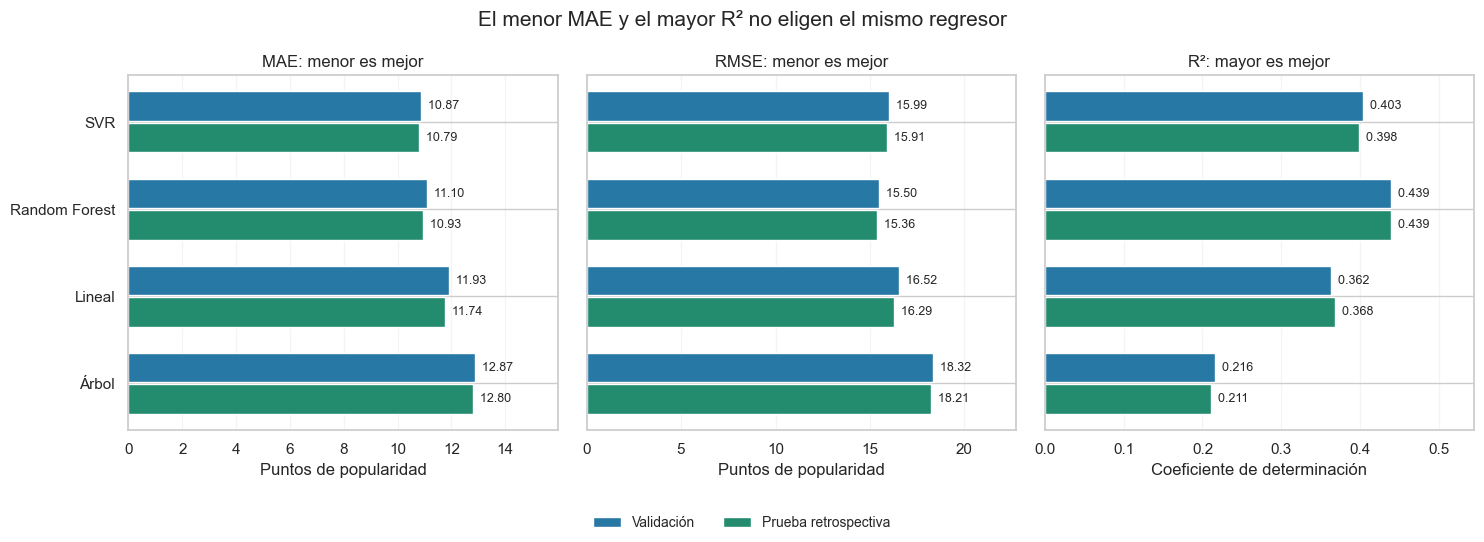

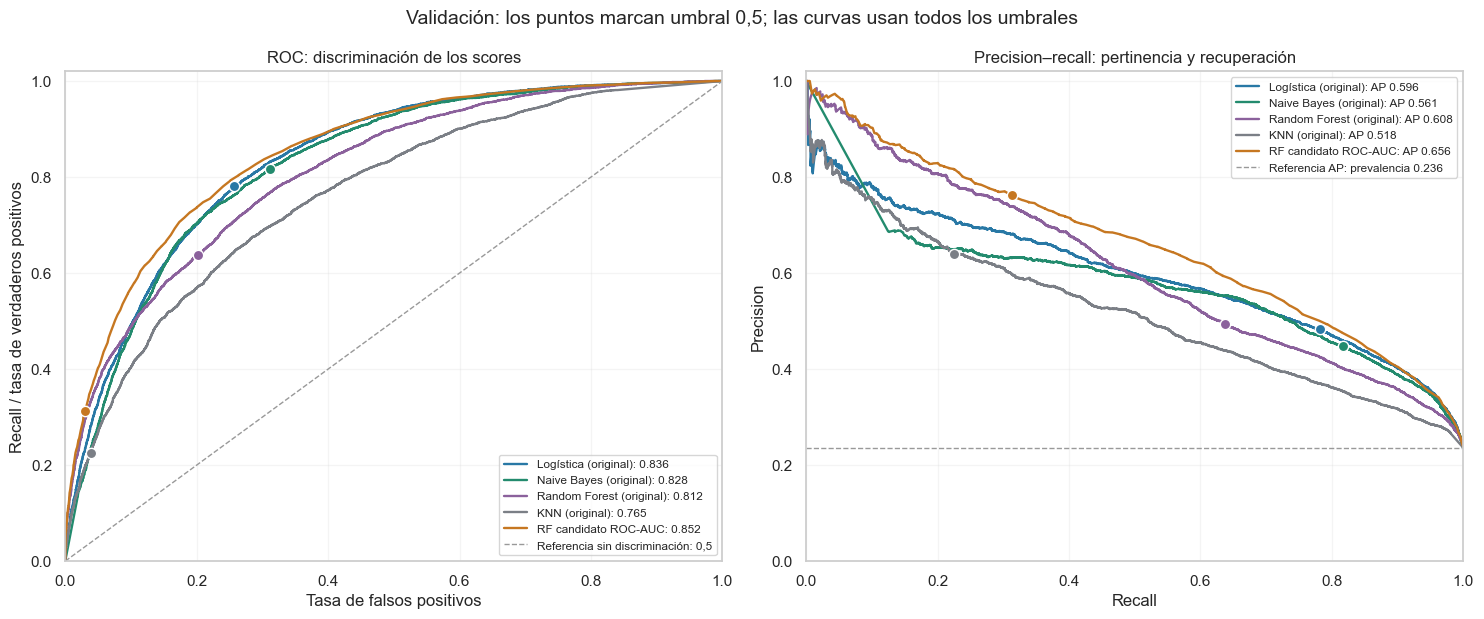

In [60]:
# [GRAFICOS REGRESION CLASIFICACION]
# Comparación visual de métricas
fig, rev_axes = plt.subplots(1, 3, figsize=(15, 5.4), sharey=True)
rev_y = np.arange(len(rev_reg_names))
for ax, metric, caption in zip(rev_axes, ["MAE", "RMSE", "R2"],
                               ["MAE: menor es mejor", "RMSE: menor es mejor", "R²: mayor es mejor"]):
    ax.barh(rev_y-.18, rev_reg_val.loc[rev_reg_names, metric], height=.34, color="#2878A5", label="Validación")
    ax.barh(rev_y+.18, rev_reg_test.loc[rev_reg_names, metric], height=.34, color="#238B6E", label="Prueba retrospectiva")
    for pos, name in enumerate(rev_reg_names):
        for offset, frame in [(-.18, rev_reg_val), (.18, rev_reg_test)]:
            value = float(frame.loc[name, metric])
            ax.text(value, pos+offset, f"  {value:.3f}" if metric == "R2" else f"  {value:.2f}", va="center", fontsize=9)
    ax.set_title(caption, fontsize=12)
    ax.set_xlabel("Puntos de popularidad" if metric != "R2" else "Coeficiente de determinación")
    ax.set_xlim(0, float(max(rev_reg_val[metric].max(), rev_reg_test[metric].max()))*1.24)
    ax.grid(axis="x", alpha=.2)
    ax.set_axisbelow(True)
rev_axes[0].set_yticks(rev_y, [rev_short[n] for n in rev_reg_names])
rev_axes[0].invert_yaxis()
fig.suptitle("El menor MAE y el mayor R² no eligen el mismo regresor", fontsize=15)
fig.legend(*rev_axes[0].get_legend_handles_labels(),loc="lower center",ncol=2,fontsize=10,frameon=False)
fig.tight_layout(rect=[0,.08,1,1])
rev_save(fig, "01_regresion_mae_rmse_r2.png")

fig, rev_axes = plt.subplots(1, 2, figsize=(15, 6.3))
rev_colors = ["#2878A5", "#238B6E", "#8B619C", "#7B7F86", "#C67721"]
for (name, score), color in zip(rev_val_scores.items(), rev_colors):
    short = "RF candidato ROC-AUC" if name == rev_auc_label else rev_short[name] + " (original)"
    metrics = rev_val_comparison.loc[name]
    fpr, tpr, _ = roc_curve(y_val_cls, score)
    precision, recall, _ = precision_recall_curve(y_val_cls, score)
    rev_axes[0].plot(fpr, tpr, color=color, lw=1.7, label=f"{short}: {metrics.ROC_AUC:.3f}")
    rev_axes[1].plot(recall, precision, color=color, lw=1.7, label=f"{short}: AP {metrics.AP:.3f}")
    tn, fp, fn, tp = confusion_matrix(y_val_cls, np.asarray(score)>=.5, labels=[0, 1]).ravel()
    rev_axes[0].scatter(fp/(fp+tn), tp/(tp+fn), color=color, marker="o", edgecolor="white", s=55, zorder=5)
    rev_axes[1].scatter(metrics.Recall, metrics.Precision, color=color, marker="o", edgecolor="white", s=55, zorder=5)
rev_prevalence = float(np.asarray(y_val_cls, dtype=int).mean())
rev_axes[0].plot([0, 1], [0, 1], ls="--", color="#999999", lw=1, label="Referencia sin discriminación: 0,5")
rev_axes[1].axhline(rev_prevalence, ls="--", color="#999999", lw=1, label=f"Referencia AP: prevalencia {rev_prevalence:.3f}")
rev_axes[0].set(title="ROC: discriminación de los scores", xlabel="Tasa de falsos positivos", ylabel="Recall / tasa de verdaderos positivos")
rev_axes[1].set(title="Precision–recall: pertinencia y recuperación", xlabel="Recall", ylabel="Precision")
for ax in rev_axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=.2)
    ax.legend(fontsize=8.5, loc="lower right" if ax is rev_axes[0] else "upper right")
fig.suptitle("Validación: los puntos marcan umbral 0,5; las curvas usan todos los umbrales", fontsize=14)
fig.tight_layout()
rev_save(fig, "03_clasificacion_roc_pr_validacion.png")

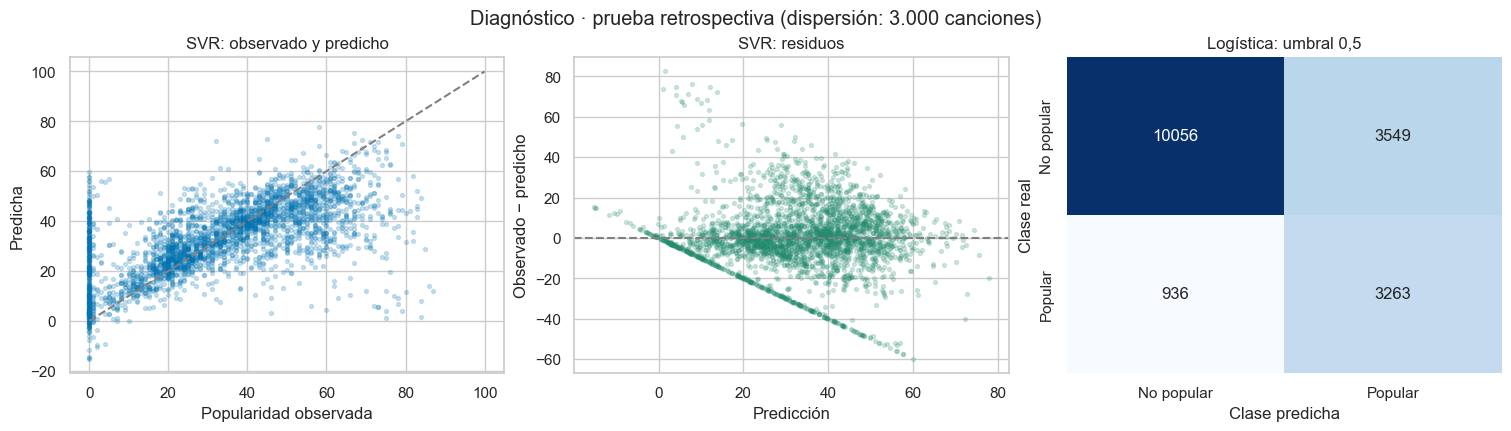

Residuos positivos: subestimación. La matriz muestra aciertos, falsas alarmas y omisiones.


In [61]:
# [GRAFICOS DIAGNOSTICO]
# Errores y decisiones de los modelos seleccionados
reg_observed = np.asarray(y_test_reg, dtype=float)
reg_predicted = reg_test_predictions[selected_reg_name]
reg_residuals = reg_observed - reg_predicted
plot_idx = np.random.default_rng(RANDOM_STATE).choice(len(reg_observed), 3000, replace=False)
matrix = confusion_matrix(y_test_cls, cls_test_predictions[selected_cls_name], labels=[0, 1])
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), layout='constrained')
axes[0].scatter(reg_observed[plot_idx], reg_predicted[plot_idx], s=8, alpha=.2)
axes[0].plot([0, 100], [0, 100], '--', color='grey')
axes[0].set(title='SVR: observado y predicho', xlabel='Popularidad observada', ylabel='Predicha')
axes[1].scatter(reg_predicted[plot_idx], reg_residuals[plot_idx], s=8, alpha=.2, color='#238B6E')
axes[1].axhline(0, color='grey', ls='--')
axes[1].set(title='SVR: residuos', xlabel='Predicción', ylabel='Observado − predicho')
sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[2],
            xticklabels=['No popular', 'Popular'], yticklabels=['No popular', 'Popular'])
axes[2].set(title='Logística: umbral 0,5', xlabel='Clase predicha', ylabel='Clase real')
fig.suptitle('Diagnóstico · prueba retrospectiva (dispersión: 3.000 canciones)')
rev_save(fig, 'diagnostico_supervisado.png')
print('Residuos positivos: subestimación. La matriz muestra aciertos, falsas alarmas y omisiones.')

### Resultados de segmentación

> [RESULTADOS] [CLUSTERING]

La búsqueda ampliada reemplaza las tablas antiguas repetidas. Los CSV conservan las 161
configuraciones y sus etiquetas. Se comparan silueta, cobertura y tamaños antes de interpretar grupos.
Una silueta alta sobre pocas canciones asignadas no basta para recomendar DBSCAN.

In [62]:
# [RESULTADOS CLUSTERING]
# Resumen de K-Means y DBSCAN
display(rc_km[['k', 'silhouette', 'davies_bouldin', 'calinski_harabasz',
               'min_cluster_pct_assigned', 'max_cluster_pct_assigned', 'eligible']].round(3))
display(rc_db.groupby(['representation', 'min_samples']).agg(
    configuraciones=('configuration', 'size'), elegibles=('eligible', 'sum'),
    grupos_min=('n_clusters', 'min'), grupos_max=('n_clusters', 'max'),
    ruido_min=('noise_pct', 'min'), ruido_max=('noise_pct', 'max')).round(2))

,k,silhouette,davies_bouldin,calinski_harabasz,min_cluster_pct_assigned,max_cluster_pct_assigned,eligible
0,2.0,0.228,1.738,1420.699,26.267,73.733,True
1,3.0,0.149,1.996,1146.556,21.350,43.133,True
2,4.0,0.152,1.796,1026.911,8.450,39.983,True
3,5.0,0.152,1.636,973.258,1.250,38.233,True
4,6.0,0.161,1.593,948.234,1.250,32.567,True
5,7.0,0.165,1.523,934.158,1.217,29.967,True
6,8.0,0.145,1.525,882.144,1.217,24.750,True
7,9.0,0.148,1.504,842.992,1.067,22.100,True
8,10.0,0.140,1.545,808.830,1.067,18.900,True
9,11.0,0.144,1.547,774.526,1.067,17.900,True


configuraciones  elegibles  grupos_min  \
representation min_samples                                           
Original10D    3.0                       15          0          10   
               5.0                       15          0           1   
               8.0                       15          0           0   
               11.0                      15          0           0   
               20.0                      15          0           0   
PCA7           3.0                       15          0           5   
               5.0                       15          0           2   
               8.0                       15          0           0   
               11.0                      15          0           0   
               20.0                      15          0           0   

                            grupos_max  ruido_min  ruido_max  
representation min_samples                                    
Original10D    3.0                 131       7.22      99.30  
               5.0                  35       5.50      99.92  
               8.0                  11       4.30     100.00  
               11.0                  7       3.73     100.00  
               20.0                  2       3.10     100.00  
PCA7           3.0                 147       3.17      98.72  
               5.0                  44       3.95      99.83  
               8.0                  15       4.33     100.00  
               11.0                 11       3.80     100.00  
               20.0                  4       3.00     100.00

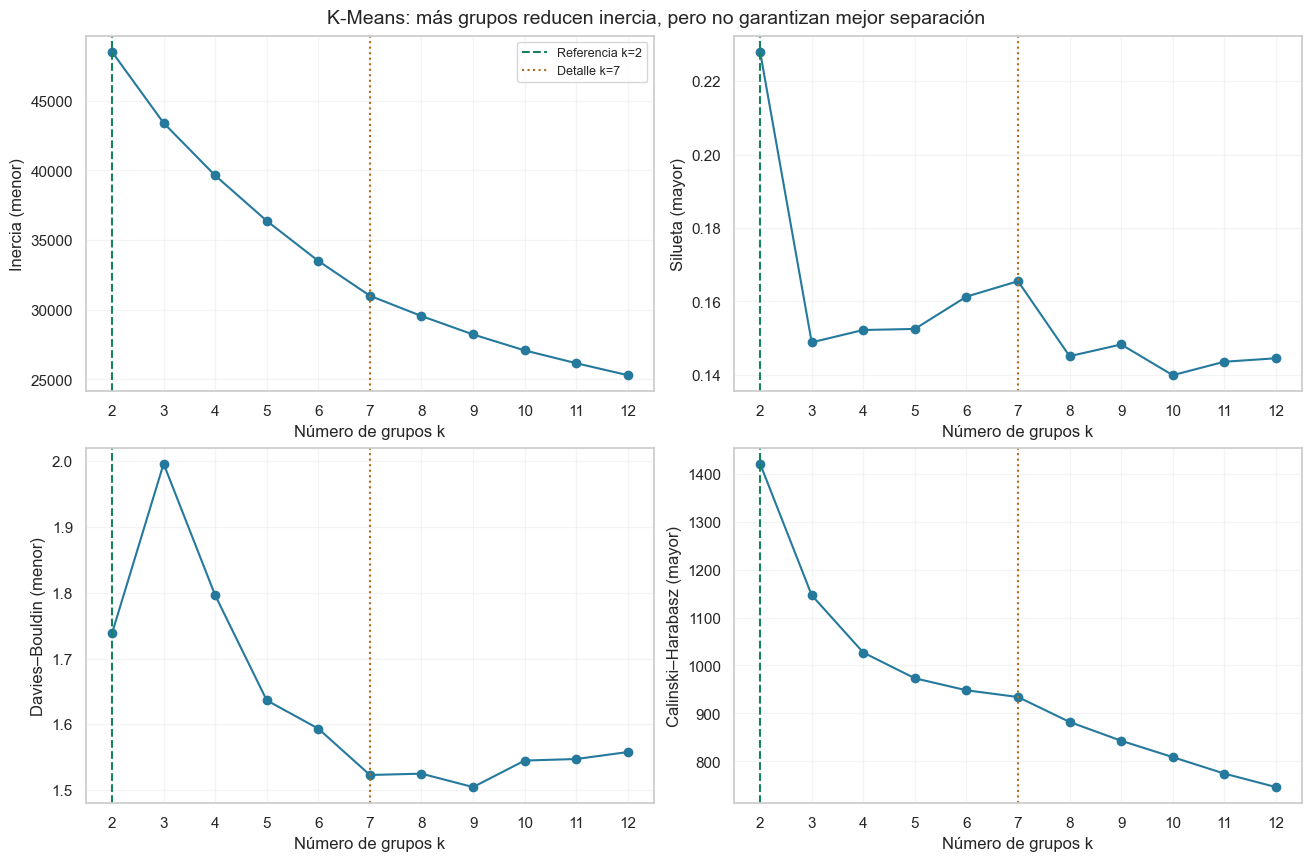

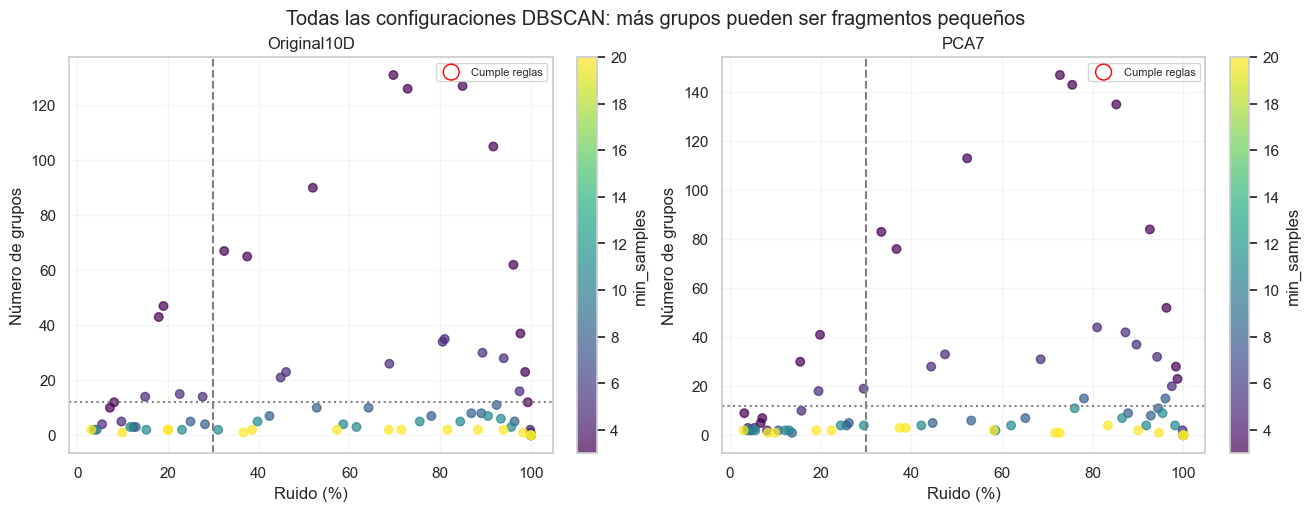

In [63]:
# [GRAFICOS CLUSTERING]
# Separación, número de grupos y ruido
# Mostrar todos los resultados; ninguna zona de mucho ruido desaparece del diagnóstico.
rc_fig,rc_ax=plt.subplots(2,2,figsize=(13,8.5),layout='constrained')
for a,col,label in zip(rc_ax.flat,['inertia','silhouette','davies_bouldin','calinski_harabasz'],
                       ['Inercia (menor)','Silueta (mayor)','Davies–Bouldin (menor)','Calinski–Harabasz (mayor)']):
    a.plot(rc_km.k,rc_km[col],'o-',color='#24799D')
    a.axvline(rc_overall.k,color='#16845B',ls='--',label=f'Referencia k={int(rc_overall.k)}')
    a.axvline(rc_detail.k,color='#B36B1D',ls=':',label=f'Detalle k={int(rc_detail.k)}')
    a.set(xlabel='Número de grupos k',ylabel=label,xticks=range(2,13));a.grid(alpha=.2)
rc_ax[0,0].legend(fontsize=9)
rc_fig.suptitle('K-Means: más grupos reducen inercia, pero no garantizan mejor separación',fontsize=14)
rc_fig.savefig(RC_DIR/'kmeans_search.png',dpi=150,bbox_inches='tight');plt.show();plt.close(rc_fig)

rc_fig,rc_ax=plt.subplots(1,2,figsize=(13,5),layout='constrained')
for a,rep in zip(rc_ax,rc_spaces):
    part=rc_db[rc_db.representation.eq(rep)]
    dots=a.scatter(part.noise_pct,part.n_clusters,c=part.min_samples,cmap='viridis',s=38,alpha=.7)
    eligible=part[part.eligible]
    a.scatter(eligible.noise_pct,eligible.n_clusters,s=130,facecolors='none',edgecolors='red',label='Cumple reglas')
    a.axvline(30,ls='--',color='grey');a.axhline(12,ls=':',color='grey')
    a.set(title=rep,xlabel='Ruido (%)',ylabel='Número de grupos');a.legend(fontsize=8);a.grid(alpha=.2)
    rc_fig.colorbar(dots,ax=a,label='min_samples')
rc_fig.suptitle('Todas las configuraciones DBSCAN: más grupos pueden ser fragmentos pequeños')
rc_fig.savefig(RC_DIR/'dbscan_noise_groups.png',dpi=150,bbox_inches='tight');plt.show();plt.close(rc_fig)

### Estabilidad y perfiles musicales

> [ANALISIS] [ESTABILIDAD] [PERFILES]

Se comparan cinco inicializaciones y cinco muestras del 80%. En K-Means, el ARI se calcula sobre las canciones omitidas frente a la partición completa. Escalado y PCA permanecen fijos: es sensibilidad interna, no validación externa. En DBSCAN se informa ruido, acuerdo sobre asignadas
y degeneración cuando solo queda un grupo común.

Los perfiles usan las diez variables, medianas e IQR. Los nombres son descripciones propuestas, no géneros oficiales. Las canciones de ejemplo son cercanas al centro, no necesariamente mejores.

In [64]:
# [CLUSTERING ESTABILIDAD RESULTADOS]
# Sensibilidad de la segmentación
# Comprobar si la alternativa multigrupo es sensible al inicio y a quitar canciones.
rc_stability=[]
with threadpool_limits(limits=2):
    for rc_id in rc_compare_ids:
        k=int(rc_km.set_index('configuration').loc[rc_id,'k'])
        baseline=rc_labels[rc_id]
        for seed in [7,19,42,73,101]:
            model=KMeans(n_clusters=k,n_init=20,random_state=seed,algorithm='lloyd').fit(cl_X)
            rc_stability.append(dict(configuration=rc_id,k=k,experiment='initialization',seed=seed,
                n_fit=6000,n_evaluated=6000,ARI=adjusted_rand_score(baseline,model.labels_),
                silhouette=rc_measure(model.labels_,'Original10D')['silhouette']))
        for seed in [107,119,142,173,201]:
            chosen=np.sort(np.random.default_rng(seed).choice(6000,4800,replace=False))
            omitted=np.setdiff1d(np.arange(6000),chosen)
            model=KMeans(n_clusters=k,n_init=20,random_state=42,algorithm='lloyd').fit(cl_X[chosen])
            predicted=model.predict(cl_X)
            rc_stability.append(dict(configuration=rc_id,k=k,experiment='subsample_80pct',seed=seed,
                n_fit=len(chosen),n_evaluated=len(omitted),ARI=adjusted_rand_score(baseline[omitted],predicted[omitted]),
                silhouette=rc_measure(predicted,'Original10D')['silhouette']))
rc_stability=pd.DataFrame(rc_stability)
rc_stability_summary=rc_stability.groupby(['configuration','k','experiment']).agg(
    ARI_min=('ARI','min'),ARI_mediana=('ARI','median'),ARI_max=('ARI','max'),
    silhouette_min=('silhouette','min'),silhouette_max=('silhouette','max')).reset_index()

# Un representante por espacio: operativo si existe, de lo contrario solo diagnóstico.
# En diagnóstico: primero 2–12 grupos, luego mayor cobertura y menor dominancia.
rc_db_reps=[]
for rep in rc_spaces:
    part=rc_db[rc_db.representation.eq(rep)]
    viable=part[part.eligible]
    if len(viable):
        picked=viable.sort_values(['silhouette','coverage'],ascending=False).iloc[0].copy()
        picked['role']='operativo según reglas exploratorias'
    else:
        candidates=part[part.n_clusters.between(2,12)]
        if candidates.empty: candidates=part
        picked=candidates.sort_values(['coverage','max_cluster_pct_assigned'],ascending=[False,True]).iloc[0].copy()
        picked['role']='diagnóstico; no recomendación operativa'
    rc_db_reps.append(picked)
rc_db_reps=pd.DataFrame(rc_db_reps)
rc_db_sensitivity=[]
with threadpool_limits(limits=2):
    for row in rc_db_reps.itertuples():
        matrix=rc_spaces[row.representation];baseline=rc_labels[row.configuration]
        for factor in [.95,1.,1.05]:
            y=DBSCAN(eps=row.eps*factor,min_samples=int(row.min_samples),algorithm='ball_tree',n_jobs=2).fit_predict(matrix)
            shared=(baseline>=0)&(y>=0)
            ng0=len(np.unique(baseline[shared]));ng1=len(np.unique(y[shared]))
            rc_db_sensitivity.append(dict(configuration=row.configuration,representation=row.representation,
                experiment='eps_sensitivity',factor=factor,seed=42,
                ARI_all_including_noise=adjusted_rand_score(baseline,y),
                ARI_shared_assigned=adjusted_rand_score(baseline[shared],y[shared]) if shared.sum()>1 else np.nan,
                shared_assigned=int(shared.sum()),shared_groups_baseline=ng0,shared_groups_new=ng1,
                degenerate_shared=bool(ng0<2 or ng1<2),
                coverage_jaccard=np.sum((y>=0)&(baseline>=0))/max(1,np.sum((y>=0)|(baseline>=0))),
                n_evaluated=6000,**rc_measure(y,row.representation)))
        for seed in [107,119,142,173,201]:
            chosen=np.sort(np.random.default_rng(seed).choice(6000,4800,replace=False))
            y=DBSCAN(eps=row.eps,min_samples=int(row.min_samples),algorithm='ball_tree',n_jobs=2).fit_predict(matrix[chosen])
            base=baseline[chosen];shared=(base>=0)&(y>=0)
            ng0=len(np.unique(base[shared]));ng1=len(np.unique(y[shared]));deg=(ng0<2 or ng1<2)
            rc_db_sensitivity.append(dict(configuration=row.configuration,representation=row.representation,
                experiment='subsample_80pct',factor=1.,seed=seed,n_evaluated=len(chosen),
                n_clusters=len(np.unique(y[y>=0])),coverage=float(np.mean(y>=0)),noise_pct=float(100*np.mean(y<0)),
                ARI_all_including_noise=adjusted_rand_score(base,y),
                ARI_shared_assigned=adjusted_rand_score(base[shared],y[shared]) if shared.sum()>1 else np.nan,
                shared_assigned=int(shared.sum()),shared_groups_baseline=ng0,shared_groups_new=ng1,degenerate_shared=deg,
                coverage_jaccard=np.sum(shared)/max(1,np.sum((base>=0)|(y>=0)))))
rc_db_sensitivity=pd.DataFrame(rc_db_sensitivity)
display(rc_stability_summary[['k', 'experiment', 'ARI_min', 'ARI_mediana', 'ARI_max']].round(3))
display(rc_db_reps[['representation', 'eps', 'min_samples', 'n_clusters',
                    'noise_pct', 'max_cluster_pct_assigned', 'eligible']].round(3))
display(rc_db_sensitivity.groupby(['representation', 'experiment']).agg(
    ruido_min=('noise_pct', 'min'), ruido_max=('noise_pct', 'max'),
    ARI_compartidas_min=('ARI_shared_assigned', 'min'),
    comparaciones_degeneradas=('degenerate_shared', 'sum')).round(3))

,k,experiment,ARI_min,ARI_mediana,ARI_max
0,2,initialization,0.996,1.000,1.000
1,2,subsample_80pct,0.993,0.997,1.000
2,7,initialization,0.997,0.998,1.000
3,7,subsample_80pct,0.973,0.983,0.992


,representation,eps,min_samples,n_clusters,noise_pct,max_cluster_pct_assigned,eligible
85,Original10D,2.158,20.0,2,3.1,99.432,False
160,PCA7,1.840,20.0,2,3.0,99.433,False


ruido_min  ruido_max  ARI_compartidas_min  \
representation experiment                                                   
Original10D    eps_sensitivity      2.433      3.967                  1.0   
               subsample_80pct      3.542      4.188                  1.0   
PCA7           eps_sensitivity      2.500      3.850                  1.0   
               subsample_80pct      3.521      4.229                  1.0   

                                comparaciones_degeneradas  
representation experiment                                  
Original10D    eps_sensitivity                          0  
               subsample_80pct                          3  
PCA7           eps_sensitivity                          0  
               subsample_80pct                          3

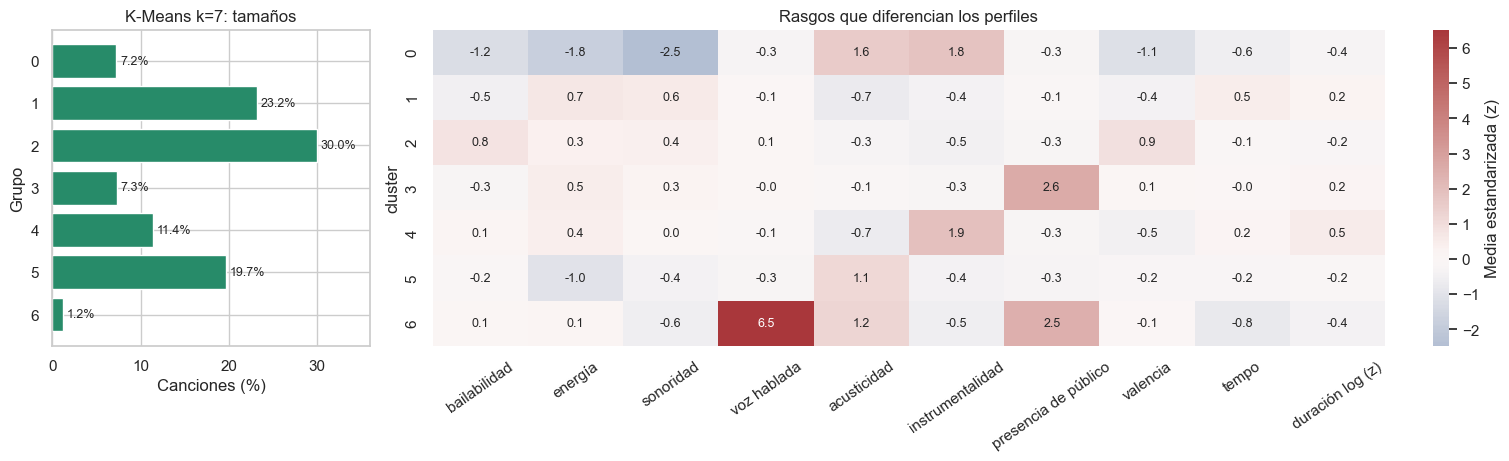

,cluster,songs,pct,profile,proposed_use
2,0,435,7.25,"sonoridad menor, energía menor, instrumentalid...",Explorar instrumentales acústicos de baja ener...
3,1,1389,23.15,"acusticidad menor, energía mayor, sonoridad mayor","Explorar selección de alta energía, no implica..."
4,2,1798,29.97,"valencia mayor, bailabilidad mayor, instrument...",Explorar selección para actividad y baile.
5,3,441,7.35,"presencia de público mayor, energía mayor, ins...",Revisar posibles actuaciones en vivo: liveness...
6,4,685,11.42,"instrumentalidad mayor, acusticidad menor, dur...",Explorar instrumentales de mayor energía y dur...
7,5,1179,19.65,"acusticidad mayor, energía menor, instrumental...",Explorar un bloque acústico de menor energía.
8,6,73,1.22,"voz hablada mayor, presencia de público mayor,...",Revisión de voz hablada o material mixto; conf...


,cluster,track_name,artists
6,0,Veloma,Fabrizio Paterlini
9,1,Do Or Die,Thirty Seconds To Mars
12,2,See The Light,Stephen Sanchez
15,3,Fogueira - Jorge & Mateus Elétrico,Jorge & Mateus
18,4,Born in Winter,Gojira
21,5,Rockland,Gracie Abrams
24,6,Fox Paws,Chad Daniels


In [65]:
# [CLUSTERING PERFILES GRAFICOS]
# Perfiles, tamaños y canciones representativas
# Perfiles musicales en unidades reconocibles, no solamente energía/instrumentalidad.
rc_original=cl_sample[['danceability','energy','loudness','speechiness','acousticness',
                     'instrumentalness','liveness','valence','tempo']].apply(pd.to_numeric,errors='coerce').copy()
rc_original.loc[rc_original.tempo.le(0),'tempo']=np.nan
rc_original['duration_min']=pd.to_numeric(cl_sample.duration_ms,errors='coerce')/60000
rc_display_names={'danceability':'bailabilidad','energy':'energía','loudness':'sonoridad',
    'speechiness':'voz hablada','acousticness':'acusticidad','instrumentalness':'instrumentalidad',
    'liveness':'presencia de público','valence':'valencia','tempo':'tempo','log_duration':'duración log',
    'duration_min':'duración (min)'}
rc_profile_rows=[];rc_group_rows=[];rc_example_rows=[]
rc_z=pd.DataFrame(cl_X,columns=cl_feature_names)
for rc_id in rc_compare_ids:
    labels=rc_labels[rc_id]
    centroids=rc_models[rc_id].cluster_centers_
    for group in sorted(np.unique(labels)):
        mask=labels==group;z=rc_z.loc[mask].mean()
        top=z.abs().nlargest(3).index
        description=', '.join(f'{rc_display_names[f]} {"mayor" if z[f]>0 else "menor"}' for f in top)
        med=rc_original.loc[mask].median()
        if med.speechiness>.4: use='Revisión de voz hablada o material mixto; confirmar con escucha.'
        elif med.instrumentalness>.5 and med.energy<.5: use='Explorar instrumentales acústicos de baja energía; confirmar voz y contexto con escucha.'
        elif med.instrumentalness>.5: use='Explorar instrumentales de mayor energía y duración; confirmar el perfil con escucha.'
        elif med.liveness>.35: use='Revisar posibles actuaciones en vivo: liveness es un indicador, no prueba de una grabación en directo.'
        elif med.acousticness>.5 and med.energy<.5: use='Explorar un bloque acústico de menor energía.'
        elif med.energy>.7 and med.danceability>.6: use='Explorar selección para actividad y baile.'
        elif med.energy>.7: use='Explorar selección de alta energía, no implica un género concreto.'
        else: use='Organizar una sesión de escucha según el perfil medido.'
        rc_group_rows.append(dict(configuration=rc_id,cluster=int(group),songs=int(mask.sum()),
            pct=100*mask.mean(),profile=description,proposed_use=use,
            **{f'median_{f}':float(med[f]) for f in rc_original}))
        for feature in rc_original:
            vals=rc_original.loc[mask,feature]
            zkey='log_duration' if feature=='duration_min' else feature
            rc_profile_rows.append(dict(configuration=rc_id,cluster=int(group),feature=feature,
                n_observed=int(vals.notna().sum()),median=float(vals.median()),q25=float(vals.quantile(.25)),
                q75=float(vals.quantile(.75)),mean_z=float(z[zkey])))
        distances=np.linalg.norm(cl_X[mask]-centroids[int(group)],axis=1)
        nearest=np.where(mask)[0][np.argsort(distances,kind='stable')[:3]]
        for rank,idx in enumerate(nearest,1):
            rc_example_rows.append(dict(configuration=rc_id,cluster=int(group),rank=rank,
                track_id=cl_sample.iloc[idx].track_id,track_name=cl_sample.iloc[idx].track_name,
                artists=cl_sample.iloc[idx].artists,distance_to_centroid=float(np.linalg.norm(cl_X[idx]-centroids[int(group)]))))
rc_profiles=pd.DataFrame(rc_profile_rows);rc_groups=pd.DataFrame(rc_group_rows);rc_examples=pd.DataFrame(rc_example_rows)
rc_sizes=[]
for row in rc_db_reps.itertuples():
    lab=rc_labels[row.configuration]
    for group,count in pd.Series(lab).value_counts().sort_index().items():
        rc_sizes.append(dict(configuration=row.configuration,representation=row.representation,cluster=int(group),
            songs=int(count),pct_total=100*count/len(lab),
            pct_assigned=100*count/max(1,np.sum(lab>=0)) if group>=0 else np.nan))
for rc_id in [rc_detail.configuration]:
    rows=rc_groups[rc_groups.configuration.eq(rc_id)]
    k=len(rows)
    means=rc_profiles[rc_profiles.configuration.eq(rc_id)].pivot(index='cluster',columns='feature',values='mean_z')
    means=means.reindex(columns=rc_original.columns)
    means.columns=['duración log (z)' if c=='duration_min' else rc_display_names[c] for c in means.columns]
    rc_fig,rc_ax=plt.subplots(1,2,figsize=(15,max(4.5,k*.42)),gridspec_kw={'width_ratios':[1,3]},layout='constrained')
    rc_ax[0].barh(rows.cluster.astype(str),rows.pct,color='#278B69')
    rc_ax[0].invert_yaxis()  # El grupo 0 queda arriba, igual que en el mapa de perfiles.
    rc_ax[0].set(xlabel='Canciones (%)',ylabel='Grupo',title=f'K-Means k={k}: tamaños')
    for y,pct in zip(rows.cluster.astype(str),rows.pct): rc_ax[0].text(pct+.4,y,f'{pct:.1f}%',va='center',fontsize=9)
    rc_ax[0].set_xlim(0,rows.pct.max()*1.2)
    sns.heatmap(means,annot=True,fmt='.1f',center=0,cmap='vlag',ax=rc_ax[1],cbar_kws={'label':'Media estandarizada (z)'},annot_kws={'fontsize':9})
    rc_ax[1].set(title='Rasgos que diferencian los perfiles',xlabel='');rc_ax[1].tick_params(axis='x',rotation=35)
    rc_fig.savefig(RC_DIR/f'profiles_k{k}.png',dpi=150,bbox_inches='tight');plt.show();plt.close(rc_fig)
    display(rows[['cluster','songs','pct','profile','proposed_use']].round(2))
    display(rc_examples[rc_examples.configuration.eq(rc_id) & rc_examples['rank'].eq(1)][['cluster','track_name','artists']])

rc_transition = pd.crosstab(rc_labels['Original10D_KMeans_k2'], rc_labels[rc_detail.configuration],
                            rownames=['grupo_k2'], colnames=[f'grupo_k{int(rc_detail.k)}'])

In [66]:
# [CLUSTERING ANALISIS]
# Lectura final de los experimentos de agrupación
# Conclusiones calculadas: la ampliación no reemplaza silenciosamente la entrega anterior.
rc_detail_stab=rc_stability_summary[(rc_stability_summary.configuration.eq(rc_detail.configuration)) & rc_stability_summary.experiment.eq('subsample_80pct')].iloc[0]
rc_original_db=rc_db[rc_db.representation.eq('Original10D')]
rc_small=rc_original_db[rc_original_db.min_samples.le(5)&rc_original_db.eps.lt(1.)]
rc_compact_counts=rc_db.groupby('representation').eligible.sum().to_dict()
rc_findings={
    'configurations_total':len(rc_search),'dbscan_configurations':len(rc_db),'kmeans_configurations':len(rc_km),
    'kmeans_global_reference':rc_overall.to_dict(), 'kmeans_editorial_detail':rc_detail.to_dict(),
    'detail_resampling_stability':rc_detail_stab.to_dict(),
    'dbscan_eligible_per_representation':{k:int(v) for k,v in rc_compact_counts.items()},
    'small_eps_min_samples_original':{'configurations':len(rc_small),'clusters_min':int(rc_small.n_clusters.min()),
        'clusters_max':int(rc_small.n_clusters.max()),'noise_min_pct':float(rc_small.noise_pct.min()),
        'noise_max_pct':float(rc_small.noise_pct.max())},
    'elapsed_seconds':perf_counter()-rc_started,
    'interpretation':'Keep global geometric reference; offer the multigroup candidate only as an exploratory editorial granularity. Utility and fresh-sample validation pending.',
}
def rc_json_safe(value):
    if isinstance(value,dict): return {k:rc_json_safe(v) for k,v in value.items()}
    if isinstance(value,(list,tuple)): return [rc_json_safe(v) for v in value]
    if isinstance(value,(float,np.floating)) and not np.isfinite(value): return None
    if isinstance(value,np.generic): return value.item()
    return value
rc_findings=rc_json_safe(rc_findings)
(RC_DIR/'summary.json').write_text(json.dumps(rc_findings,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')

assert len(rc_search) == 161 and len(rc_db) == 150 and len(rc_km) == 11
assert rc_transition.to_numpy().sum() == 6000
display(Markdown(
    f"**K-Means:** k={int(rc_overall.k)} conserva la mayor silueta ({rc_overall.silhouette:.3f}), "
    f"k={int(rc_detail.k)} ofrece detalle ({rc_detail.silhouette:.3f}), con ARI mediano "
    f"{rc_detail_stab.ARI_mediana:.3f} en el remuestreo. "
    f"**DBSCAN:** {sum(rc_compact_counts.values())}/{len(rc_db)} configuraciones elegibles. "
    f"En 10D, eps<1 y min_samples≤5 producen {int(rc_small.n_clusters.min())}–"
    f"{int(rc_small.n_clusters.max())} grupos y {rc_small.noise_pct.min():.1f}–{rc_small.noise_pct.max():.1f}% de ruido."
))

**K-Means:** k=2 conserva la mayor silueta (0.228), k=7 ofrece detalle (0.165), con ARI mediano 0.983 en el remuestreo. **DBSCAN:** 0/150 configuraciones elegibles. En 10D, eps<1 y min_samples≤5 producen 1–131 grupos y 46.0–99.9% de ruido.

### Comparación de representaciones

> [PCA] [PARAMETROS]

Se reutilizan las **6.000 canciones**, diez atributos estandarizados y la misma base de **2.000** para métricas. Comparamos Original10D, PCA2, PCA3, PCA90, PCA95 y PCA10 de control.
PD: PCA no se blanquea ni se reescala

- **K-Means:** k=2…8, 20 inicios, semilla 42. **DBSCAN:** min_samples=11/20 y eps según cuantiles 20/40/60/75/90% de distancias al vecino. Son **102 configuraciones**, la búsqueda ampliada de DBSCAN se presenta en el bloque de segmentación.
- Dentro de cada representación: 2–12 grupos, cobertura ≥70%, mínimo ≥1% y máximo ≤90% entre canciones asignadas, después, mayor silueta de ajuste. Las soluciones que incumplen se muestran como diagnóstico.
- Entre representaciones: silueta recalculada en las diez variables, cobertura y ARI. DBSCAN excluye ruido de las métricas geométricas, se informa la base efectiva. El eps de una receta se recalcula en cada espacio.


In [67]:
# [PCA ENTRENAMIENTO]
# Seis representaciones y búsqueda comparable
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score, pairwise_distances)
from threadpoolctl import threadpool_limits
from time import perf_counter

PCA_OUTPUT_DIR = ROOT_OUTPUT / "pca"
PCA_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
pc_X, pc_base = np.asarray(cl_X, dtype=np.float64), np.asarray(cl_metric_indices, dtype=int)
assert pc_X.shape == (6000, 10) and len(pc_base) == len(np.unique(pc_base)) == 2000
assert np.isfinite(pc_X).all() and cl_sample.track_id.is_unique
pc_pca = PCA(n_components=10, svd_solver="full", whiten=False)
with threadpool_limits(limits=2):
    pc_scores = pc_pca.fit_transform(pc_X)
pc_cumulative = np.cumsum(pc_pca.explained_variance_ratio_)
pc_d90, pc_d95 = [int(np.searchsorted(pc_cumulative, q) + 1) for q in [.90, .95]]
pc_spaces = {"Original10D": pc_X, "PCA2": pc_scores[:, :2], "PCA3": pc_scores[:, :3],
             "PCA90": pc_scores[:, :pc_d90], "PCA95": pc_scores[:, :pc_d95], "PCA10_control": pc_scores}
pc_variance = pd.DataFrame({"component": np.arange(1, 11),
    "explained_variance_ratio": pc_pca.explained_variance_ratio_, "cumulative_variance_ratio": pc_cumulative})



def pc_measure(space, labels):
    assigned = labels >= 0
    counts = pd.Series(labels[assigned]).value_counts()
    subset = pc_base[assigned[pc_base]]
    record = {"n_clusters": len(counts), "coverage": float(assigned.mean()),
        "noise_pct": float(100 * (~assigned).mean()), "n_metric": len(subset),
        "n_clusters_metric": len(np.unique(labels[subset])),
        "min_cluster_pct_assigned": float(100 * counts.min() / assigned.sum()) if len(counts) else 0.,
        "max_cluster_pct_assigned": float(100 * counts.max() / assigned.sum()) if len(counts) else 0.}
    for name, matrix in [("fit", space), ("original", pc_X)]:
        record.update({f"silhouette_{name}": np.nan, f"db_{name}": np.nan, f"ch_{name}": np.nan})
        if 1 < record["n_clusters_metric"] < len(subset):
            values, groups = matrix[subset], labels[subset]
            record.update({f"silhouette_{name}": float(silhouette_score(values, groups)),
                f"db_{name}": float(davies_bouldin_score(values, groups)),
                f"ch_{name}": float(calinski_harabasz_score(values, groups))})
    return record

def pc_rank(frame):
    return frame.sort_values(["silhouette_fit", "coverage", "fit_seconds"],
                            ascending=[False, False, True], na_position="last")

pc_records, pc_labels = [], {}
with threadpool_limits(limits=2):
    for pc_rep, pc_space in pc_spaces.items():
        pc_dims = pc_space.shape[1]
        pc_retained = 1. if pc_rep == "Original10D" else float(pc_cumulative[pc_dims - 1])
        pc_jobs = [(f"KMeans_k{k}", "K-Means", k, np.nan, np.nan, np.nan,
                    KMeans(n_clusters=k, n_init=20, max_iter=300, random_state=RANDOM_STATE,
                           init="k-means++", algorithm="lloyd")) for k in range(2, 9)]
        for pc_m in [11, 20]:
            pc_dist = NearestNeighbors(n_neighbors=pc_m, n_jobs=2).fit(pc_space).kneighbors(pc_space)[0][:, -1]
            for pc_q in [.20, .40, .60, .75, .90]:
                pc_eps = max(float(np.quantile(pc_dist, pc_q)), np.finfo(float).eps)
                pc_jobs.append((f"DBSCAN_m{pc_m}_q{int(pc_q * 100)}", "DBSCAN", np.nan, pc_eps, pc_q,
                    pc_m, DBSCAN(eps=pc_eps, min_samples=pc_m, metric="euclidean", algorithm="ball_tree", n_jobs=2)))
        for pc_cfg, pc_algo, pc_k, pc_eps, pc_q, pc_m, pc_model in pc_jobs:
            pc_start = perf_counter()
            pc_label = pc_model.fit_predict(pc_space)
            pc_seconds = perf_counter() - pc_start
            pc_labels[(pc_rep, pc_cfg)] = pc_label
            pc_records.append({"representation": pc_rep, "dimensions": pc_dims,
                "retained_variance": pc_retained, "configuration": pc_cfg, "algorithm": pc_algo,
                "k": pc_k, "eps": pc_eps, "eps_quantile": pc_q, "min_samples": pc_m,
                "fit_seconds": pc_seconds, "inertia": getattr(pc_model, "inertia_", np.nan),
                **pc_measure(pc_space, pc_label)})
pc_results = pd.DataFrame(pc_records)
pc_results["eligible"] = (pc_results.n_clusters.between(2, 12) & pc_results.coverage.ge(.70)
    & pc_results.min_cluster_pct_assigned.ge(1.) & pc_results.max_cluster_pct_assigned.le(90.)
    & pc_results.silhouette_fit.notna())
assert len(pc_results) == 102
pc_representatives = []
for (pc_rep, pc_algo), pc_part in pc_results.groupby(["representation", "algorithm"], sort=False):
    pc_pool = pc_part.loc[pc_part.eligible]
    pc_status = "Elegible" if len(pc_pool) else "Solo diagnóstico, incumple reglas"
    if pc_pool.empty:
        pc_pool = pc_part.loc[pc_part.n_clusters.between(2, 12) & pc_part.coverage.ge(.30)]
    if pc_pool.empty:
        pc_pool = pc_part.sort_values("coverage", ascending=False).head(1)
    pc_row = pc_rank(pc_pool).iloc[0].copy()
    pc_row["interpretation_status"], pc_row["eligible_configurations"] = pc_status, int(pc_part.eligible.sum())
    pc_representatives.append(pc_row)
pc_representatives = pd.DataFrame(pc_representatives).reset_index(drop=True)
pc_fixed = pc_results.loc[pc_results.configuration.isin(["KMeans_k2", "DBSCAN_m20_q90"])].copy()


,representation,algorithm,dimensions,retained_variance,configuration,silhouette_fit,silhouette_original,noise_pct,n_metric,eligible,eligible_configurations
0,Original10D,K-Means,10,1.0000,KMeans_k2,0.2280,0.2280,0.0000,2000,True,7
1,Original10D,DBSCAN,10,1.0000,DBSCAN_m20_q90,0.5561,0.5561,3.1000,1930,False,0
2,PCA2,K-Means,2,0.4417,KMeans_k2,0.4306,0.2271,0.0000,2000,True,7
3,PCA2,DBSCAN,2,0.4417,DBSCAN_m20_q90,0.5235,0.3435,6.4167,1881,False,0
4,PCA3,K-Means,3,0.5704,KMeans_k2,0.3604,0.2276,0.0000,2000,True,7
5,PCA3,DBSCAN,3,0.5704,DBSCAN_m20_q75,0.4739,0.3264,13.8500,1744,False,0
6,PCA90,K-Means,7,0.9095,KMeans_k2,0.2456,0.2274,0.0000,2000,True,7
7,PCA90,DBSCAN,7,0.9095,DBSCAN_m11_q75,0.6111,0.5902,12.2000,1734,False,0
8,PCA95,K-Means,8,0.9535,KMeans_k2,0.2343,0.2281,0.0000,2000,True,7
9,PCA95,DBSCAN,8,0.9535,DBSCAN_m11_q90,0.5694,0.5600,3.8333,1905,False,0


,representation,algorithm,ari_all_6000_noise_as_label,ari_common_assigned,n_common_assigned,common_ari_degenerate,aligned_changed_pct,assignment_status_changed_pct
12,Original10D,K-Means,1.0000,1.0000,6000,False,0.0000,0.0000
13,Original10D,DBSCAN,1.0000,1.0000,5814,False,NaN,0.0000
14,PCA2,K-Means,0.9397,0.9397,6000,False,1.4500,0.0000
15,PCA2,DBSCAN,0.2131,-0.0071,5515,False,NaN,6.6500
16,PCA3,K-Means,0.9459,0.9459,6000,False,1.3000,0.0000
17,PCA3,DBSCAN,0.5971,1.0000,5661,True,NaN,3.5833
18,PCA90,K-Means,0.9909,0.9909,6000,False,0.2167,0.0000
19,PCA90,DBSCAN,0.8879,1.0000,5792,False,NaN,0.8333
20,PCA95,K-Means,0.9902,0.9902,6000,False,0.2333,0.0000
21,PCA95,DBSCAN,0.9257,1.0000,5803,False,NaN,0.5833


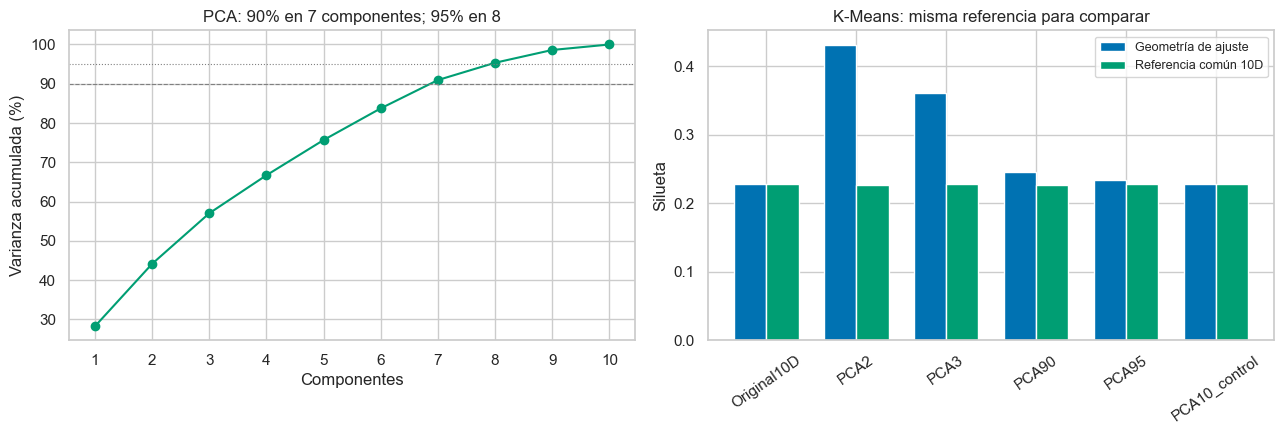

PCA10 conserva distancias y reconstrucción: errores máximos 2.84e-13 y 1.70e-14.


In [68]:
# [PCA RESULTADOS]
# Métricas, concordancia, control 10D y gráfico común
pc_agreements = []
pc_assignments = cl_sample[["track_id"]].copy()
for pc_type, pc_frame in [("representative", pc_representatives), ("fixed", pc_fixed)]:
    for _, pc_row in pc_frame.iterrows():
        pc_rep, pc_algo = pc_row.representation, pc_row.algorithm
        pc_original_row = pc_frame.loc[pc_frame.representation.eq("Original10D") & pc_frame.algorithm.eq(pc_algo)].iloc[0]
        pc_ref = pc_labels[("Original10D", pc_original_row.configuration)]
        pc_lab = pc_labels[(pc_rep, pc_row.configuration)]
        pc_common = (pc_ref >= 0) & (pc_lab >= 0)
        pc_n0, pc_n1 = len(np.unique(pc_ref[pc_common])), len(np.unique(pc_lab[pc_common]))
        pc_changed = np.nan
        if pc_algo == "K-Means" and len(np.unique(pc_ref)) == len(np.unique(pc_lab)):
            pc_ref_ids, pc_new_ids = np.unique(pc_ref), np.unique(pc_lab)
            pc_cross = np.array([[np.sum((pc_ref == a) & (pc_lab == b)) for b in pc_new_ids] for a in pc_ref_ids])
            pc_i, pc_j = linear_sum_assignment(-pc_cross)
            pc_map = dict(zip(pc_new_ids[pc_j], pc_ref_ids[pc_i]))
            pc_changed = float(100 * np.mean(np.array([pc_map[x] for x in pc_lab]) != pc_ref))
        pc_agreements.append({"comparison_type": pc_type, "representation": pc_rep, "algorithm": pc_algo,
            "configuration": pc_row.configuration, "original_configuration": pc_original_row.configuration,
            "ari_all_6000_noise_as_label": float(adjusted_rand_score(pc_ref, pc_lab)),
            "n_common_assigned": int(pc_common.sum()), "n_clusters_original_common": pc_n0,
            "n_clusters_new_common": pc_n1, "common_ari_degenerate": bool(min(pc_n0, pc_n1) < 2),
            "ari_common_assigned": float(adjusted_rand_score(pc_ref[pc_common], pc_lab[pc_common])) if pc_common.sum() > 1 else np.nan,
            "aligned_changed_pct": pc_changed,
            "assignment_status_changed_pct": float(100 * np.mean((pc_ref >= 0) != (pc_lab >= 0)))})
        pc_assignments[f"{pc_type}__{pc_rep}__{pc_algo}"] = pc_lab
pc_agreements = pd.DataFrame(pc_agreements)
with threadpool_limits(limits=2):
    pc_distance_squared_error = float(np.max(np.abs(pairwise_distances(pc_X[pc_base]) ** 2
                                                   - pairwise_distances(pc_scores[pc_base]) ** 2)))
pc_reconstruction_error = float(np.max(np.abs(pc_pca.inverse_transform(pc_scores) - pc_X)))
pc_control = pc_agreements.query("representation == 'PCA10_control' and comparison_type == 'fixed'")
assert pc_distance_squared_error < 1e-9 and pc_reconstruction_error < 1e-10
assert pc_control.ari_all_6000_noise_as_label.eq(1.).all()
pc_verification = {"configurations": len(pc_results), "representatives": len(pc_representatives),
    "same_6000_track_ids_and_order": True, "same_2000_metric_base": True,
    "pca10_max_squared_distance_error": pc_distance_squared_error,
    "pca10_max_reconstruction_error": pc_reconstruction_error,
    "pca10_partition_ari": pc_control[["algorithm", "ari_all_6000_noise_as_label"]].to_dict(orient="records")}
pc_summary = {"dimensions_90pct": pc_d90, "dimensions_95pct": pc_d95,
    "variance_2": float(pc_cumulative[1]), "variance_3": float(pc_cumulative[2]),
    "variance_90": float(pc_cumulative[pc_d90 - 1]), "variance_95": float(pc_cumulative[pc_d95 - 1]),
    "protocol": {"n_songs": len(pc_X), "n_metric_base": len(pc_base), "random_state": RANDOM_STATE,
        "pca_solver": "full", "whiten": False, "rescale_components": False,
        "k": list(range(2, 9)), "min_samples": [11, 20], "eps_quantiles": [.20, .40, .60, .75, .90]},
    "verification": pc_verification}
(PCA_OUTPUT_DIR / "summary.json").write_text(json.dumps(pc_summary, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
pc_cols = ["representation", "algorithm", "dimensions", "retained_variance", "configuration",
    "silhouette_fit", "silhouette_original", "noise_pct", "n_metric", "eligible", "eligible_configurations"]
display(pc_representatives[pc_cols].round(4))
display(pc_agreements.query("comparison_type == 'fixed'")[["representation", "algorithm",
    "ari_all_6000_noise_as_label", "ari_common_assigned", "n_common_assigned",
    "common_ari_degenerate", "aligned_changed_pct", "assignment_status_changed_pct"]].round(4))
pc_km = pc_representatives.query("algorithm == 'K-Means'").set_index("representation").loc[list(pc_spaces)]
pc_fig, pc_ax = plt.subplots(1, 2, figsize=(13, 4.5))
pc_ax[0].plot(np.arange(1, 11), 100 * pc_cumulative, marker="o", color="#009E73")
pc_ax[0].axhline(90, color="gray", ls="--", lw=.8)
pc_ax[0].axhline(95, color="gray", ls=":", lw=.8)
pc_ax[0].set(xlabel="Componentes", ylabel="Varianza acumulada (%)", xticks=np.arange(1, 11),
             title=f"PCA: 90% en {pc_d90} componentes; 95% en {pc_d95}")
pc_x = np.arange(len(pc_km))
pc_ax[1].bar(pc_x - .18, pc_km.silhouette_fit, width=.36, label="Geometría de ajuste", color="#0072B2")
pc_ax[1].bar(pc_x + .18, pc_km.silhouette_original, width=.36, label="Referencia común 10D", color="#009E73")
pc_ax[1].set(xticks=pc_x, xticklabels=pc_km.index, ylabel="Silueta", title="K-Means: misma referencia para comparar")
pc_ax[1].tick_params(axis="x", rotation=35)
pc_ax[1].legend(fontsize=9)
pc_fig.tight_layout()
pc_fig.savefig(PCA_OUTPUT_DIR / "comparacion_pca.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(pc_fig)
print(f"PCA10 conserva distancias y reconstrucción: errores máximos {pc_distance_squared_error:.2e} y {pc_reconstruction_error:.2e}.")


### Lectura y decisión
> [PCA] [ANALISIS]

**PCA2/PCA3** simplifican la visualización y pueden elevar la silueta en el espacio reducido, esa cifra no demuestra una mejora al volver a evaluar las mismas etiquetas en 10D. **PCA90/PCA95** retienen más información y conservan particiones cercanas a la referencia. PCA10 controla que una rotación sin reducción mantiene distancias y asignaciones.

Nos quedamos con las diez variables como referencia y PCA90/PCA95 como alternativas compactas. La búsqueda de siete grupos se evalúa aparte para ofrecer mayor detalle; reducir dimensiones y aumentar grupos son decisiones distintas. La comparación PCA mantiene el protocolo de 102 configuraciones; la búsqueda ampliada de DBSCAN aporta los radios menores.

**ARI** mide concordancia, no calidad musical. Para DBSCAN, el ARI global cuenta el ruido como una etiqueta, el ARI de canciones asignadas por ambos modelos se marca como **degenerado** si queda menos de dos grupos en alguna partición. No debe presentarse un ARI=1 trivial como conservación de segmentos. La utilidad de PCA y de los grupos necesita escucha y evaluación en otra muestra; para canciones futuras se reutilizan imputador, escalador, PCA y modelo ya ajustados.


### Qué llevamos a la siguiente fase

> [ANALISIS] [CIERRE_BASE]

SVR queda como referencia por MAE y logística por F1. Random Forest da motivos para seguir probando: puede ser mejor en R² o ROC-AUC. En la Fase 6 comparamos esas opciones bajo CV y agregamos ensambles.

En clustering, k=2 conserva la mayor silueta y k=7 permite mirar más detalles musicales.
La búsqueda ampliada de DBSCAN ya incluye valores pequeños: la decisión se apoya en resultados, no en asumir que solo aparecerá ruido. Usamos diez atributos, no solamente energía e instrumentalidad.

Los grupos son una forma de organizar el catálogo, no una clasificación de calidad ni géneros oficiales.
La evaluación final también revisará sesgos, tamaños de subgrupos y canciones de artistas ya vistos.


In [69]:
# [CONCLUSIONES REGISTRO]
# Registro de la evaluación base
rev_decision_summary = {
    "fecha_revision": "2026-11-05", "estado": "Revisión retrospectiva de EV2, alternativas evaluadas en validación",
    "seleccion_historica": rev_original_selection,
    "regresion": {
        "criterio_historico": "MAE de validación", "mejor_MAE": str(rev_reg_mae_choice["model"]),
        "config_mejor_MAE": str(rev_reg_mae_choice["config"]), "MAE_validacion": float(rev_reg_mae_choice.MAE),
        "R2_validacion_seleccion": float(rev_reg_mae_choice.R2),
        "mejor_R2": str(rev_reg_r2_choice["model"]), "config_mejor_R2": str(rev_reg_r2_choice["config"]),
        "R2_validacion_alternativa": float(rev_reg_r2_choice.R2), "MAE_validacion_alternativa": float(rev_reg_r2_choice.MAE),
        "aumento_MAE_alternativa_pct": rev_reg_extra_pct,
        "pareto_ids": rev_reg_search.loc[rev_reg_search.pareto_MAE_R2, "config_id"].tolist(),
        "R2_RMSE_orden_equivalente": True,
    },
    "clasificacion": {
        "criterio_historico": "F1 de validación a umbral 0,5", "mejor_F1": str(rev_cls_f1_choice["model"]),
        "config_mejor_F1": str(rev_cls_f1_choice["config"]), "F1_validacion": float(rev_cls_f1_choice.F1),
        "ROC_AUC_validacion_seleccion": float(rev_cls_f1_choice.ROC_AUC),
        "mejor_ROC_AUC_todas_configuraciones": rev_auc_name, "config_mejor_ROC_AUC": rev_auc_config,
        "ROC_AUC_validacion_alternativa": float(rev_cls_auc_choice.ROC_AUC),
        "F1_validacion_alternativa": float(rev_cls_auc_choice.F1), "AP_validacion_alternativa": float(rev_cls_auc_choice.AP),
        "alternativa_evaluada_en_test": False, "umbral_optimizado": False,
        "nota": "Test solo se reutiliza para los representantes originales, el candidato por AUC se examina en validación.",
    },
    "limitaciones": ["Validación ya utilizada para selección", "Test conocido desde EV2",
        "16.000 canciones para ajuste supervisado", "Artistas compartidos entre particiones",
        "Scores sin calibración demostrada", "Utilidad comercial fuera de lo medido"],
}
assert selection_record == rev_original_selection
assert selected_reg_name == rev_original_selection["regression"]
assert selected_cls_name == rev_original_selection["classification"]
assert selection_record["classification_threshold"] == .5
(REV_SUP_DIR / "resumen_revision_supervisada.json").write_text(
    json.dumps(rev_decision_summary, ensure_ascii=False, indent=2), encoding="utf-8")

decisions = pd.DataFrame([
    {'tarea': 'Regresión', 'decisión': selected_reg_name,
     'evidencia': f'MAE val={rev_reg_mae_choice.MAE:.3f}; RF R²={rev_reg_r2_choice.R2:.3f}'},
    {'tarea': 'Clasificación', 'decisión': selected_cls_name,
     'evidencia': f'F1 val={rev_cls_f1_choice.F1:.3f}; RF AUC={rev_cls_auc_choice.ROC_AUC:.3f}'},
    {'tarea': 'Clustering', 'decisión': f'k={int(rc_overall.k)} referencia; k={int(rc_detail.k)} detalle',
     'evidencia': f'Siluetas={rc_overall.silhouette:.3f}/{rc_detail.silhouette:.3f}; DBSCAN elegibles={sum(rc_compact_counts.values())}'},
])
display(decisions)
assert selected_reg_name == selection_record['regression']
assert selected_cls_name == selection_record['classification']
ruta_csv = "Spotify_Dataset\Spotify_Dataset\Spotify_Tracks_Dataset.csv"
assert len(reg_fitted) == len(cls_fitted) == 4 and df_model.track_id.is_unique
report = {'date': '2026-11-05', 
          'supervised': rev_decision_summary, 'clustering': rc_findings,
          'decisions': decisions.to_dict('records'), 'retrospective': True}
(ROOT_OUTPUT / 'resumen_base.json').write_text(json.dumps(rc_json_safe(report), ensure_ascii=False,
                                                   indent=2, allow_nan=False), encoding='utf-8')
print('Evaluación base guardada en', ROOT_OUTPUT)

<>:48: SyntaxWarning: "\S" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\S"? A raw string is also an option.
<>:48: SyntaxWarning: "\S" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\S"? A raw string is also an option.
C:\Users\Telet\AppData\Local\Temp\ipykernel_22636\106076282.py:48: SyntaxWarning: "\S" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\S"? A raw string is also an option.
  ruta_csv = "Spotify_Dataset\Spotify_Dataset\Spotify_Tracks_Dataset.csv"


,tarea,decisión,evidencia
0,Regresión,SVM regresión (RBF),MAE val=10.866; RF R²=0.439
1,Clasificación,Regresión logística,F1 val=0.598; RF AUC=0.852
2,Clustering,k=2 referencia; k=7 detalle,Siluetas=0.228/0.165; DBSCAN elegibles=0


Evaluación base guardada en c:\Users\Telet\OneDrive\Escritorio\ML\outputs


## Fase 6 · Mejora y cierre del proyecto

> [OPTIMIZACION] [CV] [ENSAMBLES]

Ahora intentamos mejorar lo que obtuvimos en las fases 4 y 5. Usamos GridSearchCV, RandomizedSearchCV, KFold para regresión y folds estratificados para clasificación.
También ejecutamos Leave-P-Out y comparamos tres técnicas de ensamble por tarea.

Fijamos la muestra, las métricas y la regla de elección antes de evaluar la reserva adicional.
La CV que se usa para buscar parámetros puede ser optimista: también estamos eligiendo con ella.
Validación y prueba de EP2 siguen siendo conocidas. La reserva adicional nunca entró a los 16.000 de ajuste ni a sus métricas supervisadas, pero pertenece al mismo catálogo y puede compartir artistas.
No la usamos para cambiar parámetros, umbral ni ganador después de verla.

In [70]:
# [FASE6 PROTOCOLO]
# Reserva adicional y reglas fijas
F6_DIR = ROOT_OUTPUT / 'fase6'
F6_DIR.mkdir(exist_ok=True)
f6_unused = np.setdiff1d(train_idx, train_fit_idx)
f6_reserve_idx, _ = train_test_split(f6_unused, train_size=8000,
    stratify=df_model.loc[f6_unused,'is_popular'],random_state=20261106)
assert not set(f6_reserve_idx) & (set(train_fit_idx)|set(val_idx)|set(test_idx))
f6_X_reserve = df_model.loc[f6_reserve_idx, raw_predictors].copy()
f6_y_reserve_reg = df_model.loc[f6_reserve_idx,'popularity'].copy()
f6_y_reserve_cls = df_model.loc[f6_reserve_idx,'is_popular'].copy()
f6_reserve_manifest = df_model.loc[f6_reserve_idx,['track_id','is_popular']].copy()
f6_reserve_manifest.index.name='row_id'
f6_reserve_protocol = {'seed':20261106,'songs':8000,'origin':'train disponible sin ajuste supervisado EP2',
    'track_id_sha256':hashlib.sha256('\n'.join(f6_reserve_manifest.track_id).encode()).hexdigest(),
    'selection_rule_reg':'menor MAE medio CV, desempate RMSE',
    'selection_rule_cls':'mayor F1 medio CV a 0.5, desempate AP',
    'ranking_k':500,'use':'comparación final de selecciones ya fijadas; mismo catálogo, no muestra externa'}
(F6_DIR/'protocolo_reserva.json').write_text(json.dumps(f6_reserve_protocol,ensure_ascii=False,indent=2),encoding='utf-8')
display(pd.DataFrame({'uso':['Ajuste final','Validación conocida','Prueba conocida','Reserva adicional'],
                     'canciones':[len(X_train_fit),len(X_val),len(X_test),len(f6_X_reserve)]}))

,uso,canciones
0,Ajuste final,16000
1,Validación conocida,17804
2,Prueba conocida,17804
3,Reserva adicional,8000


### Fase 6 · Mejoras a partir de la comparación anterior


> [FASE6] [OPTIMIZACION] [VALIDACION]



Ahora usamos lo aprendido en las fases 4 y 5 para revisar los parámetros y probar ensambles.
No basta con usar un modelo más complejo: tiene que aportar al criterio que estamos buscando.

**Cómo lo haremos:** tomamos 6.000 canciones de las 16.000 de entrenamiento, manteniendo la proporción de populares. Todos los candidatos usan esa misma muestra y tres pliegues: KFold en regresión y StratifiedKFold en clasificación. Cada pipeline aprende imputación, escalado y categorías dentro de su pliegue. Después ajustamos cada candidato con las mismas 16.000 canciones de EP2 para comparar.

GridSearch revisa todas las combinaciones de una cuadrícula pequeña, RandomizedSearch prueba seis combinaciones de un espacio más amplio. Conservamos MAE como criterio principal de regresión y F1 a umbral 0,5 en clasificación, acompañados por R², RMSE, ROC-AUC, AP, precision y recall.
La muestra de búsqueda limita el tiempo de cálculo, pero también limita qué parámetros podemos encontrar.

Las tres técnicas nuevas son **Bagging**, **Boosting** y **Voting**, aplicadas a ambas tareas.
Las cuatro referencias de EP2 también pasan por los mismos pliegues. La CV usada para elegir parámetros es una comparación de desarrollo: su mejor resultado puede ser optimista por la búsqueda.
La validación externa a esos pliegues ya era conocida desde EP2, tampoco la tratamos como evidencia nueva.

In [71]:
# [FASE6 PARAMETROS CV]
# Muestra, pliegues y espacios de búsqueda
"""

from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, KFold, StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (BaggingRegressor, BaggingClassifier, HistGradientBoostingRegressor,
    HistGradientBoostingClassifier, VotingRegressor, VotingClassifier)
from joblib import parallel_backend

F6_DIR = ROOT_OUTPUT / 'fase6'
F6_DIR.mkdir(parents=True, exist_ok=True)
f6_search_idx, _ = train_test_split(X_train_fit.index.to_numpy(), train_size=6000,
    stratify=y_train_fit_cls, random_state=RANDOM_STATE)
f6_X_search = X_train_fit.loc[f6_search_idx].copy()
f6_y_search_reg = y_train_fit_reg.loc[f6_search_idx].copy()
f6_y_search_cls = y_train_fit_cls.loc[f6_search_idx].copy()
assert set(f6_search_idx).issubset(X_train_fit.index)
assert not set(f6_search_idx) & set(X_val.index)
f6_reg_splits = list(KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE).split(f6_X_search))
f6_cls_splits = list(StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE).split(
    f6_X_search, f6_y_search_cls))
f6_reg_scoring = {'MAE': 'neg_mean_absolute_error', 'RMSE': 'neg_root_mean_squared_error', 'R2': 'r2'}
def f6_at_half(metric):
    return make_scorer(lambda y, score: metric(y, np.asarray(score) >= .5, zero_division=0),
                      response_method='predict_proba')

f6_cls_scoring = {'F1': f6_at_half(f1_score), 'ROC_AUC': 'roc_auc',
    'AP': 'average_precision', 'Precision': f6_at_half(precision_score), 'Recall': f6_at_half(recall_score)}
f6_searches = {
    'Regresión · Grid SVR': GridSearchCV(make_model_pipeline(SVR(cache_size=512)),
        {'model__C': [40, 80], 'model__epsilon': [1, 3], 'model__gamma': ['scale']},
        scoring=f6_reg_scoring, refit='MAE', cv=f6_reg_splits, n_jobs=2, error_score='raise'),
    'Regresión · Random RF': RandomizedSearchCV(make_model_pipeline(
        RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1)),
        {'model__n_estimators': [80, 120, 180], 'model__max_depth': [8, 16, None],
         'model__min_samples_leaf': [2, 5, 10], 'model__max_features': [.5, 1.]},
        n_iter=6, scoring=f6_reg_scoring, refit='MAE', cv=f6_reg_splits,
        n_jobs=2, random_state=RANDOM_STATE, error_score='raise'),
    'Clasificación · Grid logística': GridSearchCV(make_model_pipeline(
        LogisticRegression(class_weight='balanced', max_iter=2000, random_state=RANDOM_STATE)),
        {'model__C': [.01, .1, 1., 10.]}, scoring=f6_cls_scoring, refit='F1',
        cv=f6_cls_splits, n_jobs=2, error_score='raise'),
    'Clasificación · Random RF': RandomizedSearchCV(make_model_pipeline(
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1)),
        {'model__n_estimators': [80, 120, 180], 'model__max_depth': [8, 16, None],
         'model__min_samples_leaf': [1, 4, 8], 'model__max_features': ['sqrt', .5],
         'model__class_weight': ['balanced_subsample', None]},
        n_iter=6, scoring=f6_cls_scoring, refit='F1', cv=f6_cls_splits,
        n_jobs=2, random_state=RANDOM_STATE, error_score='raise'),
}
f6_fold_manifest = []
for task, splits in [('Regresión', f6_reg_splits), ('Clasificación', f6_cls_splits)]:
    for fold, (train_pos, valid_pos) in enumerate(splits, 1):
        assert not set(train_pos) & set(valid_pos)
        for role, positions in [('ajuste', train_pos), ('evaluación', valid_pos)]:
            f6_fold_manifest.extend({'tarea': task, 'fold': fold, 'rol': role,
                'row_id': int(f6_search_idx[pos])} for pos in positions)
pd.DataFrame(f6_fold_manifest).to_csv(F6_DIR / 'pliegues_cv.csv', index=False)
f6_protocol = {'seed': RANDOM_STATE, 'search_songs': len(f6_X_search), 'n_folds': 3,
    'final_fit_songs': len(X_train_fit), 'reg_cv': 'KFold(3, shuffle=True)',
    'cls_cv': 'StratifiedKFold(3, shuffle=True)', 'threshold': .5,
    'reg_metrics': list(f6_reg_scoring), 'cls_metrics': list(f6_cls_scoring),
    'search_fit_songs_per_fold': [len(idx) for idx, _ in f6_reg_splits],
    'search_eval_songs_per_fold': [len(idx) for _, idx in f6_reg_splits],
    'search_space': {name: (search.param_grid if isinstance(search, GridSearchCV)
                          else search.param_distributions) for name, search in f6_searches.items()},
    'search_candidate_counts': {name: 4 if isinstance(search, GridSearchCV) else search.n_iter
                               for name, search in f6_searches.items()},
    'selection': {'regression': 'menor MAE medio CV', 'classification': 'mayor F1 medio CV'},
    'limitations': ['CV de desarrollo, no CV anidada', 'Validación conocida desde EP2',
                    'Búsqueda limitada a 6.000 canciones de entrenamiento']}
(F6_DIR / 'protocolo.json').write_text(json.dumps(f6_protocol, ensure_ascii=False, indent=2), encoding='utf-8')
display(pd.DataFrame([{'búsqueda': name, 'método': type(search).__name__,
    'espacio': search.param_grid if isinstance(search, GridSearchCV) else search.param_distributions,
    'combinaciones': 4 if isinstance(search, GridSearchCV) else search.n_iter}
    for name, search in f6_searches.items()]))

"""

# [FASE6 PARAMETROS CV]
# Muestra, pliegues y espacios de búsqueda

from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (BaggingClassifier, HistGradientBoostingClassifier, VotingClassifier)
from joblib import parallel_backend
import pandas as pd
import numpy as np
import json

F6_DIR = ROOT_OUTPUT / 'fase6'
F6_DIR.mkdir(parents=True, exist_ok=True)
f6_search_idx, _ = train_test_split(X_train_fit.index.to_numpy(), train_size=6000,
    stratify=y_train_fit_cls, random_state=RANDOM_STATE)
f6_X_search = X_train_fit.loc[f6_search_idx].copy()
f6_y_search_cls = y_train_fit_cls.loc[f6_search_idx].copy()

assert set(f6_search_idx).issubset(X_train_fit.index)
assert not set(f6_search_idx) & set(X_val.index)

f6_cls_splits = list(StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE).split(
    f6_X_search, f6_y_search_cls))

def f6_at_half(metric):
    return make_scorer(lambda y, score: metric(y, np.asarray(score) >= .5, zero_division=0),
                      response_method='predict_proba')

f6_cls_scoring = {'F1': f6_at_half(f1_score), 'ROC_AUC': 'roc_auc',
    'AP': 'average_precision', 'Precision': f6_at_half(precision_score), 'Recall': f6_at_half(recall_score)}

f6_searches = {
    'Clasificación · Grid logística': GridSearchCV(make_model_pipeline(
        LogisticRegression(class_weight='balanced', max_iter=2000, random_state=RANDOM_STATE)),
        {'model__C': [.01, .1, 1., 10.]}, scoring=f6_cls_scoring, refit='F1',
        cv=f6_cls_splits, n_jobs=2, error_score='raise'),
    'Clasificación · Random RF': RandomizedSearchCV(make_model_pipeline(
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1)),
        {'model__n_estimators': [80, 120, 180], 'model__max_depth': [8, 16, None],
         'model__min_samples_leaf': [1, 4, 8], 'model__max_features': ['sqrt', .5],
         'model__class_weight': ['balanced_subsample', None]},
        n_iter=6, scoring=f6_cls_scoring, refit='F1', cv=f6_cls_splits,
        n_jobs=2, random_state=RANDOM_STATE, error_score='raise'),
}

f6_fold_manifest = []
for task, splits in [('Clasificación', f6_cls_splits)]:
    for fold, (train_pos, valid_pos) in enumerate(splits, 1):
        assert not set(train_pos) & set(valid_pos)
        for role, positions in [('ajuste', train_pos), ('evaluación', valid_pos)]:
            f6_fold_manifest.extend({'tarea': task, 'fold': fold, 'rol': role,
                'row_id': int(f6_search_idx[pos])} for pos in positions)


f6_protocol = {'seed': RANDOM_STATE, 'search_songs': len(f6_X_search), 'n_folds': 3,
    'final_fit_songs': len(X_train_fit), 
    'cls_cv': 'StratifiedKFold(3, shuffle=True)', 'threshold': .5,
    'cls_metrics': list(f6_cls_scoring),
    'search_fit_songs_per_fold': [len(idx) for idx, _ in f6_cls_splits],
    'search_eval_songs_per_fold': [len(idx) for _, idx in f6_cls_splits],
    'search_space': {name: (search.param_grid if isinstance(search, GridSearchCV)
                          else search.param_distributions) for name, search in f6_searches.items()},
    'search_candidate_counts': {name: 4 if isinstance(search, GridSearchCV) else search.n_iter
                               for name, search in f6_searches.items()},
    'selection': {'classification': 'mayor F1 medio CV'},
    'limitations': ['CV de desarrollo, no CV anidada', 'Validación conocida desde EP2',
                    'Búsqueda limitada a 6.000 canciones de entrenamiento']}

(F6_DIR / 'protocolo.json').write_text(json.dumps(f6_protocol, ensure_ascii=False, indent=2), encoding='utf-8')

display(pd.DataFrame([{'búsqueda': name, 'método': type(search).__name__,
    'espacio': search.param_grid if isinstance(search, GridSearchCV) else search.param_distributions,
    'combinaciones': 4 if isinstance(search, GridSearchCV) else search.n_iter}
    for name, search in f6_searches.items()]))

,búsqueda,método,espacio,combinaciones
0,Clasificación · Grid logística,GridSearchCV,"{'model__C': [0.01, 0.1, 1.0, 10.0]}",4
1,Clasificación · Random RF,RandomizedSearchCV,"{'model__n_estimators': [80, 120, 180], 'model...",6


In [72]:
"""# [FASE6 ENTRENAMIENTO GRIDSEARCH RANDOMSEARCH]
# Búsqueda de hiperparámetros con validación cruzada

f6_optimized, f6_search_rows, f6_fold_rows = {}, [], []

def f6_add_folds(task, name, technique, raw, metric_names):
    # MAE/RMSE llegan negativos desde sklearn: los mostramos como errores positivos.
    rows = []
    for fold in range(3):
        row = {'tarea': task, 'modelo': name, 'técnica': technique, 'fold': fold + 1}
        row.update({metric: float(raw[metric][fold]) * (-1 if metric in {'MAE', 'RMSE'} else 1)
                    for metric in metric_names})
        rows.append(row)
    f6_fold_rows.extend(rows)
    return {'modelo': name, 'técnica': technique,
        **{f'{metric}_media': float(np.mean([r[metric] for r in rows])) for metric in metric_names},
        **{f'{metric}_DE': float(np.std([r[metric] for r in rows], ddof=1)) for metric in metric_names}}

f6_reg_rows, f6_cls_rows = [], []
with threadpool_limits(limits=1), parallel_backend('threading', n_jobs=2):
    for number, (name, search) in enumerate(f6_searches.items(), 1):
        task = 'Regresión' if name.startswith('Regresión') else 'Clasificación'
        target = f6_y_search_reg if task == 'Regresión' else f6_y_search_cls
        metrics = f6_reg_scoring if task == 'Regresión' else f6_cls_scoring
        search.fit(f6_X_search, target)
        results = pd.DataFrame(search.cv_results_)
        results.to_csv(F6_DIR / f'busqueda_{number}_cv.csv', index=False)
        f6_optimized[name] = clone(search.best_estimator_.named_steps['model'])
        best = search.best_index_
        raw = {m: [results.loc[best, f'split{k}_test_{m}'] for k in range(3)] for m in metrics}
        record = f6_add_folds(task, name, type(search).__name__, raw, metrics)
        (f6_reg_rows if task == 'Regresión' else f6_cls_rows).append(record)
        f6_search_rows.append({'modelo': name, 'método': type(search).__name__,
            'combinaciones': len(results), 'mejores_parámetros': search.best_params_,
            'mejor_score_sklearn': float(search.best_score_)})
        print(name, '→', search.best_params_, flush=True)
(F6_DIR / 'mejores_parametros.json').write_text(
    json.dumps(f6_search_rows, ensure_ascii=False, indent=2), encoding='utf-8')"""

# [FASE6 ENTRENAMIENTO GRIDSEARCH RANDOMSEARCH]
# Búsqueda de hiperparámetros con validación cruzada

f6_optimized, f6_search_rows, f6_fold_rows = {}, [], []

def f6_add_folds(task, name, technique, raw, metric_names):
    rows = []
    for fold in range(3):
        row = {'tarea': task, 'modelo': name, 'técnica': technique, 'fold': fold + 1}
        # En clasificación no recibimos métricas negativas como MAE/RMSE
        row.update({metric: float(raw[metric][fold]) for metric in metric_names})
        rows.append(row)
    f6_fold_rows.extend(rows)
    return {'modelo': name, 'técnica': technique,
        **{f'{metric}_media': float(np.mean([r[metric] for r in rows])) for metric in metric_names},
        **{f'{metric}_DE': float(np.std([r[metric] for r in rows], ddof=1)) for metric in metric_names}}

f6_cls_rows = []
with threadpool_limits(limits=1), parallel_backend('threading', n_jobs=2):
    for number, (name, search) in enumerate(f6_searches.items(), 1):
        task = 'Clasificación'
        target = f6_y_search_cls
        metrics = f6_cls_scoring
        
        search.fit(f6_X_search, target)
        results = pd.DataFrame(search.cv_results_)
        
        f6_optimized[name] = clone(search.best_estimator_.named_steps['model'])
        best = search.best_index_
        raw = {m: [results.loc[best, f'split{k}_test_{m}'] for k in range(3)] for m in metrics}
        record = f6_add_folds(task, name, type(search).__name__, raw, metrics)
        f6_cls_rows.append(record)
        
        f6_search_rows.append({'modelo': name, 'método': type(search).__name__,
            'combinaciones': len(results), 'mejores_parámetros': search.best_params_,
            'mejor_score_sklearn': float(search.best_score_)})
        print(name, '→', search.best_params_, flush=True)

(F6_DIR / 'mejores_parametros.json').write_text(
    json.dumps(f6_search_rows, ensure_ascii=False, indent=2), encoding='utf-8')


Clasificación · Grid logística → {'model__C': 10.0}
Clasificación · Random RF → {'model__n_estimators': 120, 'model__min_samples_leaf': 4, 'model__max_features': 'sqrt', 'model__max_depth': 8, 'model__class_weight': 'balanced_subsample'}


596

In [73]:
"""

# [FASE6 ENSAMBLES CV RESULTADOS]
# Tres técnicas de ensamble y comparación en los mismos pliegues

def f6_single_job(estimator):
    result = clone(estimator)
    if 'n_jobs' in result.get_params(deep=False):
        result.set_params(n_jobs=1)
    return result

# Referencias: mismas configuraciones que quedaron elegidas por familia en EP2.
f6_reg_estimators = {'EP2 · ' + name: f6_single_job(pipe.named_steps['model'])
                     for name, pipe in reg_fitted.items()}
f6_cls_estimators = {'EP2 · ' + name: f6_single_job(pipe.named_steps['model'])
                     for name, pipe in cls_fitted.items()}
f6_techniques = {name: 'Referencia EP2' for name in [*f6_reg_estimators, *f6_cls_estimators]}
f6_reg_estimators.update({name: model for name, model in f6_optimized.items() if name.startswith('Regresión')})
f6_cls_estimators.update({name: model for name, model in f6_optimized.items() if name.startswith('Clasificación')})

f6_boost_reg = HistGradientBoostingRegressor(max_iter=160, learning_rate=.08,
    max_leaf_nodes=15, min_samples_leaf=30, l2_regularization=1., early_stopping=False, random_state=RANDOM_STATE)
f6_boost_cls = HistGradientBoostingClassifier(max_iter=160, learning_rate=.08,
    max_leaf_nodes=15, min_samples_leaf=30, l2_regularization=1., class_weight='balanced',
    early_stopping=False, random_state=RANDOM_STATE)
f6_reg_ensembles = {
    'Ensamble · Bagging': BaggingRegressor(
        estimator=DecisionTreeRegressor(max_depth=12, min_samples_leaf=8),
        n_estimators=60, max_samples=.8, bootstrap=True, n_jobs=1, random_state=RANDOM_STATE),
    'Ensamble · Boosting': f6_boost_reg,
    'Ensamble · Voting': VotingRegressor(estimators=[('lineal', LinearRegression()),
        ('bosque', RandomForestRegressor(n_estimators=100, min_samples_leaf=2, n_jobs=1, random_state=RANDOM_STATE)),
        ('boosting', clone(f6_boost_reg))], weights=[1, 1, 1], n_jobs=1),
}
f6_cls_ensembles = {
    'Ensamble · Bagging': BaggingClassifier(
        estimator=DecisionTreeClassifier(max_depth=12, min_samples_leaf=8, class_weight='balanced'),
        n_estimators=60, max_samples=.8, bootstrap=True, n_jobs=1, random_state=RANDOM_STATE),
    'Ensamble · Boosting': f6_boost_cls,
    'Ensamble · Voting': VotingClassifier(estimators=[('logistica', LogisticRegression(
        C=.1, class_weight='balanced', max_iter=2000, random_state=RANDOM_STATE)),
        ('bosque', RandomForestClassifier(n_estimators=100, min_samples_leaf=4,
            class_weight='balanced_subsample', n_jobs=1, random_state=RANDOM_STATE)),
        ('boosting', clone(f6_boost_cls))], voting='soft', weights=[1, 1, 1], n_jobs=1),
}
f6_reg_estimators.update(f6_reg_ensembles)
f6_cls_estimators.update(f6_cls_ensembles)
f6_techniques.update({name: name.split(' · ')[-1] for name in f6_reg_ensembles})
f6_techniques.update({name: 'Búsqueda con CV' for name in f6_optimized})
# Los pesos de Voting son fijos, no se eligen al observar validación.
f6_ensemble_specs = [{'tarea': task, 'modelo': name, 'parámetros': str(est.get_params(deep=False))}
    for task, grid in [('Regresión', f6_reg_ensembles), ('Clasificación', f6_cls_ensembles)]
    for name, est in grid.items()]
pd.DataFrame(f6_ensemble_specs).to_csv(F6_DIR / 'parametros_ensambles.csv', index=False)
with threadpool_limits(limits=1), parallel_backend('threading', n_jobs=2):
    for task, grid, target, splits, scoring, records in [
        ('Regresión', f6_reg_estimators, f6_y_search_reg, f6_reg_splits, f6_reg_scoring, f6_reg_rows),
        ('Clasificación', f6_cls_estimators, f6_y_search_cls, f6_cls_splits, f6_cls_scoring, f6_cls_rows)]:
        for name, estimator in grid.items():
            if name in f6_optimized:
                continue  # Sus tres resultados de CV ya están en cv_results_, no se duplican.
            result = cross_validate(make_model_pipeline(clone(estimator)), f6_X_search, target,
                cv=splits, scoring=scoring, n_jobs=2, error_score='raise')
            raw = {metric: result[f'test_{metric}'] for metric in scoring}
            records.append(f6_add_folds(task, name, f6_techniques[name], raw, scoring))
            print(task, name, 'CV terminada', flush=True)
f6_reg_cv = pd.DataFrame(f6_reg_rows).set_index('modelo').sort_values(['MAE_media', 'RMSE_media'])
f6_cls_cv = pd.DataFrame(f6_cls_rows).set_index('modelo').sort_values(['F1_media', 'AP_media'], ascending=False)
f6_reg_cv.to_csv(F6_DIR / 'comparacion_regresion_cv.csv')
f6_cls_cv.to_csv(F6_DIR / 'comparacion_clasificacion_cv.csv')
pd.DataFrame(f6_fold_rows).to_csv(F6_DIR / 'metricas_por_pliegue.csv', index=False)
f6_selected_reg, f6_selected_cls = f6_reg_cv.index[0], f6_cls_cv.index[0]
f6_selection = {'regression': f6_selected_reg, 'classification': f6_selected_cls,
    'selection_data': 'CV de desarrollo sobre 6.000 canciones de entrenamiento',
    'classification_threshold': .5, 'validation_used_for_selection': False}
(F6_DIR / 'seleccion_cv.json').write_text(json.dumps(f6_selection, ensure_ascii=False, indent=2), encoding='utf-8')
display(f6_reg_cv[['técnica', 'MAE_media', 'MAE_DE', 'RMSE_media', 'R2_media']].round(3))
display(f6_cls_cv[['técnica', 'F1_media', 'F1_DE', 'ROC_AUC_media', 'AP_media', 'Precision_media', 'Recall_media']].round(3))

"""
# [FASE6 ENSAMBLES CV RESULTADOS]
# Tres técnicas de ensamble y comparación en los mismos pliegues

def f6_single_job(estimator):
    result = clone(estimator)
    if 'n_jobs' in result.get_params(deep=False):
        result.set_params(n_jobs=1)
    return result

# Referencias: mismas configuraciones que quedaron elegidas por familia en EP2.
f6_cls_estimators = {'EP2 · ' + name: f6_single_job(pipe.named_steps['model'])
                     for name, pipe in cls_fitted.items()}

f6_techniques = {name: 'Referencia EP2' for name in f6_cls_estimators}
f6_cls_estimators.update({name: model for name, model in f6_optimized.items() if name.startswith('Clasificación')})

f6_boost_cls = HistGradientBoostingClassifier(max_iter=160, learning_rate=.08,
    max_leaf_nodes=15, min_samples_leaf=30, l2_regularization=1., class_weight='balanced',
    early_stopping=False, random_state=RANDOM_STATE)

f6_cls_ensembles = {
    'Ensamble · Bagging': BaggingClassifier(
        estimator=DecisionTreeClassifier(max_depth=12, min_samples_leaf=8, class_weight='balanced'),
        n_estimators=60, max_samples=.8, bootstrap=True, n_jobs=1, random_state=RANDOM_STATE),
    'Ensamble · Boosting': f6_boost_cls,
    'Ensamble · Voting': VotingClassifier(estimators=[('logistica', LogisticRegression(
        C=.1, class_weight='balanced', max_iter=2000, random_state=RANDOM_STATE)),
        ('bosque', RandomForestClassifier(n_estimators=100, min_samples_leaf=4,
            class_weight='balanced_subsample', n_jobs=1, random_state=RANDOM_STATE)),
        ('boosting', clone(f6_boost_cls))], voting='soft', weights=[1, 1, 1], n_jobs=1),
}

f6_cls_estimators.update(f6_cls_ensembles)
f6_techniques.update({name: name.split(' · ')[-1] for name in f6_cls_ensembles})
f6_techniques.update({name: 'Búsqueda con CV' for name in f6_optimized})

# Los pesos de Voting son fijos, no se eligen al observar validación.
f6_ensemble_specs = [{'tarea': task, 'modelo': name, 'parámetros': str(est.get_params(deep=False))}
    for task, grid in [('Clasificación', f6_cls_ensembles)]
    for name, est in grid.items()]


with threadpool_limits(limits=1), parallel_backend('threading', n_jobs=2):
    for task, grid, target, splits, scoring, records in [
        ('Clasificación', f6_cls_estimators, f6_y_search_cls, f6_cls_splits, f6_cls_scoring, f6_cls_rows)]:
        for name, estimator in grid.items():
            if name in f6_optimized:
                continue  # Sus tres resultados de CV ya están en cv_results_, no se duplican.
            
            result = cross_validate(make_model_pipeline(clone(estimator)), f6_X_search, target,
                cv=splits, scoring=scoring, n_jobs=2, error_score='raise')
            
            raw = {metric: result[f'test_{metric}'] for metric in scoring}
            records.append(f6_add_folds(task, name, f6_techniques[name], raw, scoring))
            print(task, name, 'CV terminada', flush=True)

f6_cls_cv = pd.DataFrame(f6_cls_rows).set_index('modelo').sort_values(['F1_media', 'AP_media'], ascending=False)

f6_selected_cls = f6_cls_cv.index[0]
f6_selection = {'classification': f6_selected_cls,
    'selection_data': 'CV de desarrollo sobre 6.000 canciones de entrenamiento',
    'classification_threshold': .5, 'validation_used_for_selection': False}

(F6_DIR / 'seleccion_cv.json').write_text(json.dumps(f6_selection, ensure_ascii=False, indent=2), encoding='utf-8')

display(f6_cls_cv[['técnica', 'F1_media', 'F1_DE', 'ROC_AUC_media', 'AP_media', 'Precision_media', 'Recall_media']].round(3))

Clasificación EP2 · KNN CV terminada
Clasificación EP2 · Random Forest clasificación CV terminada
Clasificación EP2 · Naive Bayes gaussiano CV terminada


C:\Users\Telet\AppData\Roaming\Python\Python314\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
C:\Users\Telet\AppData\Roaming\Python\Python314\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
C:\Users\Telet\AppData\Roaming\Python\Python314\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Clasificación EP2 · Regresión logística CV terminada
Clasificación Ensamble · Bagging CV terminada
Clasificación Ensamble · Boosting CV terminada
Clasificación Ensamble · Voting CV terminada


,técnica,F1_media,F1_DE,ROC_AUC_media,AP_media,Precision_media,Recall_media
modelo,,,,,,,
Clasificación · Grid logística,GridSearchCV,0.584,0.013,0.817,0.559,0.469,0.772
EP2 · Naive Bayes gaussiano,Referencia EP2,0.573,0.014,0.815,0.548,0.447,0.799
EP2 · Regresión logística,Referencia EP2,0.570,0.017,0.802,0.538,0.467,0.733
Ensamble · Voting,Voting,0.568,0.024,0.813,0.572,0.509,0.644
Ensamble · Boosting,Boosting,0.562,0.022,0.808,0.565,0.475,0.687
EP2 · Random Forest clasificación,Referencia EP2,0.512,0.004,0.772,0.534,0.477,0.553
Clasificación · Random RF,RandomizedSearchCV,0.492,0.008,0.750,0.514,0.417,0.602
Ensamble · Bagging,Bagging,0.455,0.010,0.718,0.475,0.436,0.476
EP2 · KNN,Referencia EP2,0.192,0.015,0.701,0.424,0.541,0.117


C:\Users\Telet\AppData\Roaming\Python\Python314\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


**Validación conocida · ajuste con 16.000 canciones. El orden sigue el criterio de CV.**

,F1,Precision,Recall,ROC_AUC,AP,cambio_F1_vs_EP2,elegido_por_CV
modelo,,,,,,,
Clasificación · Grid logística,0.593,0.472,0.795,0.839,0.610,-0.005,True
EP2 · Naive Bayes gaussiano,0.579,0.448,0.817,0.828,0.561,-0.019,False
EP2 · Regresión logística,0.598,0.484,0.781,0.836,0.596,0.000,False
Ensamble · Voting,0.615,0.528,0.738,0.853,0.648,0.018,False
Ensamble · Boosting,0.605,0.485,0.805,0.853,0.648,0.008,False
EP2 · Random Forest clasificación,0.557,0.494,0.637,0.812,0.608,-0.041,False
Clasificación · Random RF,0.522,0.446,0.628,0.782,0.573,-0.076,False
Ensamble · Bagging,0.522,0.460,0.604,0.780,0.571,-0.075,False
EP2 · KNN,0.333,0.640,0.225,0.765,0.518,-0.264,False


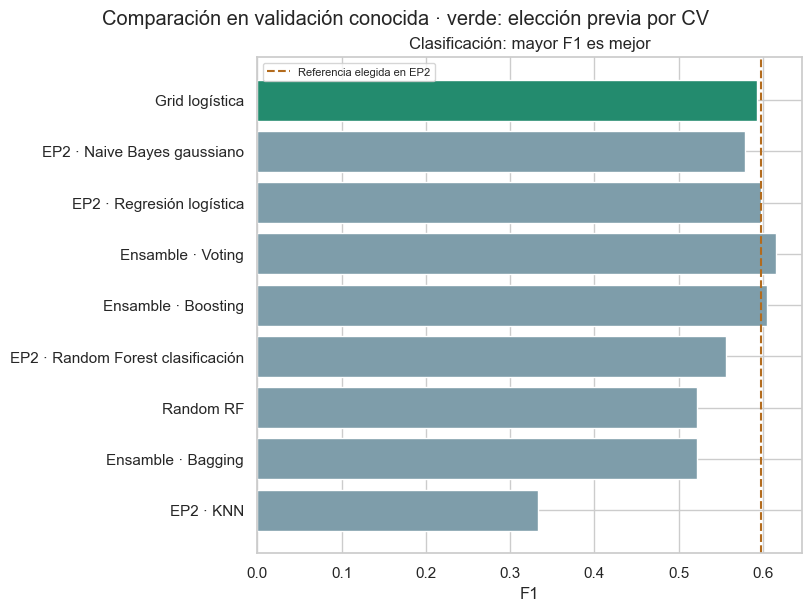

**Lectura:** elegimos por CV **Clasificación · Grid logística**. En validación conocida, frente a la elección de EP2, el cambio de F1 es **-0.005** (positivo favorece). Si empeora, queda registrado: no se sustituye el ganador después de mirar esta tabla.

In [74]:


"""
# [FASE6 EVALUACION RESULTADOS]
# Ajuste final y comparación con el mismo presupuesto de EP2

f6_reg_models, f6_cls_models = {}, {}
f6_reg_val_rows, f6_cls_val_rows = [], []
f6_reg_val_predictions, f6_cls_val_scores = {}, {}
with threadpool_limits(limits=2):
    for name, estimator in f6_reg_estimators.items():
        model = make_model_pipeline(clone(estimator)).fit(X_train_fit, y_train_fit_reg)
        pred = np.asarray(model.predict(X_val), dtype=float)
        f6_reg_models[name], f6_reg_val_predictions[name] = model, pred
        f6_reg_val_rows.append({'modelo': name, **regression_scores(y_val_reg, pred)})
    for name, estimator in f6_cls_estimators.items():
        model = make_model_pipeline(clone(estimator)).fit(X_train_fit, y_train_fit_cls)
        score = positive_probability(model, X_val)
        f6_cls_models[name], f6_cls_val_scores[name] = model, score
        f6_cls_val_rows.append({'modelo': name, **classification_scores(y_val_cls, score >= .5, score)})
f6_reg_val = pd.DataFrame(f6_reg_val_rows).set_index('modelo').loc[f6_reg_cv.index]
f6_cls_val = pd.DataFrame(f6_cls_val_rows).set_index('modelo').loc[f6_cls_cv.index]
f6_reg_val['elegido_por_CV'] = f6_reg_val.index == f6_selected_reg
f6_cls_val['elegido_por_CV'] = f6_cls_val.index == f6_selected_cls
pd.DataFrame({'row_id': X_val.index, 'real': y_val_reg.to_numpy(), **f6_reg_val_predictions}).to_csv(
    F6_DIR / 'predicciones_regresion_validacion.csv', index=False)
pd.DataFrame({'row_id': X_val.index, 'real': y_val_cls.astype(int).to_numpy(), **f6_cls_val_scores}).to_csv(
    F6_DIR / 'scores_clasificacion_validacion.csv', index=False)
f6_reg_reference, f6_cls_reference = 'EP2 · ' + selected_reg_name, 'EP2 · ' + selected_cls_name
f6_reg_val['cambio_MAE_vs_EP2'] = f6_reg_val.MAE - f6_reg_val.loc[f6_reg_reference, 'MAE']
f6_cls_val['cambio_F1_vs_EP2'] = f6_cls_val.F1 - f6_cls_val.loc[f6_cls_reference, 'F1']
f6_reg_val.to_csv(F6_DIR / 'comparacion_regresion_validacion.csv')
f6_cls_val.to_csv(F6_DIR / 'comparacion_clasificacion_validacion.csv')
display(Markdown('**Validación conocida · ajuste con 16.000 canciones. El orden sigue el criterio de CV.**'))
display(f6_reg_val[['MAE', 'RMSE', 'R2', 'cambio_MAE_vs_EP2', 'elegido_por_CV']].round(3))
display(f6_cls_val[['F1', 'Precision', 'Recall', 'ROC_AUC', 'AP', 'cambio_F1_vs_EP2', 'elegido_por_CV']].round(3))
fig, axes = plt.subplots(1, 2, figsize=(14, 6), layout='constrained')
for ax, table, metric, selected, reference, title in [
    (axes[0], f6_reg_val, 'MAE', f6_selected_reg, f6_reg_reference, 'Regresión: menor MAE es mejor'),
    (axes[1], f6_cls_val, 'F1', f6_selected_cls, f6_cls_reference, 'Clasificación: mayor F1 es mejor')]:
    labels = [name.replace('Regresión · ', '').replace('Clasificación · ', '') for name in table.index]
    colors = ['#238B6E' if name == selected else '#7E9DAA' for name in table.index]
    ax.barh(labels, table[metric], color=colors)
    ax.invert_yaxis()
    ax.axvline(table.loc[reference, metric], ls='--', color='#B36B1D', label='Referencia elegida en EP2')
    ax.set(title=title, xlabel=metric)
    ax.legend(fontsize=8)
fig.suptitle('Comparación en validación conocida · verde: elección previa por CV')
fig.savefig(F6_DIR / 'comparacion_mejoras.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)
f6_delta_mae = float(f6_reg_val.loc[f6_selected_reg, 'cambio_MAE_vs_EP2'])
f6_delta_f1 = float(f6_cls_val.loc[f6_selected_cls, 'cambio_F1_vs_EP2'])
display(Markdown(f'**Lectura:** elegimos por CV **{f6_selected_reg}** y **{f6_selected_cls}**. '
    f'En validación conocida, frente a las elecciones de EP2, el cambio de MAE es **{f6_delta_mae:+.3f}** '
    f'(negativo favorece) y el de F1 es **{f6_delta_f1:+.3f}** (positivo favorece). '
    'Si alguno empeora, queda registrado: no se sustituye el ganador después de mirar esta tabla.'))
assert f6_selection['regression'] == f6_selected_reg and f6_selection['classification'] == f6_selected_cls
assert len(f6_reg_models) == len(f6_cls_models) == 9

"""


# [FASE6 EVALUACION RESULTADOS]
# Ajuste final y comparación con el mismo presupuesto de EP2

f6_cls_models = {}
f6_cls_val_rows = []
f6_cls_val_scores = {}

with threadpool_limits(limits=2):
    for name, estimator in f6_cls_estimators.items():
        model = make_model_pipeline(clone(estimator)).fit(X_train_fit, y_train_fit_cls)
        score = positive_probability(model, X_val)
        f6_cls_models[name], f6_cls_val_scores[name] = model, score
        f6_cls_val_rows.append({'modelo': name, **classification_scores(y_val_cls, score >= .5, score)})

f6_cls_val = pd.DataFrame(f6_cls_val_rows).set_index('modelo').loc[f6_cls_cv.index]
f6_cls_val['elegido_por_CV'] = f6_cls_val.index == f6_selected_cls


f6_cls_reference = 'EP2 · ' + selected_cls_name
f6_cls_val['cambio_F1_vs_EP2'] = f6_cls_val.F1 - f6_cls_val.loc[f6_cls_reference, 'F1']

display(Markdown('**Validación conocida · ajuste con 16.000 canciones. El orden sigue el criterio de CV.**'))
display(f6_cls_val[['F1', 'Precision', 'Recall', 'ROC_AUC', 'AP', 'cambio_F1_vs_EP2', 'elegido_por_CV']].round(3))

fig, ax = plt.subplots(figsize=(8, 6), layout='constrained')

table = f6_cls_val
metric = 'F1'
selected = f6_selected_cls
reference = f6_cls_reference
title = 'Clasificación: mayor F1 es mejor'

labels = [name.replace('Clasificación · ', '') for name in table.index]
colors = ['#238B6E' if name == selected else '#7E9DAA' for name in table.index]

ax.barh(labels, table[metric], color=colors)
ax.invert_yaxis()
ax.axvline(table.loc[reference, metric], ls='--', color='#B36B1D', label='Referencia elegida en EP2')
ax.set(title=title, xlabel=metric)
ax.legend(fontsize=8)

fig.suptitle('Comparación en validación conocida · verde: elección previa por CV')
fig.savefig(F6_DIR / 'comparacion_mejoras_clasificacion.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

f6_delta_f1 = float(f6_cls_val.loc[f6_selected_cls, 'cambio_F1_vs_EP2'])

display(Markdown(f'**Lectura:** elegimos por CV **{f6_selected_cls}**. '
    f'En validación conocida, frente a la elección de EP2, el cambio de F1 es **{f6_delta_f1:+.3f}** (positivo favorece). '
    'Si empeora, queda registrado: no se sustituye el ganador después de mirar esta tabla.'))

assert f6_selection['classification'] == f6_selected_cls



### Qué aporta cada ensamble y qué falta interpretar
> [FASE6] [ANALISIS] [ENSAMBLES]

**Bagging** ajusta árboles sobre muestras distintas y combina sus respuestas: puede reducir la variación de un árbol, aunque no corrige por sí solo los sesgos de los datos. **Boosting** construye árboles de forma secuencial para corregir errores anteriores, más iteraciones no aseguran que generalice mejor.
**Voting** combina modelos diferentes con el mismo peso, para no favorecer uno sin una comparación previa. En clasificación promedia
scores y mantiene umbral 0,5, esto no significa que las probabilidades estén calibradas.

La tabla de CV y la tabla de validación responden preguntas distintas: la primera orienta la elección en entrenamiento, la segunda muestra qué ocurrió al ajustar con 16.000 canciones. Comparar una CV con entrenamiento más pequeño contra una métrica antigua de validación mezclaría condiciones.
Por eso incluimos las referencias EP2 en los mismos pliegues y luego usamos el mismo presupuesto final.
La desviación entre tres pliegues muestra variación, pero no es un intervalo de confianza.
Una mejora pequeña debe leerse junto con los errores, el coste de cálculo y las limitaciones de los datos.

### Validación Leave-P-Out

> [FASE6] [VALIDACION] [LEAVE_P_OUT]

También aplicamos **LeavePOut(p=2)**: dejamos fuera cada pareja posible y volvemos a ajustar con las demás canciones. En 16.000 canciones serían **127.992.000 particiones por modelo**.
Por ese costo usamos 32 canciones tomadas solo de entrenamiento, conservando aproximadamente la proporción popular. Recorremos sus **496 particiones completas**, no una selección de parejas.

Aquí usamos referencias sencillas, lineal y logística, con los diez atributos acústicos.
La imputación y el escalado se aprenden de nuevo en cada partición. Cada canción recibe 31 predicciones sin haber participado en esos ajustes, mostramos métricas al promediarlas por canción y la variación del MAE entre parejas. La variación es descriptiva, no un intervalo de confianza.
**Este ejercicio muestra sensibilidad en una muestra pequeña y no decide el modelo final.**
La comparación principal sigue siendo la validación cruzada sobre la muestra de búsqueda común.

In [75]:
""" 


# [FASE6 VALIDACION LEAVE_P_OUT RESULTADOS]
# LeavePOut completo sobre una muestra pequeña de entrenamiento

from math import comb
from sklearn.model_selection import LeavePOut

f6_lpo_ids, _ = train_test_split(
    X_train_fit.index.to_numpy(), train_size=32,
    stratify=y_train_fit_cls.to_numpy(), random_state=RANDOM_STATE + 6)
f6_lpo_X = X_train_fit.loc[f6_lpo_ids].copy()
f6_lpo_reg_y = y_train_fit_reg.loc[f6_lpo_ids].to_numpy(dtype=float)
f6_lpo_cls_y = y_train_fit_cls.loc[f6_lpo_ids].to_numpy(dtype=int)
assert set(f6_lpo_ids).issubset(X_train_fit.index) and not set(f6_lpo_ids) & set(X_val.index)
assert np.bincount(f6_lpo_cls_y).min() > 2

def f6_lpo_pipeline(estimator):
    # Solo audio: tamaño de muestra pequeño y referencias distintas del ranking principal.
    return Pipeline([
        ('features', FeatureBuilder(engineered=False)),
        ('prepare', ColumnTransformer([
            ('audio', Pipeline([('impute', SimpleImputer(strategy='median')),
                                ('scale', StandardScaler())]), AUDIO_COLUMNS + ['log_duration_min'])])),
        ('model', estimator),
    ])

f6_lpo_templates = {
    'reg': f6_lpo_pipeline(LinearRegression()),
    'cls': f6_lpo_pipeline(LogisticRegression(C=.1, class_weight='balanced',
                                             max_iter=2000, random_state=RANDOM_STATE)),
}
f6_lpo = LeavePOut(p=2)
f6_lpo_rows, f6_lpo_fold_rows = [], []
with threadpool_limits(limits=2):
    for fold, (inside, outside) in enumerate(f6_lpo.split(f6_lpo_X), start=1):
        reg = clone(f6_lpo_templates['reg']).fit(f6_lpo_X.iloc[inside], f6_lpo_reg_y[inside])
        cls = clone(f6_lpo_templates['cls']).fit(f6_lpo_X.iloc[inside], f6_lpo_cls_y[inside])
        reg_pred = reg.predict(f6_lpo_X.iloc[outside])
        positive_col = int(np.flatnonzero(cls.classes_ == 1)[0])
        cls_score = cls.predict_proba(f6_lpo_X.iloc[outside])[:, positive_col]
        f6_lpo_fold_rows.append({'fold': fold, 'train_songs': len(inside), 'held_out': len(outside),
            'MAE': mean_absolute_error(f6_lpo_reg_y[outside], reg_pred)})
        for position, pred, score in zip(outside, reg_pred, cls_score):
            f6_lpo_rows.append({'fold': fold, 'row_id': int(f6_lpo_ids[position]),
                'popularity': f6_lpo_reg_y[position], 'is_popular': f6_lpo_cls_y[position],
                'prediction': float(pred), 'score': float(score)})
f6_lpo_predictions = pd.DataFrame(f6_lpo_rows)
f6_lpo_folds = pd.DataFrame(f6_lpo_fold_rows)
assert len(f6_lpo_folds) == comb(32, 2) == 496
assert f6_lpo_predictions.groupby('row_id').size().eq(31).all()
f6_lpo_song = f6_lpo_predictions.groupby('row_id').agg(
    popularity=('popularity', 'first'), is_popular=('is_popular', 'first'),
    prediction=('prediction', 'mean'), score=('score', 'mean'), predictions=('fold', 'size'))
f6_lpo_summary = pd.DataFrame([
    {'referencia': 'Lineal · audio', **regression_scores(f6_lpo_song.popularity, f6_lpo_song.prediction)},
    {'referencia': 'Logística · audio', **classification_scores(
        f6_lpo_song.is_popular, f6_lpo_song.score.ge(.5), f6_lpo_song.score)},
])
f6_lpo_predictions.to_csv(F6_DIR / 'leave_p_out_predictions.csv', index=False)
f6_lpo_folds.to_csv(F6_DIR / 'leave_p_out_folds.csv', index=False)
f6_lpo_song.to_csv(F6_DIR / 'leave_p_out_song_means.csv')
f6_lpo_summary.to_csv(F6_DIR / 'leave_p_out_summary.csv', index=False)
f6_lpo_protocol = {'p': 2, 'sample_songs': 32, 'partitions': len(f6_lpo_folds),
    'partitions_full_fit_train_per_model': comb(len(X_train_fit), 2),
    'sample_source': 'X_train_fit', 'seed': RANDOM_STATE + 6,
    'positive_songs': int(f6_lpo_cls_y.sum()), 'preprocessing_fitted_in_each_split': True,
    'features': AUDIO_COLUMNS + ['log_duration_min'], 'used_for_selection': False,
    'aggregation': '31 out-of-fit predictions per song, averaged before scoring',
    'fold_MAE_mean': float(f6_lpo_folds.MAE.mean()),
    'fold_MAE_std': float(f6_lpo_folds.MAE.std(ddof=1))}
(F6_DIR / 'leave_p_out_protocol.json').write_text(
    json.dumps(f6_lpo_protocol, ensure_ascii=False, indent=2), encoding='utf-8')
display(f6_lpo_summary[['referencia', 'MAE', 'RMSE', 'R2', 'F1', 'ROC_AUC', 'AP']].round(3))
print(f"LPO: {len(f6_lpo_folds)} parejas, 31 predicciones por canción; "
      f"MAE entre parejas {f6_lpo_folds.MAE.mean():.3f} ± {f6_lpo_folds.MAE.std(ddof=1):.3f} (DE).")"""

# [FASE6 VALIDACION LEAVE_P_OUT RESULTADOS]
# LeavePOut completo sobre una muestra pequeña de entrenamiento

from math import comb
from sklearn.model_selection import LeavePOut

f6_lpo_ids, _ = train_test_split(
    X_train_fit.index.to_numpy(), train_size=32,
    stratify=y_train_fit_cls.to_numpy(), random_state=RANDOM_STATE + 6)
f6_lpo_X = X_train_fit.loc[f6_lpo_ids].copy()
f6_lpo_cls_y = y_train_fit_cls.loc[f6_lpo_ids].to_numpy(dtype=int)

assert set(f6_lpo_ids).issubset(X_train_fit.index) and not set(f6_lpo_ids) & set(X_val.index)
assert np.bincount(f6_lpo_cls_y).min() > 2

def f6_lpo_pipeline(estimator):
    # Solo audio: tamaño de muestra pequeño y referencias distintas del ranking principal.
    return Pipeline([
        ('features', FeatureBuilder(engineered=False)),
        ('prepare', ColumnTransformer([
            ('audio', Pipeline([('impute', SimpleImputer(strategy='median')),
                                ('scale', StandardScaler())]), AUDIO_COLUMNS + ['log_duration_min'])])),
        ('model', estimator),
    ])

f6_lpo_templates = {
    'cls': f6_lpo_pipeline(LogisticRegression(C=.1, class_weight='balanced',
                                              max_iter=2000, random_state=RANDOM_STATE)),
}

f6_lpo = LeavePOut(p=2)
f6_lpo_rows, f6_lpo_fold_rows = [], []

with threadpool_limits(limits=2):
    for fold, (inside, outside) in enumerate(f6_lpo.split(f6_lpo_X), start=1):
        cls = clone(f6_lpo_templates['cls']).fit(f6_lpo_X.iloc[inside], f6_lpo_cls_y[inside])
        positive_col = int(np.flatnonzero(cls.classes_ == 1)[0])
        cls_score = cls.predict_proba(f6_lpo_X.iloc[outside])[:, positive_col]
        
        f6_lpo_fold_rows.append({'fold': fold, 'train_songs': len(inside), 'held_out': len(outside)})
        
        for position, score in zip(outside, cls_score):
            f6_lpo_rows.append({'fold': fold, 'row_id': int(f6_lpo_ids[position]),
                'is_popular': f6_lpo_cls_y[position], 'score': float(score)})

f6_lpo_predictions = pd.DataFrame(f6_lpo_rows)
f6_lpo_folds = pd.DataFrame(f6_lpo_fold_rows)

assert len(f6_lpo_folds) == comb(32, 2) == 496
assert f6_lpo_predictions.groupby('row_id').size().eq(31).all()

f6_lpo_song = f6_lpo_predictions.groupby('row_id').agg(
    is_popular=('is_popular', 'first'),
    score=('score', 'mean'), predictions=('fold', 'size'))

f6_lpo_summary = pd.DataFrame([
    {'referencia': 'Logística · audio', **classification_scores(
        f6_lpo_song.is_popular, f6_lpo_song.score.ge(.5), f6_lpo_song.score)},
])


f6_lpo_protocol = {'p': 2, 'sample_songs': 32, 'partitions': len(f6_lpo_folds),
    'partitions_full_fit_train_per_model': comb(len(X_train_fit), 2),
    'sample_source': 'X_train_fit', 'seed': RANDOM_STATE + 6,
    'positive_songs': int(f6_lpo_cls_y.sum()), 'preprocessing_fitted_in_each_split': True,
    'features': AUDIO_COLUMNS + ['log_duration_min'], 'used_for_selection': False,
    'aggregation': '31 out-of-fit predictions per song, averaged before scoring'}

(F6_DIR / 'leave_p_out_protocol.json').write_text(
    json.dumps(f6_lpo_protocol, ensure_ascii=False, indent=2), encoding='utf-8')

display(f6_lpo_summary[['referencia', 'F1', 'ROC_AUC', 'AP']].round(3))
print(f"LPO: {len(f6_lpo_folds)} parejas, 31 predicciones por canción promediadas.")

,referencia,F1,ROC_AUC,AP
0,Logística · audio,0.0,0.094,0.16


LPO: 496 parejas, 31 predicciones por canción promediadas.


### Posibles sesgos y diferencias entre grupos

> [FASE6] [SESGOS] [LIMITES]

Revisamos los modelos elegidos en **validación**, separados por contenido explícito, cantidad de artistas y presencia de artistas ya vistos en el entrenamiento usado.
Contamos los artistas con el separador `;`: compartir género no significa compartir artista.

Las tablas muestran tamaño y proporción popular de cada grupo. Solo calculamos métricas en grupos con al menos 50 canciones, ROC-AUC y AP quedan vacíos si falta una clase.
Una diferencia entre grupos puede venir de tamaño, distribución o información disponible, no demuestra por sí sola discriminación ni una causa. El objetivo es reconocer dónde falla más.

In [76]:
"""AUDIO_COLUMNS


# [FASE6 SESGOS RESULTADOS]
# Resultados por grupo y artistas compartidos

def f6_artist_set(value):
    return {artist.strip().casefold() for artist in str(value).split(';') if artist.strip()}

f6_train_artists = set().union(*X_train_fit.artists.map(f6_artist_set))
f6_val_artist_sets = X_val.artists.map(f6_artist_set)
f6_val_artists = set().union(*f6_val_artist_sets)
f6_seen_artist = f6_val_artist_sets.map(lambda artists: bool(artists & f6_train_artists))
f6_artist_audit = {
    'artists_in_fit_train': len(f6_train_artists), 'artists_in_validation': len(f6_val_artists),
    'shared_artist_names': len(f6_train_artists & f6_val_artists),
    'validation_songs_with_seen_artist': int(f6_seen_artist.sum()),
    'validation_songs_with_seen_artist_pct': float(100 * f6_seen_artist.mean()),
    'identity_rule': 'Normalized names separated by semicolon; not unique artist IDs',
}
(F6_DIR / 'artist_overlap.json').write_text(
    json.dumps(f6_artist_audit, ensure_ascii=False, indent=2), encoding='utf-8')
f6_bias_reg_pred = np.asarray(f6_reg_val_predictions[f6_selected_reg], dtype=float)
f6_bias_score = np.asarray(f6_cls_val_scores[f6_selected_cls], dtype=float)
f6_bias_data = pd.DataFrame({
    'real': np.asarray(y_val_reg), 'popular': np.asarray(y_val_cls, dtype=int),
    'pred': f6_bias_reg_pred, 'score': f6_bias_score,
    'Contenido': np.where(X_val.explicit, 'Explícito', 'No explícito'),
    'Participación': np.where(f6_val_artist_sets.map(len).gt(1), 'Varios artistas', 'Un artista'),
    'Artistas': np.where(f6_seen_artist, 'Algún artista visto', 'Ningún artista visto'),
}, index=X_val.index)
f6_bias_rows = []
for dimension in ['Contenido', 'Participación', 'Artistas']:
    for label, group in f6_bias_data.groupby(dimension, sort=False):
        row = {'dimensión': dimension, 'grupo': label, 'canciones': len(group),
               'populares': int(group.popular.sum()), 'popular_pct': 100 * group.popular.mean(),
               'base_suficiente': len(group) >= 50}
        if len(group) >= 50:
            pred = group.score.ge(.5)
            row.update(regression_scores(group.real, group.pred))
            row.update({'F1': f1_score(group.popular, pred, zero_division=0),
                'Precision': precision_score(group.popular, pred, zero_division=0),
                'Recall': recall_score(group.popular, pred, zero_division=0),
                'ROC_AUC': roc_auc_score(group.popular, group.score) if group.popular.nunique() == 2 else np.nan,
                'AP': average_precision_score(group.popular, group.score) if group.popular.nunique() == 2 else np.nan})
        f6_bias_rows.append(row)
f6_bias_table = pd.DataFrame(f6_bias_rows)
f6_bias_table.to_csv(F6_DIR / 'bias_validation.csv', index=False)
f6_bias_data.to_csv(F6_DIR / 'bias_validation_predictions.csv', index_label='row_id')
display(f6_bias_table[['dimensión', 'grupo', 'canciones', 'popular_pct',
                       'MAE', 'R2', 'F1', 'Precision', 'Recall', 'ROC_AUC', 'AP']].round(3))
print(f"Validación con algún artista presente en el ajuste: {f6_seen_artist.mean():.1%}. "
      "La separación por canción no mide directamente el rendimiento en artistas nuevos.")
"""
# [FASE6 SESGOS RESULTADOS]
# Resultados por grupo y artistas compartidos

def f6_artist_set(value):
    return {artist.strip().casefold() for artist in str(value).split(';') if artist.strip()}

f6_train_artists = set().union(*X_train_fit.artists.map(f6_artist_set))
f6_val_artist_sets = X_val.artists.map(f6_artist_set)
f6_val_artists = set().union(*f6_val_artist_sets)
f6_seen_artist = f6_val_artist_sets.map(lambda artists: bool(artists & f6_train_artists))
f6_artist_audit = {
    'artists_in_fit_train': len(f6_train_artists), 'artists_in_validation': len(f6_val_artists),
    'shared_artist_names': len(f6_train_artists & f6_val_artists),
    'validation_songs_with_seen_artist': int(f6_seen_artist.sum()),
    'validation_songs_with_seen_artist_pct': float(100 * f6_seen_artist.mean()),
    'identity_rule': 'Normalized names separated by semicolon; not unique artist IDs',
}
(F6_DIR / 'artist_overlap.json').write_text(
    json.dumps(f6_artist_audit, ensure_ascii=False, indent=2), encoding='utf-8')

f6_bias_score = np.asarray(f6_cls_val_scores[f6_selected_cls], dtype=float)
f6_bias_data = pd.DataFrame({
    'popular': np.asarray(y_val_cls, dtype=int),
    'score': f6_bias_score,
    'Contenido': np.where(X_val.explicit, 'Explícito', 'No explícito'),
    'Participación': np.where(f6_val_artist_sets.map(len).gt(1), 'Varios artistas', 'Un artista'),
    'Artistas': np.where(f6_seen_artist, 'Algún artista visto', 'Ningún artista visto'),
}, index=X_val.index)

f6_bias_rows = []
for dimension in ['Contenido', 'Participación', 'Artistas']:
    for label, group in f6_bias_data.groupby(dimension, sort=False):
        row = {'dimensión': dimension, 'grupo': label, 'canciones': len(group),
               'populares': int(group.popular.sum()), 'popular_pct': 100 * group.popular.mean(),
               'base_suficiente': len(group) >= 50}
        if len(group) >= 50:
            pred = group.score.ge(.5)
            row.update({'F1': f1_score(group.popular, pred, zero_division=0),
                'Precision': precision_score(group.popular, pred, zero_division=0),
                'Recall': recall_score(group.popular, pred, zero_division=0),
                'ROC_AUC': roc_auc_score(group.popular, group.score) if group.popular.nunique() == 2 else np.nan,
                'AP': average_precision_score(group.popular, group.score) if group.popular.nunique() == 2 else np.nan})
        f6_bias_rows.append(row)

f6_bias_table = pd.DataFrame(f6_bias_rows)


display(f6_bias_table[['dimensión', 'grupo', 'canciones', 'popular_pct',
                       'F1', 'Precision', 'Recall', 'ROC_AUC', 'AP']].round(3))
print(f"Validación con algún artista presente en el ajuste: {f6_seen_artist.mean():.1%}. "
      "La separación por canción no mide directamente el rendimiento en artistas nuevos.")


,dimensión,grupo,canciones,popular_pct,F1,Precision,Recall,ROC_AUC,AP
0,Contenido,No explícito,16255,22.719,0.587,0.466,0.791,0.842,0.609
1,Contenido,Explícito,1549,32.731,0.635,0.518,0.821,0.800,0.609
2,Participación,Un artista,13268,22.046,0.583,0.462,0.789,0.844,0.586
3,Participación,Varios artistas,4536,28.108,0.616,0.497,0.809,0.824,0.659
4,Artistas,Algún artista visto,13461,23.394,0.596,0.482,0.782,0.844,0.619
5,Artistas,Ningún artista visto,4343,24.200,0.582,0.448,0.833,0.826,0.588


Validación con algún artista presente en el ajuste: 75.6%. La separación por canción no mide directamente el rendimiento en artistas nuevos.


### Qué límites tienen estos resultados
> [FASE6] [ETICA] [RECOMENDACIONES]


La popularidad puede reflejar promoción, exposición y el momento de la captura, además del audio.
No tenemos esas variables y no debemos interpretar el puntaje como calidad artística.
La distribución de este catálogo tampoco representa toda la música ni todas las audiencias.

Hay artistas compartidos entre particiones: evitamos canciones duplicadas, pero eso no garantiza generalización a artistas nuevos. La tabla separa casos vistos y nuevos, para ese uso convendría una evaluación posterior separada por artista y, si hay fechas disponibles, por tiempo.
Los nombres son una aproximación a la identidad, porque el archivo no incluye IDs de artista.

Los agrupamientos describen similitudes, no géneros verdaderos ni preferencias de personas.


Las recomendaciones se limitan a comparar modelos y señalar errores y diferencias observadas, La decisión editorial sigue requiriendo criterio humano ya que no afirmamos mejoras de reproducciones o ingresos.

### Comparación final con la referencia base

> [RESULTADOS] [SELECCION]

La elección ya quedó fijada por CV. Comparamos esa selección con el modelo base en las mismas 8.000 canciones de reserva. La prueba conocida se muestra como diagnóstico retrospectivo.
Un resultado peor también cuenta: no vamos a cambiar la regla solo para mostrar una mejora.
Los indicadores de la lista de 500 usan la etiqueta popular como referencia, no aceptación editorial.

,particion,tarea,rol,modelo,canciones,Accuracy,BalancedAccuracy,Precision,Recall,F1,ROC_AUC,AP
0,Reserva adicional,Clasificación,Base EP2,Regresión logística,8000,0.7434,0.7548,0.4732,0.7764,0.5880,0.8331,0.5807
1,Reserva adicional,Clasificación,Selección CV EP3,Clasificación · Grid logística,8000,0.7365,0.7571,0.4657,0.7960,0.5876,0.8345,0.5930
2,Prueba conocida,Clasificación,Base EP2,Regresión logística,17804,0.7481,0.7581,0.4790,0.7771,0.5927,0.8335,0.5827
3,Prueba conocida,Clasificación,Selección CV EP3,Clasificación · Grid logística,17804,0.7392,0.7589,0.4689,0.7961,0.5902,0.8356,0.5954


,modelo,rol,k,populares_en_lista,Precision@500,Recall@500,Lift@500,prevalencia
0,Regresión logística,Base EP2,500,353,0.706,0.1871,2.9931,0.2359
1,Clasificación · Grid logística,Selección CV EP3,500,351,0.702,0.1860,2.9762,0.2359


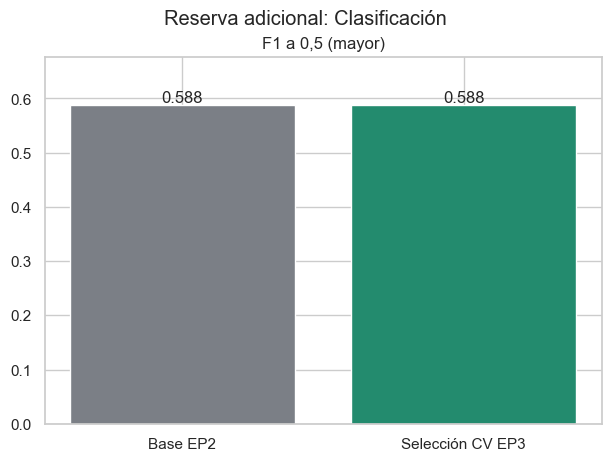

En la reserva, el cambio de F1 es **-0.0004**. Un valor negativo indica que la propuesta empeoró ese criterio. La selección se mantiene registrada aunque el resultado no sea el esperado.

In [77]:
"""# [FASE6 RESULTADOS]
# Reserva adicional, prueba conocida e indicadores de la lista
f6_final_rows, f6_queue_rows, f6_predictions = [], [], []
for part, xx, yr, yc in [('Reserva adicional', f6_X_reserve, f6_y_reserve_reg, f6_y_reserve_cls),
                          ('Prueba conocida', X_test, y_test_reg, y_test_cls)]:
    for task, choices in [
        ('Regresión', [('Base EP2',selected_reg_name,reg_fitted[selected_reg_name]),
                       ('Selección CV EP3',f6_selected_reg,f6_reg_models[f6_selected_reg])]),
        ('Clasificación',[('Base EP2',selected_cls_name,cls_fitted[selected_cls_name]),
                          ('Selección CV EP3',f6_selected_cls,f6_cls_models[f6_selected_cls])])]:
        for role, name, model in choices:
            if task == 'Regresión':
                pred = np.asarray(model.predict(xx),dtype=float)
                scores = regression_scores(yr,pred)
            else:
                pred = positive_probability(model,xx)
                scores = classification_scores(yc,pred>=.5,pred)
                if part == 'Reserva adicional':
                    order = np.argsort(-pred,kind='stable')[:500]
                    hits = int(np.asarray(yc,dtype=int)[order].sum())
                    f6_queue_rows.append({'modelo':name,'rol':role,'k':500,'populares_en_lista':hits,
                        'Precision@500':hits/500,'Recall@500':hits/int(np.sum(yc)),
                        'Lift@500':(hits/500)/float(np.mean(yc)),'prevalencia':float(np.mean(yc))})
            f6_final_rows.append({'particion':part,'tarea':task,'rol':role,'modelo':name,'canciones':len(xx),**scores})
            f6_predictions.append(pd.DataFrame({'row_id':xx.index,'track_id':df_model.loc[xx.index,'track_id'].to_numpy(),
                'particion':part,'tarea':task,'rol':role,'modelo':name,
                'real':np.asarray(yr if task=='Regresión' else yc,dtype=float),'score':pred}))
f6_final = pd.DataFrame(f6_final_rows)
f6_queue = pd.DataFrame(f6_queue_rows)
f6_final.to_csv(F6_DIR/'evaluacion_final.csv',index=False)
f6_queue.to_csv(F6_DIR/'indicadores_lista500.csv',index=False)
pd.concat(f6_predictions,ignore_index=True).to_csv(F6_DIR/'predicciones_finales.csv',index=False)
display(f6_final.round(4))
display(f6_queue.round(4))
f6_res_r = f6_final.query("particion=='Reserva adicional' and tarea=='Regresión'").set_index('rol')
f6_res_c = f6_final.query("particion=='Reserva adicional' and tarea=='Clasificación'").set_index('rol')
f6_mae_change = 100*(1-f6_res_r.loc['Selección CV EP3','MAE']/f6_res_r.loc['Base EP2','MAE'])
f6_f1_change = f6_res_c.loc['Selección CV EP3','F1']-f6_res_c.loc['Base EP2','F1']
fig, axes = plt.subplots(1,3,figsize=(14,4.5),layout='constrained')
for ax,frame,metric,title in [(axes[0],f6_res_r,'MAE','Error medio (menor)'),
                              (axes[1],f6_res_r,'R2','R² (mayor)'),
                              (axes[2],f6_res_c,'F1','F1 a 0,5 (mayor)')]:
    ax.bar(['Base EP2','Selección CV EP3'],frame.loc[['Base EP2','Selección CV EP3'],metric],color=['#7b7f86','#238b6e'])
    for pos,role in enumerate(['Base EP2','Selección CV EP3']):
        val=frame.loc[role,metric];ax.text(pos,val,f'{val:.3f}',ha='center',va='bottom')
    ax.set(title=title);ax.margins(y=.15)
fig.suptitle('Reserva adicional: mismo conjunto para las dos versiones')
fig.savefig(F6_DIR/'comparacion_final.png',dpi=150,bbox_inches='tight');plt.show();plt.close(fig)
display(Markdown(f'En la reserva, el cambio de MAE es **{f6_mae_change:+.2f}% de reducción** '
    f'y el de F1 es **{f6_f1_change:+.4f}**. Un valor negativo indica que la propuesta empeoró ese criterio. '
    'La selección se mantiene registrada aunque el resultado no sea el esperado.'))"""

# [FASE6 RESULTADOS]
# Reserva adicional, prueba conocida e indicadores de la lista
f6_final_rows, f6_queue_rows, f6_predictions = [], [], []

for part, xx, yc in [('Reserva adicional', f6_X_reserve, f6_y_reserve_cls),
                     ('Prueba conocida', X_test, y_test_cls)]:
    for task, choices in [
        ('Clasificación', [('Base EP2', selected_cls_name, cls_fitted[selected_cls_name]),
                           ('Selección CV EP3', f6_selected_cls, f6_cls_models[f6_selected_cls])])]:
        for role, name, model in choices:
            pred = positive_probability(model, xx)
            scores = classification_scores(yc, pred >= .5, pred)
            
            if part == 'Reserva adicional':
                order = np.argsort(-pred, kind='stable')[:500]
                hits = int(np.asarray(yc, dtype=int)[order].sum())
                f6_queue_rows.append({'modelo': name, 'rol': role, 'k': 500, 'populares_en_lista': hits,
                    'Precision@500': hits/500, 'Recall@500': hits/int(np.sum(yc)),
                    'Lift@500': (hits/500)/float(np.mean(yc)), 'prevalencia': float(np.mean(yc))})
            
            f6_final_rows.append({'particion': part, 'tarea': task, 'rol': role, 'modelo': name, 'canciones': len(xx), **scores})
            f6_predictions.append(pd.DataFrame({'row_id': xx.index, 'track_id': df_model.loc[xx.index, 'track_id'].to_numpy(),
                'particion': part, 'tarea': task, 'rol': role, 'modelo': name,
                'real': np.asarray(yc, dtype=float), 'score': pred}))

f6_final = pd.DataFrame(f6_final_rows)
f6_queue = pd.DataFrame(f6_queue_rows)



display(f6_final.round(4))
display(f6_queue.round(4))

f6_res_c = f6_final.query("particion=='Reserva adicional' and tarea=='Clasificación'").set_index('rol')
f6_f1_change = f6_res_c.loc['Selección CV EP3', 'F1'] - f6_res_c.loc['Base EP2', 'F1']

fig, ax = plt.subplots(figsize=(6, 4.5), layout='constrained')
metric = 'F1'
title = 'F1 a 0,5 (mayor)'

ax.bar(['Base EP2', 'Selección CV EP3'], f6_res_c.loc[['Base EP2', 'Selección CV EP3'], metric], color=['#7b7f86', '#238b6e'])
for pos, role in enumerate(['Base EP2', 'Selección CV EP3']):
    val = f6_res_c.loc[role, metric]
    ax.text(pos, val, f'{val:.3f}', ha='center', va='bottom')
ax.set(title=title)
ax.margins(y=.15)

fig.suptitle('Reserva adicional: Clasificación')
fig.savefig(F6_DIR / 'comparacion_final_clasificacion.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

display(Markdown(f'En la reserva, el cambio de F1 es **{f6_f1_change:+.4f}**. '
    'Un valor negativo indica que la propuesta empeoró ese criterio. '
    'La selección se mantiene registrada aunque el resultado no sea el esperado.'))

### Conclusiones y recomendaciones

> [CONCLUSIONES] [LIMITES]

Nuestra Fase 6 permite comparar tres cosas distintas: el modelo base, el ajuste de parámetros y las técnicas de ensamble. El resultado debe leerse junto con la métrica elegida y la variación entre folds.
Que un ensamble sea más complejo no obliga a que funcione mejor.

**Lo que pasó en esta ejecución:** el SVR ajustado bajó el MAE de validación de 10,866 a 10,763.
Voting de clasificación subió F1 de 0,598 a 0,615 y Boosting a 0,605. Son mejoras en validación conocida, ninguno de esos dos candidatos ganó el criterio principal en la CV pequeña.
La elección por CV fue Voting de regresión y logística con C=10. En la reserva, Voting tuvo MAE 11,400 frente a 10,855 del SVR base, aunque mejoró R² de 0,389 a 0,419.
La logística ajustada pasó de F1 0,588 a 0,587. Por eso no podemos decir que la selección de EP3 superó a la base en los criterios principales. Para reemplazar la referencia todavía falta evidencia.

Una limitación concreta es el tamaño: cada fold ajustó con 4.000 canciones y el modelo final con 16.000. El orden puede cambiar porque los modelos aprovechan de manera distinta más datos.
La siguiente comparación debería usar una CV con un tamaño de ajuste más cercano al final.
No cambiamos ahora la selección ni volvemos a buscar con la reserva ya observada.

Para estimar popularidad mantenemos MAE como criterio y revisamos R²/RMSE. Para marcar canciones populares usamos F1 a 0,5, mirando también las omisiones y falsas alarmas. Para una lista ordenada, ROC-AUC, AP y los indicadores a 500 canciones responden una pregunta diferente.

K-Means conserva dos niveles útiles para explorar: dos grupos como referencia y siete para más detalle.
DBSCAN no cumple las reglas de cobertura y tamaños en la búsqueda realizada. PCA ayuda a reducir dimensiones, pero una silueta mayor en 2D no prueba que la separación musical sea mejor.

Recomendamos elegir según el uso, conservar el preprocesamiento junto al modelo y reportar también los casos donde no hubo mejora. Una captura más reciente y una separación estricta por artista permitirían revisar si el resultado se sostiene fuera de este catálogo. El trabajo termina con los
experimentos, las evidencias y sus límites.


PD: Los archivos de `models/` guardan los candidatos elegidos por CV, guardarlos no significa recomendar su reemplazo automático de los modelos base.

In [79]:
"""# [FASE6 CONCLUSIONES]
# Resumen calculado y modelos reproducibles
import cloudpickle
model_dir = PROJECT_ROOT/'models'
model_dir.mkdir(exist_ok=True)
for filename, model in [('regresion.pkl',f6_reg_models[f6_selected_reg]),
                         ('clasificacion.pkl',f6_cls_models[f6_selected_cls])]:
    with (model_dir/filename).open('wb') as handle: cloudpickle.dump(model,handle)
final_report = {'date':'2026-11-06','dataset_sha256':hashlib.sha256(ruta_csv.read_bytes()).hexdigest(),
    'base_reg':selected_reg_name,'base_cls':selected_cls_name,'selected_reg':f6_selected_reg,
    'selected_cls':f6_selected_cls,'selection_data':'CV de desarrollo, antes de reserva',
    'reserve':f6_reserve_protocol,'final_metrics':f6_final.to_dict('records'),
    'queue500':f6_queue.to_dict('records'),'mae_reduction_pct':float(f6_mae_change),
    'f1_difference':float(f6_f1_change),'clustering':rc_findings,
    'limits':['CV no anidada','catálogo conocido','artistas compartidos',
              'Leave-P-Out acotado a referencias en muestra pequeña','sin impacto comercial medido']}
(ROOT_OUTPUT/'resumen_EP3.json').write_text(json.dumps(rc_json_safe(final_report),ensure_ascii=False,
    indent=2,allow_nan=False),encoding='utf-8')
display(Markdown(f'**Selección por CV:** {f6_selected_reg} para regresión y {f6_selected_cls} para clasificación. '
    f'**Reserva adicional:** MAE={f6_res_r.loc["Selección CV EP3","MAE"]:.3f}, '
    f'R²={f6_res_r.loc["Selección CV EP3","R2"]:.3f}, '
    f'F1={f6_res_c.loc["Selección CV EP3","F1"]:.3f} y '
    f'ROC-AUC={f6_res_c.loc["Selección CV EP3","ROC_AUC"]:.3f}.'))
print('Resultados guardados en',ROOT_OUTPUT)"""

# [FASE6 CONCLUSIONES]
# Resumen calculado y modelos reproducibles
import cloudpickle
import hashlib
import json

model_dir = PROJECT_ROOT / 'models'
model_dir.mkdir(exist_ok=True)

for filename, model in [('clasificacion.pkl', f6_cls_models[f6_selected_cls])]:
    with (model_dir / filename).open('wb') as handle: 
        cloudpickle.dump(model, handle)

final_report = {
    'date': '2026-11-06',
    'base_cls': selected_cls_name,
    'selected_cls': f6_selected_cls,
    'selection_data': 'CV de desarrollo, antes de reserva',
    'reserve': f6_reserve_protocol,
    'final_metrics': f6_final.to_dict('records'),
    'queue500': f6_queue.to_dict('records'),
    'f1_difference': float(f6_f1_change),
    'clustering': rc_findings,
    'limits': [
        'CV no anidada', 'catálogo conocido', 'artistas compartidos',
        'Leave-P-Out acotado a referencias en muestra pequeña', 'sin impacto comercial medido'
    ]
}

(ROOT_OUTPUT / 'resumen_EP3.json').write_text(
    json.dumps(rc_json_safe(final_report), ensure_ascii=False, indent=2, allow_nan=False), 
    encoding='utf-8'
)

display(Markdown(f'**Selección por CV:** {f6_selected_cls} para clasificación. '
    f'**Reserva adicional:** F1={f6_res_c.loc["Selección CV EP3","F1"]:.3f} y '
    f'ROC-AUC={f6_res_c.loc["Selección CV EP3","ROC_AUC"]:.3f}.'))

print('Resultados guardados en', ROOT_OUTPUT)

**Selección por CV:** Clasificación · Grid logística para clasificación. **Reserva adicional:** F1=0.588 y ROC-AUC=0.834.

Resultados guardados en c:\Users\Telet\OneDrive\Escritorio\ML\outputs
